---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 15

- Suryani Mulia Utami (13524042)
- Muhammad Haris Putra Sulastianto (13524053)
- Steven Tan (13524060)
- Benedict Darrel Setiawan (13524057)
- Marcel Luther Sitorus (13524063)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview
Tugas Besar 2 IF3170 membahas prediksi pembatalan pemesanan penginapan menggunakan supervised learning. 
Persoalan ini termasuk dalam masalah klasifikasi biner, dengan is_canceled = 1 untuk pemesanan yang dibatalkan dan is_canceled = 0 untuk pemesanan yang tidak dibatalkan.

## Aim
Tujuan tugas ini adalah mengimplementasikan dan mengevaluasi lima algoritma klasifikasi *from scratch*, yaitu KNN, Decision Tree, Logistic Regression, SVM, dan Naive Bayes.

Hasil implementasi dibandingkan dengan scikit-learn untuk memeriksa kesesuaian hasil dan performa model. Eksperimen juga dilakukan untuk memilih konfigurasi yang sesuai sebelum menghasilkan prediksi untuk Kaggle.

## Metric
Metrik utama yang digunakan adalah **Macro F1**, yaitu rata-rata F1-score kedua kelas dengan bobot yang sama. Metrik ini digunakan agar evaluasi tidak terlalu didominasi oleh kelas mayoritas.

Sebagai pelengkap, digunakan accuracy, precision, recall, dan confusion matrix untuk memahami performa serta jenis kesalahan prediksi.

## Dataset
Dataset berisi informasi pemesanan penginapan dengan fitur numerik dan kategorikal, seperti jumlah tamu, waktu pemesanan, kanal pemesanan, serta harga per malam.

- Data latih: 27.373 observasi dengan label is_canceled.
- Data uji: 6.844 observasi tanpa label target.

Distribusi target tidak seimbang, dengan sekitar 67,23% pemesanan tidak dibatalkan dan 32,77% dibatalkan. Data juga memerlukan pembersihan dan transformasi sebelum digunakan untuk pemodelan.

## Approach

Pengerjaan dilakukan melalui tahapan berikut:

1. Data Understanding: Memeriksa karakteristik, distribusi, dan kualitas data.
2. Data Preparation: Membersihkan dan mentransformasi data agar sesuai untuk pemodelan.
3. Modeling: Mengimplementasikan algoritma from scratch dan melakukan eksperimen konfigurasi model.
4. Evaluation: Mengevaluasi model pada data validasi dan membandingkannya dengan scikit-learn.
5. Prediction: Menghasilkan prediksi pada data uji Kaggle menggunakan model yang dipilih.

Preprocessing dipelajari dari data latih dan diterapkan pada data validasi atau uji untuk mencegah data leakage.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# Instalasi cepat (versi library tidak dikunci).
# Catatan: hasil atau kompatibilitas dapat berbeda antarversi sehingga disarankan menggunakan requirements.txt.
# %pip install -q numpy pandas seaborn scipy matplotlib scikit-learn imageio imageio-ffmpeg

# Instalasi sesuai dependensi proyek (Python 3.12 direkomendasikan).
# Lokal VS Code/Jupyter (working directory: notebooks/):
# %pip install -q -r ../requirements.txt

# Google Colab (jika repositori belum tersedia):
# !git clone https://github.com/mhps-null/IF3170_G15_MessiLearning.git
# %cd IF3170_G15_MessiLearning
# %pip install -q -r requirements.txt

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import os
import pickle
import sys
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import f1_score as sklearn_f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

try:
    from IPython.display import Image, display
except ImportError:
    Image = None
    def display(obj):
        print(obj)

# Resolusi root repositori (mendukung eksekusi lokal maupun Google Colab setelah clone/mount Drive)
def _find_repo_root() -> Path:
    candidates = [
        Path.cwd(),
        *Path.cwd().parents,
        Path.cwd() / 'IF3170_G15_MessiLearning',
        Path('/content/IF3170_G15_MessiLearning'),
        Path('/content/drive/MyDrive/IF3170_G15_MessiLearning'),
    ]
    for cand in candidates:
        if (cand / 'src').is_dir():
            return cand
    raise FileNotFoundError(
        f"Folder 'src/' tidak ditemukan dari direktori kerja saat ini: {Path.cwd()}\n"
        "- Jika dijalankan secara lokal: buka notebook dari dalam folder repositori `IF3170_G15_MessiLearning/`.\n"
        "- Jika dijalankan di Google Colab: clone repositori (`!git clone https://github.com/mhps-null/IF3170_G15_MessiLearning.git`) "
        "atau mount Google Drive terlebih dahulu pada sel Environment Setup."
    )

ROOT_DIR = _find_repo_root()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

# Modul internal proyek — Pipeline Anggota 1 & DTL Anggota 2 (13524053)
from src.preprocessing import DataPipeline, FEATURE_COLS
from src.dtl import DecisionTree, PSODecisionTreeOptimizer, export_tree_visualization
from src.knn import KNN
from src.logistic_contour import generate_loss_contour_video
from src.logistic_regression import (
    BookingFeatureTransformer,
    LogisticRegression,
)
from src.utils import (
    RANDOM_SEED,
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    calculate_custom_cost,
    k_fold_split,
)

## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED          = 42
    DATA_DIR      = ROOT_DIR / 'data' / 'raw'
    PROCESSED_DIR = ROOT_DIR / 'data' / 'processed'
    OUTPUT_DIR    = ROOT_DIR / 'output'

    ID_COLUMN     = 'id'
    TARGET        = 'is_canceled'
    TEST_SIZE     = 0.2
    UPPER_Q       = 0.995

CFG = Settings()
CFG.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(CFG.OUTPUT_DIR / 'models').mkdir(parents=True, exist_ok=True)
(CFG.OUTPUT_DIR / 'plots').mkdir(parents=True, exist_ok=True)
(CFG.OUTPUT_DIR / 'submissions').mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

Dataset terdiri atas dua file, yaitu train.csv dan test.csv. Dataset training digunakan untuk proses pelatihan dan validasi model, sedangkan dataset testing digunakan untuk menghasilkan prediksi pada Kaggle.

In [6]:
# Write your code here

print("=== Dataset Overview ===")
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nJumlah baris:", train_df.shape[0])
print("Jumlah kolom:", train_df.shape[1])
feature_cols = train_df.drop(columns=[CFG.ID_COLUMN, CFG.TARGET]).columns #identifier dan kolom target tidak masuk
print("Jumlah fitur:", feature_cols.size) # exclude ID dan target

print("\n=== Attribute Information ===")
print(train_df.info())


=== Dataset Overview ===
Train shape: (27373, 19)
Test shape: (6844, 18)

Jumlah baris: 27373
Jumlah kolom: 19
Jumlah fitur: 17

=== Attribute Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  object 
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  object 
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  object 
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day 

Berdasarkan hasil pemeriksaan, dataset training memiliki 27.373 baris dan 19 kolom, sedangkan dataset testing memiliki 6.844 baris dan 18 kolom.

Dataset training memiliki 19 kolom, yaitu 1 kolom id (identifier), 17 atribut fitur, dan 1 atribut target `is_canceled`. Dataset testing memiliki 18 kolom, yaitu id dan 17 atribut fitur. Dataset testing tidak memiliki atribut target karena digunakan untuk menghasilkan prediksi.

Penjelasan atribut yang didapat dari deskripsi data di laman Kaggle:

| Atribut | Deskripsi |
|---|---|
| `id` | Unique booking identifier, read as text and not as a number. |
| `num_adults` | Number of adults. |
| `num_children` | Number of children. |
| `weekend_nights` | Number of weekend nights (Saturday or Sunday) booked. |
| `weekday_nights` | Number of weekday nights (Monday to Friday) booked. |
| `meal_package` | Meal package, which is Room Only, Breakfast, Half Board (breakfast and one other meal), or Full Board (three meals a day). |
| `needs_parking` | 1 if the guest needs a car parking space, 0 otherwise. |
| `room_category` | Room category, from Type A to Type G. The letters are anonymized and show no order or quality. |
| `days_before_arrival` | Number of days between the booking date and the arrival date. |
| `arrival_year` | Year of arrival. |
| `arrival_month` | Month of arrival, from 1 to 12. |
| `arrival_day` | Day of the month of arrival, from 1 to 31. |
| `booking_channel` | Booking channel, which is Online Travel Agent, Offline Agent, Corporate, Airline, or Complimentary. |
| `is_returning_guest` | 1 if the guest stayed at the property before, 0 otherwise. |
| `prior_cancellations` | Number of previous bookings by the guest that were canceled. |
| `prior_completed_bookings` | Number of previous bookings by the guest that were not canceled. |
| `nightly_rate_idr` | Average price per room per night in IDR. Prices can differ between bookings of the same room category. A value of 0 usually means a complimentary stay. |
| `special_requests` | Number of special requests by the guest, such as a high floor or a particular view. |
| `is_canceled` | Target, which is 1 if the booking is canceled and 0 otherwise. |


In [7]:
# Attribute Classification

numerical_cols = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests"
]

categorical_cols = [
    "meal_package",
    "room_category",
    "booking_channel"
]

binary_cols = [
    "needs_parking",
    "is_returning_guest"
]

temporal_cols = [
    "arrival_year",
    "arrival_month",
    "arrival_day"
]

## Explore Data

This part covers distributions and relationships between attributes.

Fungsi bantu di bawah menggambar grafik EDA. Semuanya memakai `train_df` kecuali `data` diisi.

- `columns` berisi satu nama kolom atau daftar kolom
- `log_columns` pada `plot_numeric` berisi kolom yang digambar dengan skala log
- `hue` pada `plot_count` berisi kolom pembeda warna, misalnya `CFG.TARGET`
- `order` pada `plot_count` bernilai `'frequency'` atau `'value'`
- `x_columns` dan `y_columns` pada `plot_box` berisi kolom sumbu x dan sumbu y

In [8]:
def as_list(columns):
    return [columns] if isinstance(columns, str) else list(columns)

def plot_numeric(columns, data=None, log_columns=()):
    data = train_df if data is None else data
    for col in as_list(columns):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        log = col in log_columns

        sns.histplot(data=data, x=col, discrete=log, ax=axes[0])
        sns.boxplot(data=data, x=col, ax=axes[1])
        axes[0].set_title(f'Distribution of {col}' + (' (Log Scale)' if log else ''))
        axes[1].set_title(f'Boxplot of {col}' + (' (Symmetric Log Scale)' if log else ''))

        if log:
            axes[0].set_yscale('log')
            axes[0].set_ylabel('Count (Log Scale)')
            axes[1].set_xscale('symlog', linthresh=1)

        plt.tight_layout()
        plt.show()

def plot_count(columns, hue=None, data=None, order='frequency', rotate=45):
    data = train_df if data is None else data
    for col in as_list(columns):
        plt.figure(figsize=(10, 4))
        values = data[col].value_counts().index if order == 'frequency' else sorted(data[col].dropna().unique())
        sns.countplot(data=data, x=col, hue=hue, order=values)
        plt.title(f'{col} vs {hue}' if hue else f'Distribution of {col}')
        plt.xticks(rotation=rotate)
        plt.tight_layout()
        plt.show()

def plot_box(x_columns, y_columns, data=None):
    data = train_df if data is None else data
    for x in as_list(x_columns):
        for y in as_list(y_columns):
            plt.figure(figsize=(9, 4))
            sns.boxplot(data=data, x=x, y=y)
            plt.title(f'{y} vs {x}')
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()

def plot_correlation(columns, data=None):
    data = train_df if data is None else data
    plt.figure(figsize=(12, 8))
    sns.heatmap(data[as_list(columns)].corr(), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap of Numerical Attributes')
    plt.tight_layout()
    plt.show()

def plot_crosstab(pairs, data=None):
    data = train_df if data is None else data
    for row, col in pairs:
        plt.figure(figsize=(9, 5))
        sns.heatmap(pd.crosstab(data[row], data[col], normalize='index'), annot=True, cmap='Blues', fmt='.2f')
        plt.title(f'{row} vs {col}')
        plt.tight_layout()
        plt.show()

def plot_target(data=None):
    data = train_df if data is None else data
    plt.figure(figsize=(6, 4))
    sns.countplot(data=data, x=CFG.TARGET)
    plt.title('Distribution of Booking Cancellation')
    plt.xlabel('Is Canceled')
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()
    display(data[CFG.TARGET].value_counts(normalize=True) * 100)

**Atribut Numerik**

In [9]:
display(train_df[numerical_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.845242e+00,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
prior_cancellations,27373.0,2.188288e-02,0.356353,0.0,0.0,0.0,0.0,13.0
prior_completed_bookings,27373.0,1.448873e-01,1.693652,0.0,0.0,0.0,0.0,58.0
nightly_rate_idr,25335.0,1.716980e+06,587936.773956,0.0,1338000.0,1644000.0,2019000.0,9165000.0
special_requests,24873.0,6.669481e-01,0.798363,0.0,0.0,0.0,1.0,5.0


In [10]:
# Write your code here

plot_numeric(numerical_cols)

C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\App

Sebagian besar atribut numerik memiliki distribusi yang tidak simetris (*skewed*), dengan mayoritas observasi terkonsentrasi pada nilai relatif kecil dan sebagian kecil observasi memiliki nilai yang lebih tinggi.

- `num_adults` didominasi oleh pemesanan dengan 2 orang dewasa. Nilai 1, 3, dan 4 relatif lebih jarang ditemukan.
- `num_children` hampir seluruhnya bernilai 0. Namun, terdapat sebagian kecil observasi dengan jumlah anak yang lebih tinggi dibandingkan mayoritas data.
- `weekend_nights` dan `weekday_nights` umumnya menunjukkan durasi menginap yang relatif pendek. Meskipun demikian, terdapat sebagian kecil pemesanan dengan durasi menginap jauh lebih panjang.
- `days_before_arrival` memiliki distribusi yang sangat miring ke kanan. Sebagian besar pemesanan dilakukan relatif dekat dengan tanggal kedatangan, sementara sebagian lainnya dilakukan jauh lebih awal.
- `prior_cancellations` dan `prior_completed_bookings` sangat didominasi oleh nilai 0. Sebagian kecil observasi memiliki jumlah riwayat pembatalan maupun pemesanan yang jauh lebih tinggi.
- `nightly_rate_idr` terkonsentrasi pada rentang tarif tertentu, tetapi memiliki ekor distribusi ke arah nilai yang lebih tinggi. Selain itu, terdapat lonjakan observasi pada nilai 0 yang merepresentasikan *complimentary stay*.
- `special_requests` umumnya memiliki nilai 0–2, sedangkan jumlah permintaan khusus yang lebih tinggi relatif jarang ditemukan.

Berdasarkan boxplot, beberapa atribut menunjukkan titik observasi di luar *whisker* yang mengindikasikan *potential outliers*. Namun, nilai ekstrem pada atribut seperti durasi menginap, waktu pemesanan sebelum kedatangan, maupun jumlah riwayat pemesanan dapat mencerminkan variasi alami karakteristik pelanggan. Oleh karena itu, penanganan outlier perlu mempertimbangkan karakteristik dan distribusi masing-masing atribut.

In [11]:

# Variabel count yang memiliki distribusi sangat skewed
skewed_count_cols = [
    'prior_completed_bookings',
    'prior_cancellations',
    'num_children'
]

plot_numeric(skewed_count_cols, log_columns=skewed_count_cols)

C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Ketiga atribut di atas hampir seluruhnya bernilai 0. Skala log memperlihatkan ekor yang sangat tipis ke nilai yang jauh di atas mayoritas data. Atribut ini sangat skewed sehingga perlu diperhatikan saat scaling dan penanganan outlier.

**Atribut kategorikal**

In [12]:
display(train_df[categorical_cols].describe().T)

,count,unique,top,freq
meal_package,25613,4,Breakfast,19654
room_category,26371,7,Type B,20447
booking_channel,27373,5,Online Travel Agent,17511


In [13]:
plot_count(categorical_cols)

C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


`meal_package` didominasi Breakfast, sedangkan Full Board hampir tidak muncul. `room_category` didominasi Type B, diikuti Type G, dan tipe lainnya jarang. `booking_channel` didominasi Online Travel Agent, lalu Offline Agent, sedangkan Corporate, Complimentary, dan Airline sedikit. Kategori yang sangat jarang berpotensi menyulitkan encoding dan estimasi model.

**Atribut Binary**

In [14]:
plot_count(binary_cols, rotate=0)

C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


`needs_parking` dan `is_returning_guest` sangat tidak seimbang: hampir semua booking bernilai 0 (tidak butuh parkir dan bukan tamu berulang).

**Atribut Temporal**

In [15]:
plot_count(temporal_cols, order='value')

C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Data jauh lebih banyak di 2024 dibanding 2023. Jumlah booking per bulan cenderung naik dari awal tahun sampai puncak di Oktober, lalu turun sedikit. Pola bulanan ini mungkin terpengaruh distribusi tahun yang tidak merata. `arrival_day` relatif merata, dan tanggal 31 paling sedikit karena tidak semua bulan memiliki tanggal 31.

**Atribut Target**

In [16]:
plot_target()

C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:64: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(6, 4))
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:70: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


is_canceled
0    67.234136
1    32.765864
Name: proportion, dtype: float64

Target cukup tidak seimbang, yaitu 67,2% tidak dibatalkan dan 32,8% dibatalkan. Imbalance: akan digunakan stratified split dan F1-score untuk menilai performance model.

**Analisis hubungan antarfitur**

Korelasi antaratribut numerik dianalisis menggunakan correlation heatmap

In [17]:
plot_correlation(numerical_cols)

C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:51: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Korelasi antaratribut numerik umumnya lemah. Yang paling menonjol adalah `prior_cancellations` dengan `prior_completed_bookings` (0,46), serta `nightly_rate_idr` dengan `num_children` (0,34) dan `num_adults` (0,30), yang wajar karena tarif naik seiring jumlah tamu. Tidak ada pasangan dengan korelasi sangat tinggi, jadi multikolinearitas bukan masalah besar.

Distribusi kombinasi antaratribut kategorikal dianalisis menggunakan crosstab heatmap

In [18]:
categorical_pairs = [
    ("meal_package", "booking_channel"),
    ("room_category", "booking_channel"),
    ("meal_package", "room_category")
]

plot_crosstab(categorical_pairs)

C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:60: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:60: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:60: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Antaratribut kategorikal terdapat keterkaitan yang kuat. Room Only 97% dipesan lewat Online Travel Agent dan 98% berada di Type B. Full Board 75% berasal dari Complimentary dan 75% berada di Type F. Half Board 69% berasal dari Offline Agent. Artinya sebagian informasi antarkategori saling tumpang tindih.

Distribusi atribut numerik berdasarkan kategori dianalisis menggunakan boxplot

In [19]:
plot_box(categorical_cols, numerical_cols)

C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\App

`nightly_rate_idr`: Type A paling mahal, Type B dan D paling murah. `days_before_arrival` paling panjang pada Offline Agent dan Half Board, dan sangat pendek pada Airline, Corporate, Complimentary, dan Full Board. `prior_completed_bookings` yang tinggi terutama muncul pada Corporate dan Complimentary (tamu berulang). Type G dan F cenderung dipesan lebih banyak dewasa, dan Type A, D, dan F lebih sering terdapat anak.

**Analisis hubungan setiap fitur dengan target**

In [20]:
plot_box(CFG.TARGET, numerical_cols)

C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\App

days_before_arrival adalah pembeda paling jelas: median booking yang dibatalkan jauh lebih tinggi daripada yang tidak dibatalkan. Hampir semua booking yang dibatalkan punya prior_completed_bookings = 0, dan special_requests yang tinggi (3 ke atas) hanya muncul pada kelas tidak dibatalkan. nightly_rate_idr pada kelas dibatalkan sedikit lebih tinggi. Atribut lain (num_adults, num_children, weekend_nights, weekday_nights, prior_cancellations) distribusinya mirip antarkelas sehingga pembeda individualnya lemah.

In [21]:
plot_count(categorical_cols + binary_cols, hue=CFG.TARGET)

C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\Benedict Darrel\AppData\Local\Temp\ipykernel_32976\3217397.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Tamu yang butuh parkir (needs_parking = 1) dan tamu berulang (is_returning_guest = 1) hampir tidak pernah membatalkan. Pembatalan paling rendah pada Corporate dan Complimentary. Half Board punya proporsi batal paling tinggi dibanding Breakfast dan Room Only. Online Travel Agent sedikit lebih tinggi proporsi batalnya dibanding Offline Agent. Proporsi batal antar room_category relatif mirip.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

Fungsi pemeriksaan kualitas data.

- `missing_report` menampilkan jumlah dan persentase missing value pada satu DataFrame
- `check_duplicates` menghitung baris duplikat pada `train_df`, dengan `feature_cols` sebagai daftar fitur
- `check_structure` membandingkan kolom dan ID antara `train_df` dan `test_df`
- `check_validity` memeriksa nilai binary, negatif, non-integer, tanggal kedatangan, dan kategori yang diizinkan

In [22]:
def missing_report(data):
    report = pd.DataFrame({
        "Missing Count": data.isnull().sum(),
        "Missing Percentage (%)": data.isnull().mean() * 100
    })
    report = report[report["Missing Count"] > 0].sort_values(by="Missing Percentage (%)", ascending=False)

    display(report)
    rows = data.isnull().any(axis=1).sum()
    print("Rows with missing values:", rows)
    print("Row missing percentage:", rows / len(data) * 100)

def check_duplicates(data, feature_cols):
    print("Duplicate rows:", data.duplicated().sum())
    print("Duplicate rows tanpa id:", data.drop(columns=[CFG.ID_COLUMN]).duplicated().sum())
    print("Duplicate rows tanpa id dan label:", data[feature_cols].duplicated().sum())
    print("Duplicate booking IDs:", data[CFG.ID_COLUMN].duplicated().sum())

def check_structure(train, test):
    print("Same features:", set(train.columns) - {CFG.TARGET} == set(test.columns))
    print("\nTrain columns:", train.columns.tolist())
    print("\nTest columns:", test.columns.tolist())
    print("Overlapping IDs:", len(set(train[CFG.ID_COLUMN]) & set(test[CFG.ID_COLUMN])))

def check_validity(data, binary, numeric, integer, valid_categories):
    for col in binary:
        invalid = data[~data[col].isin([0, 1]) & data[col].notna()]
        print(f"{col}: {len(invalid)} invalid values")

    for col in numeric:
        print(f"{col}: {len(data[data[col] < 0])} negative values")

    for col in integer:
        invalid = data[data[col].notna() & (data[col] % 1 != 0)]
        print(f"{col}: {len(invalid)} non-integer values")

    dates = pd.to_datetime(
        data[["arrival_year", "arrival_month", "arrival_day"]]
        .rename(columns={"arrival_year": "year", "arrival_month": "month", "arrival_day": "day"}),
        errors="coerce"
    )
    print("Invalid arrival months:", len(data[~data["arrival_month"].between(1, 12)]))
    print("Invalid arrival days:", len(data[~data["arrival_day"].between(1, 31)]))
    print("Invalid arrival dates:", dates.isna().sum())

    for col, valid_values in valid_categories.items():
        invalid = data[~data[col].isin(valid_values) & data[col].notna()]
        print(f"{col}: {len(invalid)} invalid values")
        if len(invalid) > 0:
            display(invalid[col].value_counts())

**Missing value**

Pemeriksaan missing values dilakukan untuk mengidentifikasi atribut yang memiliki data kosong serta jumlah dan persentasenya.

In [23]:
# Write your code here

missing_report(train_df)

,Missing Count,Missing Percentage (%)
num_children,3035,11.087568
special_requests,2500,9.133087
nightly_rate_idr,2038,7.445293
meal_package,1760,6.429693
days_before_arrival,1123,4.102583
needs_parking,1082,3.952800
room_category,1002,3.660541
num_adults,809,2.955467


Rows with missing values: 10737
Row missing percentage: 39.22478354582984


In [24]:
missing_report(test_df)

,Missing Count,Missing Percentage (%)
num_children,747,10.914670
special_requests,593,8.664524
nightly_rate_idr,540,7.890123
meal_package,442,6.458212
days_before_arrival,290,4.237288
needs_parking,247,3.609001
room_category,242,3.535944
num_adults,180,2.630041


Rows with missing values: 2669
Row missing percentage: 38.99766218585622


**Pada data train:**

8 dari 17 fitur punya nilai missing, mulai dari 2,96% (`num_adults`) sampai 11,09% (`num_children`).

Total baris yang memiliki setidaknya satu missing value berjumlah berjumlah 10.737 baris (sekitar 39% dari data train).

**Pada data test:**

8 dari 17 fitur juga memiliki missing values, dengan persentase berkisar antara 2,63% (`num_adults`) hingga 10,91% (`num_children`).

Total baris yang memiliki setidaknya satu missing value berjumlah 2.669 baris (sekitar 39% dari data test).

**Dengan demikian, missing values ditemukan pada data train maupun test dengan proporsi baris yang terdampak relatif serupa.**


**Konsistensi**

Pemeriksaan dilakukan terhadap duplicate records, keunikan booking identifier, konsistensi nilai kategorikal, serta kesesuaian struktur antara training dan testing dataset.

In [25]:
# Cek baris duplikat
check_duplicates(train_df, feature_cols)

Duplicate rows: 0
Duplicate rows tanpa id: 64
Duplicate rows tanpa id dan label: 66
Duplicate booking IDs: 0


In [26]:
# Cek nilai kategorikal
for col in categorical_cols:
    print(f"\n{col}:")
    print(sorted(train_df[col].dropna().unique()))


meal_package:
['Breakfast', 'Full Board', 'Half Board', 'Room Only']

room_category:
['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G']

booking_channel:
['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent']


In [27]:
# Cek struktur atribut train_df dan test_df
check_structure(train_df, test_df)

Same features: True

Train columns: ['id', 'num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'meal_package', 'needs_parking', 'room_category', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'booking_channel', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'is_canceled']

Test columns: ['id', 'num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'meal_package', 'needs_parking', 'room_category', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'booking_channel', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
Overlapping IDs: 0


Hasil pemeriksaan menunjukkan terdapat 66 baris  dengan nilai seluruh fitur yang identik, meskipun memiliki ID berbeda. Dari jumlah tersebut, 64 baris memiliki nilai target yang sama, sedangkan 2 baris lainnya memiliki nilai target yang berbeda. Hal ini menunjukkan adanya potensi duplikasi observasi serta inkonsistensi label pada 2 observasi.

Selain itu, tidak ditemukan booking ID duplikat dan tidak terlihat inkonsistensi pada nilai kategorikal (tidak ada perbedaan lower/upper case, format penamaan, dll). Struktur atribut antara data train tanpa kolom target dan data test juga identik.

**Validitas**

Pemeriksaan validitas dilakukan dengan membandingkan nilai aktual dalam dataset dengan karakteristik dan batasan atribut. Pemeriksaan mencakup nilai binary, rentang nilai numerik, representasi bilangan bulat, validitas tanggal kedatangan, dan kategori yang diperbolehkan pada laman kaggle.

In [28]:
# Atribut yang seharusnya bilangan bulat (berdasarkan laman kaggle) perlu diperiksa apakah terdapat nilai desimal
integer_cols = [
    "num_adults",
    "num_children",
    "days_before_arrival",
    "special_requests"
]

# Atribut kategorikal harus memiliki nilai yang diperbolehkan menurut deskripsi pada laman kaggle
valid_categories = {
    "room_category": [
        "Type A", "Type B", "Type C", "Type D",
        "Type E", "Type F", "Type G"
    ],

    "booking_channel": [
        "Online Travel Agent",
        "Offline Agent",
        "Corporate",
        "Airline",
        "Complimentary"
    ]
}

# Periksa atribut binary, numerik, integer, tanggal, dan kategorikal
check_validity(train_df, binary_cols, numerical_cols, integer_cols, valid_categories)

needs_parking: 0 invalid values


is_returning_guest: 0 invalid values
num_adults: 0 negative values
num_children: 0 negative values
weekend_nights: 0 negative values
weekday_nights: 0 negative values
days_before_arrival: 0 negative values
prior_cancellations: 0 negative values
prior_completed_bookings: 0 negative values
nightly_rate_idr: 0 negative values
special_requests: 0 negative values
num_adults: 0 non-integer values
num_children: 0 non-integer values
days_before_arrival: 0 non-integer values
special_requests: 0 non-integer values
Invalid arrival months: 0
Invalid arrival days: 0
Invalid arrival dates: 0
room_category: 0 invalid values
booking_channel: 0 invalid values


Hasil pemeriksaan menunjukkan seluruh atribut memiliki nilai yang valid sebagaimana yang diharapkan menurut deskripsi data di laman kaggle.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

### Duplicates

This part covers repeated records. Dilakukan sebelum splitting data untuk menghindari observasi duplikat tersebar pada kedua subset.

Dari EDA diketahui terdapat 64 (0,23%) baris ganda (seluruh atribut kecuali id identik).

**Penanganan:**

Untuk 64 baris yang memiliki seluruh nilai atribut sama kecuali `id` (potensi duplikasi observasi) akan ditangani dengan menghapus salah satu baris karena jumlahnya cukup sedikit.





In [29]:
n_before = len(train_df)
train_df = train_df.drop_duplicates(subset=list(feature_cols) + [CFG.TARGET], keep="first").copy()

print(f"Baris sebelum: {n_before} | sesudah: {len(train_df)} | dihapus: {n_before - len(train_df)}")

Baris sebelum: 27373 | sesudah: 27309 | dihapus: 64


In [30]:
# Stratified split pada kolom target agar proporsi kelas target terjaga
train_set, val_set = train_test_split(
    train_df,
    test_size=CFG.TEST_SIZE,
    random_state=CFG.SEED,
    stratify=train_df[CFG.TARGET] #agar membagi data berdasarkan rasio nilai di kolom target_col
)

print("Training set:", train_set.shape)
print("Validation set:", val_set.shape)

Training set: (21847, 19)
Validation set: (5462, 19)


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

Atribut yang dikeluarkan adalah atribut ID karena hanya berfungsi sebagai identifier dan atribut `is_cancelled` karena berupa atribut target yang akan diprediksi.

Baris duplikat sejumlah 64 baris pada data train telah dibuang pada duplicate handling sebelum train-test split.

In [31]:
# Write your code here
feature_cols = train_df.drop(columns=[CFG.ID_COLUMN, CFG.TARGET]).columns

X_train = train_set[feature_cols].copy()
X_validation = val_set[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_set[CFG.TARGET].astype(int).to_numpy()
y_validation = val_set[CFG.TARGET].astype(int).to_numpy()

# ID disimpan terpisah untuk Error Analysis dan file submission Kaggle
id_train = train_set[CFG.ID_COLUMN].to_numpy()
id_validation = val_set[CFG.ID_COLUMN].to_numpy()
id_test = test_df[CFG.ID_COLUMN].to_numpy()

print("Jumlah fitur:", len(feature_cols))
print("Train:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

Jumlah fitur: 17
Train: (21847, 17)
Validation: (5462, 17)
Test: (6844, 17)


## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

Dari EDA diketahui bahwa Missing value ada pada 8 dari 17 fitur dan memengaruhi sekitar 39% baris, baik di train maupun test. Karena jumlahnya yang cukup besar, missing value akan ditangani dengan cara imputasi.

**Aturan yang digunakan untuk imputasi:**
1. Atribut numerik (`num_adults`, `num_children`, `special_requests`, `days_before_arrival`) diimputasi dengan median karena distribusinya miring dan median tahan terhadap outlier.
2. Atribut kategorikal/biner (`meal_package`, `room_category`, `needs_parking`) memakai modus.
3. `nightly_rate_idr` diimputasi dengan median per `booking_channel` karena tarif sangat bergantung pada channel.
4. Kolom yang missing tetap diberi indikator `<kolom>_missing` agar informasi "nilai hilang" tetap tersedia bagi model.

Untuk menghindari leakage, semua nilai pengganti dihitung dari data train, lalu dipakai juga untuk validation dan test.

In [32]:
def apply_all(func, *args, **kwargs):
    return tuple(func(frame, *args, **kwargs) for frame in (X_train, X_validation, X_test))

def add_missing_indicators(columns):
    columns = as_list(columns)
    for frame in (X_train, X_validation, X_test):
        for col in columns:
            frame[f'{col}_missing'] = frame[col].isnull().astype(int)

def impute(columns, strategy='median', by=None):
    for col in as_list(columns):
        overall = X_train[col].median() if strategy == 'median' else X_train[col].mode()[0]
        group_fill = X_train.groupby(by)[col].median() if by else None

        for frame in (X_train, X_validation, X_test):
            values = frame[col].fillna(frame[by].map(group_fill)) if by else frame[col]
            frame[col] = values.fillna(overall)

In [33]:
# Write your code here

numerical_impute_cols = [
    'num_adults',
    'num_children',
    'special_requests',
    'days_before_arrival'
]

categorical_impute_cols = [
    'meal_package',
    'room_category',
    'needs_parking'
]

group_impute_col = 'nightly_rate_idr'
group_col = 'booking_channel'

missing_indicator_cols = (
    numerical_impute_cols
    + categorical_impute_cols
    + [group_impute_col]
)

# Hitung dari X_train, diterapkan ke X_train, X_validation, dan X_test
add_missing_indicators(missing_indicator_cols)

impute(numerical_impute_cols, 'median')
impute(categorical_impute_cols, 'most_frequent')
impute(group_impute_col, 'median', by=group_col)

In [34]:
def check_missing(indicator_cols):
    print("=== Missing Values setelah imputasi ===")

    for name, df in [("Train", X_train), ("Validation", X_validation), ("Test", X_test)]:
        print(f"\n{name}")
        print("Remaining missing values:", df.isnull().sum().sum())

        print("\nMissing Indicators:")
        for col in indicator_cols:
            indicator = f"{col}_missing"
            print(f"{indicator}: {df[indicator].sum()} rows")

check_missing(missing_indicator_cols)

=== Missing Values setelah imputasi ===

Train
Remaining missing values: 0

Missing Indicators:
num_adults_missing: 648 rows
num_children_missing: 2457 rows
special_requests_missing: 2004 rows
days_before_arrival_missing: 887 rows
meal_package_missing: 1416 rows
room_category_missing: 811 rows
needs_parking_missing: 882 rows
nightly_rate_idr_missing: 1596 rows

Validation
Remaining missing values: 0

Missing Indicators:
num_adults_missing: 161 rows
num_children_missing: 578 rows
special_requests_missing: 495 rows
days_before_arrival_missing: 233 rows
meal_package_missing: 344 rows
room_category_missing: 191 rows
needs_parking_missing: 200 rows
nightly_rate_idr_missing: 396 rows

Test
Remaining missing values: 0

Missing Indicators:
num_adults_missing: 180 rows
num_children_missing: 747 rows
special_requests_missing: 593 rows
days_before_arrival_missing: 290 rows
meal_package_missing: 442 rows
room_category_missing: 242 rows
needs_parking_missing: 247 rows
nightly_rate_idr_missing: 540 

Missing value sudah ditangani dengan informasi missing tetap dipertahankan melalui missing indicator.

### Duplicates

This part covers repeated records.

Penanganan baris duplikat sudah dilakukan sebelum splitting data (lihat bagian *Training and Validation Split*), agar observasi duplikat tidak tersebar pada training dan validation set.

Pada bagian ini dilakukan pemeriksaan ulang bahwa tidak ada baris dengan fitur dan label yang sama pada training dan validation set.

In [35]:
# Pemeriksaan ulang setelah splitting
def check_split_duplicates(train_part, val_part, columns):
    n_duplicates = pd.concat([train_part, val_part]).duplicated(subset=columns).sum()
    print("Duplicate rows (fitur dan label sama) pada training + validation set:", n_duplicates)
    assert n_duplicates == 0

check_split_duplicates(train_set, val_set, list(feature_cols) + [CFG.TARGET])

Duplicate rows (fitur dan label sama) pada training + validation set: 0


### Outliers

This part covers values far from the rest of the data.

Dari EDA pada identifikasi outlier dan karakteristik distribusi masing-masing atribut, diketahui bahwa terdapat outlier pada `weekend_nights`, `weekday_nights`, `days_before_arrival`, `nightly_rate_idr`, `num_children`.

**Penanganan:**

Penerapan Winsorizing pada `weekend_nights`, `weekday_nights`, `days_before_arrival`, `nightly_rate_idr`, dan `num_children`. Nilai yang melebihi persentil ke-99,5 pada data training dipotong hingga mencapai batas tersebut untuk membatasi pengaruh nilai ekstrem tanpa menghapus observasi dari dataset. Khusus `nightly_rate_idr`, hanya batas atas yang diterapkan karena nilai 0 tetap dipertahankan sebagai nilai yang bermakna, yaitu *complimentary stay*.

Untuk mencegah *data leakage*, batas winsorizing dihitung hanya berdasarkan data training, kemudian diterapkan secara konsisten pada data validation dan test.

In [36]:
def cap_outliers(columns, quantile=0.995):
    columns = as_list(columns)
    upper = X_train[columns].quantile(quantile).apply(np.floor).astype('int64')

    report = pd.DataFrame({
        "batas_atas": upper,
        "max_train": X_train[columns].max(),
        "n_dipotong_train": (X_train[columns] > upper).sum(),
        "n_dipotong_val": (X_validation[columns] > upper).sum(),
        "n_dipotong_test": (X_test[columns] > upper).sum()
    })

    for frame in (X_train, X_validation, X_test):
        frame[columns] = frame[columns].clip(upper=upper, axis=1)

    return report

In [37]:
# Write your code here
clip_cols = [
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "nightly_rate_idr",
    "num_children"
]

# Hitung dari X_train, diterapkan ke X_train, X_validation, dan X_test
display(cap_outliers(clip_cols, CFG.UPPER_Q))


,batas_atas,max_train,n_dipotong_train,n_dipotong_val,n_dipotong_test
weekend_nights,4,6.0,33,9,10
weekday_nights,8,16.0,100,19,23
days_before_arrival,381,448.0,105,27,26
nightly_rate_idr,3678770,9165000.0,110,41,30
num_children,2,10.0,13,6,3


 Batas atas yang diperoleh adalah 4 (`weekend_nights`), 8 (`weekday_nights`), 381 (`days_before_arrival`), 3.678.770 (`nightly_rate_idr`), dan 2 (`num_children`), yang memotong 0,06%–0,50% observasi training per atribut.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

Dari EDA diketahui tidak terdapat impossible values. Namun terjadi inkonsistensi label dan wrong types.

**Inkonsistensi label**

Hasil pemeriksaan menunjukkan terdapat 2 baris  dengan nilai seluruh fitur yang identik, namun memiliki nilai target yang berbeda. Hal ini menunjukkan adanya inkonsistensi label pada 2 observasi yang sama. Baris tersebut tetap dipertahankan karena tidak dapat dipastikan label mana yang salah, dan perbedaan label dapat mencerminkan ketidakpastian yang memang ada pada data.

**Wrong types**

Bila mengacu pada deskripsi data di laman kaggle, diperlukan penyesuaian tipe data `num_adults`, `num_children`, `nightly_rate_idr`, dan `special_request` bertipe integer, dan `needs_parking` juga menjadi integer karena berupa nilai biner. Lalu, `meal_package`, `room_category`, dan `booking_channel` adalah tipe category.


In [38]:
def adjust_types(df, integer_cols, binary_cols, category_cols):
    df = df.copy()
    df[integer_cols] = df[integer_cols].astype('int64')
    df[binary_cols] = df[binary_cols].astype('int8')
    df[category_cols] = df[category_cols].astype('category')
    return df

X_train, X_validation, X_test = apply_all(
    adjust_types,
    numerical_cols + temporal_cols,
    binary_cols,
    categorical_cols
)

In [39]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21847 entries, 12716 to 3185
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   num_adults                   21847 non-null  int64   
 1   num_children                 21847 non-null  int64   
 2   weekend_nights               21847 non-null  int64   
 3   weekday_nights               21847 non-null  int64   
 4   meal_package                 21847 non-null  category
 5   needs_parking                21847 non-null  int8    
 6   room_category                21847 non-null  category
 7   days_before_arrival          21847 non-null  int64   
 8   arrival_year                 21847 non-null  int64   
 9   arrival_month                21847 non-null  int64   
 10  arrival_day                  21847 non-null  int64   
 11  booking_channel              21847 non-null  category
 12  is_returning_guest           21847 non-null  int8    
 13  pri

Seluruh atribut sudah memiliki tipe yang sesuai dengan deskripsi data di laman kaggle

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

This part covers new attributes derived from existing ones.

**Atribut baru**

Berdasarkan hasil EDA, dilakukan pembentukan atribut baru (*feature engineering*) dengan mempertimbangkan distribusi dan korelasi antaratribut.

| Atribut Baru | Pembentukan | Tujuan dan alasan |
|---|---|---|
| `total_nights` | `weekend_nights + weekday_nights` | Merepresentasikan total durasi menginap dalam satu reservasi. Kedua atribut penyusun memiliki distribusi yang terkonsentrasi pada durasi pendek. |
| `total_guests` | `num_adults + num_children` | Merepresentasikan total jumlah tamu dalam satu reservasi. Dipertimbangkan karena `nightly_rate_idr` memiliki korelasi positif dengan `num_adults` (0,30) dan `num_children` (0,34). |
| `is_complimentary_stay` | `nightly_rate_idr == 0` | Mengidentifikasi reservasi dengan tarif menginap gratis (*complimentary stay*). EDA menunjukkan lonjakan observasi pada nilai 0 yang merupakan kondisi valid. |
| `has_completed_booking_history` | `prior_completed_bookings > 0` | Mengidentifikasi pelanggan yang memiliki riwayat pemesanan selesai. Hampir seluruh observasi booking yang dibatalkan memiliki `prior_completed_bookings = 0`. |
| `total_prior_bookings` | `prior_completed_bookings + prior_cancellations` | Merepresentasikan total riwayat pemesanan pelanggan. Kedua atribut memiliki korelasi positif sebesar 0,46. |
| `prior_cancellation_rate` | `prior_cancellations / total_prior_bookings` | Mengukur proporsi pembatalan dari seluruh riwayat pemesanan pelanggan, sehingga dapat membedakan pelanggan berdasarkan kecenderungan pembatalan sebelumnya. |
| `has_many_special_requests` | `special_requests >= 3` | Mengidentifikasi reservasi dengan jumlah permintaan khusus yang relatif tinggi. EDA menunjukkan bahwa observasi dengan `special_requests` sebanyak 3 atau lebih hanya ditemukan pada kelas booking yang tidak dibatalkan. |
| `arrival_day_of_week` | Ekstraksi hari dalam minggu dari `arrival_year`, `arrival_month`, dan `arrival_day` | Merepresentasikan hari kedatangan untuk mengeksplorasi kemungkinan pola pembatalan berdasarkan hari. |

**Catatan redundansi:** `total_nights`, `total_guests`, dan `total_prior_bookings` merupakan penjumlahan dari atribut penyusunnya sehingga secara linear redundan dengan atribut tersebut. Redundansi ini akan ditangani oleh regularisasi pada Logistic Regression (L1/L2/Elastic Net) dan oleh PCA pada varian reduksi dimensi.

In [40]:
def engineer(df):
    df = df.copy()

    df["total_nights"] = df["weekend_nights"] + df["weekday_nights"]
    df["total_guests"] = df["num_adults"] + df["num_children"]
    df["is_complimentary_stay"] = (df["nightly_rate_idr"] == 0).astype("int8")
    df["has_completed_booking_history"] = (df["prior_completed_bookings"] > 0).astype("int8")
    df["total_prior_bookings"] = df["prior_completed_bookings"] + df["prior_cancellations"]

    # Pelanggan tanpa riwayat pemesanan sebelumnya diberi nilai kosong (`NaN`) karena proporsi pembatalan tidak dapat dihitung.
    df["prior_cancellation_rate"] = df["prior_cancellations"] / df["total_prior_bookings"].replace(0, np.nan)
    df["has_many_special_requests"] = (df["special_requests"] >= 3).astype("int8")

    arrival_date = pd.to_datetime(
        df[["arrival_year", "arrival_month", "arrival_day"]]
        .astype("float64")
        .rename(columns={"arrival_year": "year", "arrival_month": "month", "arrival_day": "day"}),
        errors="coerce"
    )
    df["arrival_day_of_week"] = arrival_date.dt.dayofweek

    return df

X_train, X_validation, X_test = apply_all(engineer)

In [41]:
new_features = [
    "total_nights",
    "total_guests",
    "is_complimentary_stay",
    "has_completed_booking_history",
    "total_prior_bookings",
    "prior_cancellation_rate",
    "has_many_special_requests",
    "arrival_day_of_week"
]

display(X_train[new_features].head())

,total_nights,total_guests,is_complimentary_stay,has_completed_booking_history,total_prior_bookings,prior_cancellation_rate,has_many_special_requests,arrival_day_of_week
12716,7,2,0,0,0,NaN,0,5
958,3,2,0,0,0,NaN,0,5
7218,3,2,0,0,0,NaN,0,4
26365,2,1,0,0,0,NaN,0,0
27344,4,3,0,0,0,NaN,0,5


**Transformasi**

Dari EDA, diketahui bahwa terdapat atribut yang sangat skew, yaitu `prior_cancellations` dan `prior_completed_bookings`

**Penanganan:**

Dilakukan transformasi logaritmik pada `prior_cancellations` dan `prior_completed_bookings` menggunakan fungsi `log1p` untuk mengurangi kemencengan distribusi tanpa menghilangkan informasi mengenai jumlah riwayat pemesanan maupun pembatalan.

In [42]:
def log_transform(df, columns):
    df = df.copy()
    df[columns] = np.log1p(df[columns].astype("float64"))
    return df

log_cols = [
    "prior_cancellations",
    "prior_completed_bookings"
]

X_train, X_validation, X_test = apply_all(log_transform, log_cols)

In [43]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21847 entries, 12716 to 3185
Data columns (total 33 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   num_adults                     21847 non-null  int64   
 1   num_children                   21847 non-null  int64   
 2   weekend_nights                 21847 non-null  int64   
 3   weekday_nights                 21847 non-null  int64   
 4   meal_package                   21847 non-null  category
 5   needs_parking                  21847 non-null  int8    
 6   room_category                  21847 non-null  category
 7   days_before_arrival            21847 non-null  int64   
 8   arrival_year                   21847 non-null  int64   
 9   arrival_month                  21847 non-null  int64   
 10  arrival_day                    21847 non-null  int64   
 11  booking_channel                21847 non-null  category
 12  is_returning_guest             218

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

Dari EDA diketahui atribut numerik memiliki skala yang sangat berbeda (mis. `nightly_rate_idr` dalam jutaan rupiah, `num_adults` berkisar 0–4). Model berbasis jarak dan gradien (KNN, Logistic Regression, SVM) sensitif terhadap perbedaan skala, sehingga diperlukan feature scaling.

**Penanganan:**

- Digunakan *standardization* (`StandardScaler`) pada 16 atribut numerik: 12 atribut asli (termasuk `arrival_year`, `arrival_month`, dan `arrival_day` yang diperlakukan sebagai numerik) dan 4 atribut turunan (`total_nights`, `total_guests`, `total_prior_bookings`, `prior_cancellation_rate`). Standardization dipilih dibanding normalisasi Min-Max karena Min-Max bergantung pada nilai minimum dan maksimum sehingga lebih sensitif terhadap nilai ekstrem yang masih tersisa setelah winsorizing.
- `prior_cancellation_rate` bernilai kosong (NaN) untuk tamu tanpa riwayat pemesanan. Karena itu, nilai tersebut diimputasi dengan median melalui `SimpleImputer` di dalam scaling pipeline.


In [44]:
def scale(columns, kind='standard'):
    columns = as_list(columns)
    scalers = {'standard': StandardScaler, 'minmax': MinMaxScaler}
    pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", scalers[kind]())
    ]).fit(X_train[columns])

    for frame in (X_train, X_validation, X_test):
        frame[columns] = pipeline.transform(frame[columns])

# Atribut numerik yang akan di-standardisasi
numeric_features = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "arrival_year",
    "arrival_month",
    "arrival_day",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests",
    "total_nights",
    "total_guests",
    "total_prior_bookings",
    "prior_cancellation_rate"
]

# Fit pada X_train, lalu transform ketiga subset
scale(numeric_features, 'standard')

display(X_train[numeric_features].head())

,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,arrival_year,arrival_month,arrival_day,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,total_nights,total_guests,total_prior_bookings,prior_cancellation_rate
12716,0.292385,-0.263494,1.361747,2.079503,-0.035985,0.465579,-1.102121,-1.089725,-0.082366,-0.130419,-0.193526,1.786968,2.340604,0.075468,-0.087694,-0.07473
958,0.292385,-0.263494,-0.943746,0.600536,-0.943999,0.465579,-1.102121,0.505849,-0.082366,-0.130419,0.956683,0.507936,-0.003863,0.075468,-0.087694,-0.07473
7218,0.292385,-0.263494,-0.943746,0.600536,1.971205,0.465579,0.525433,-1.089725,-0.082366,-0.130419,0.125575,0.507936,-0.003863,0.075468,-0.087694,-0.07473
26365,-1.670658,-0.263494,0.209000,-0.878430,-0.035985,0.465579,1.501965,-1.545603,-0.082366,-0.130419,-0.186315,-0.771096,-0.589980,-1.509876,-0.087694,-0.07473
27344,2.255429,-0.263494,-0.943746,1.340019,-0.310779,0.465579,-1.753142,-1.431634,-0.082366,-0.130419,0.689863,1.786968,0.582254,1.660813,-0.087694,-0.07473


### Encoding

This part covers the numeric representation of categorical attributes.

Dari EDA diketahui `meal_package`, `room_category`, dan `booking_channel` merupakan atribut kategorikal nominal. Huruf pada `room_category` dianonimkan tanpa urutan, dan proporsi pembatalan antar `meal_package` tidak berurutan (Half Board tertinggi). `arrival_day_of_week` berupa angka 0–6 tetapi sebenarnya melambangkan hari, sehingga juga diperlakukan sebagai kategorikal.

**Penanganan:**

- Keempat atribut dikodekan dengan *One-Hot Encoding* agar tidak menimbulkan urutan semu antar kategori, menghasilkan 23 kolom (4 + 7 + 5 + 7).
- Seluruh kategori dipertahankan, termasuk yang sangat jarang (mis. Full Board dan Airline). Kategori yang tidak ditemukan pada data training akan diabaikan (`handle_unknown="ignore"`).

In [45]:
def encode(columns):
    columns = as_list(columns)
    pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]).fit(X_train[columns])
    names = list(pipeline.named_steps["encoder"].get_feature_names_out(columns))

    for frame in (X_train, X_validation, X_test):
        encoded = pipeline.transform(frame[columns])
        frame.drop(columns=columns, inplace=True)
        frame[names] = encoded

    return names

# Atribut kategorikal yang akan di-encoding
categorical_features = [
    "meal_package",
    "room_category",
    "booking_channel",
    "arrival_day_of_week"
]

# Fit pada X_train, lalu transform ketiga subset
encoded_feature_names = encode(categorical_features)

display(X_train[encoded_feature_names].head())

,meal_package_Breakfast,meal_package_Full Board,meal_package_Half Board,meal_package_Room Only,room_category_Type A,room_category_Type B,room_category_Type C,room_category_Type D,room_category_Type E,room_category_Type F,...,booking_channel_Corporate,booking_channel_Offline Agent,booking_channel_Online Travel Agent,arrival_day_of_week_0,arrival_day_of_week_1,arrival_day_of_week_2,arrival_day_of_week_3,arrival_day_of_week_4,arrival_day_of_week_5,arrival_day_of_week_6
12716,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
958,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7218,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
26365,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
27344,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [46]:
def select_features(df, columns):
    return df[as_list(columns)].copy()

# Atribut biner yang tidak memerlukan scaling atau encoding
binary_features = [
    "needs_parking",
    "is_returning_guest",
    "is_complimentary_stay",
    "has_completed_booking_history",
    "has_many_special_requests"
]

binary_features += [f"{c}_missing" for c in missing_indicator_cols]

# Susun ulang kolom: hasil scaling, hasil encoding, lalu fitur biner
final_features = numeric_features + encoded_feature_names + binary_features
X_train, X_validation, X_test = apply_all(select_features, final_features)

In [47]:
print("Training:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

X_train.info()

Training: (21847, 52)
Validation: (5462, 52)
Test: (6844, 52)
<class 'pandas.core.frame.DataFrame'>
Index: 21847 entries, 12716 to 3185
Data columns (total 52 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   num_adults                           21847 non-null  float64
 1   num_children                         21847 non-null  float64
 2   weekend_nights                       21847 non-null  float64
 3   weekday_nights                       21847 non-null  float64
 4   days_before_arrival                  21847 non-null  float64
 5   arrival_year                         21847 non-null  float64
 6   arrival_month                        21847 non-null  float64
 7   arrival_day                          21847 non-null  float64
 8   prior_cancellations                  21847 non-null  float64
 9   prior_completed_bookings             21847 non-null  float64
 10  nightly_rate_idr                  

Atribut biner asli (`needs_parking`, `is_returning_guest`), atribut biner turunan (`is_complimentary_stay`, `has_completed_booking_history`, `has_many_special_requests`), dan 8 indikator missing sudah bernilai 0/1 sehingga tidak di-scaling maupun di-encoding. Hasil akhirnya 52 fitur: 16 numerik terstandardisasi, 23 one-hot, 5 biner, dan 8 indikator missing.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [48]:
def reduce_dimension(n_components=0.95):
    pca = PCA(n_components=n_components).fit(X_train)
    names = [f"PC{i+1}" for i in range(pca.n_components_)]
    reduced = [
        pd.DataFrame(pca.transform(frame), columns=names, index=frame.index)
        for frame in (X_train, X_validation, X_test)
    ]
    return pca, *reduced

# Pertahankan 95% variasi data; fit hanya pada X_train
pca, X_train_pca, X_validation_pca, X_test_pca = reduce_dimension(0.95)

print("Jumlah fitur sebelum PCA:", X_train.shape[1])
print("Jumlah komponen setelah PCA:", X_train_pca.shape[1])

print("\nTraining:", X_train_pca.shape)
print("Validation:", X_validation_pca.shape)
print("Test:", X_test_pca.shape)

print(
    "\nTotal explained variance ratio:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

Jumlah fitur sebelum PCA: 52
Jumlah komponen setelah PCA: 21

Training: (21847, 21)
Validation: (5462, 21)
Test: (6844, 21)

Total explained variance ratio: 95.37%


Setelah preprocessing, terdapat 52 fitur yang dapat digunakan sebagai input model. PCA diterapkan untuk mengurangi dimensionalitas dengan mempertahankan 95% variansi. Jumlah fitur berhasil dikurangi menjadi 21 komponen, sehingga representasi data menjadi lebih ringkas dengan tetap mempertahankan sebagian besar variasi informasi.

## Class Balance

This part covers the proportion of each class in the training data.

Berdasarkan hasil EDA, distribusi target `is_canceled` menunjukkan bahwa
67,23% booking termasuk kelas tidak dibatalkan (0), sedangkan 32,77%
lainnya termasuk kelas dibatalkan (1).

Distribusi tersebut menunjukkan adanya ketidakseimbangan kelas, dengan
jumlah observasi kelas tidak dibatalkan sekitar dua kali lebih banyak
dibandingkan kelas dibatalkan.

**Penanganan:**

Untuk mempertahankan proporsi kelas
pada masing-masing subset, telah dilakukan, stratified sampling
(`stratify=train_df[target_col]`) pada splitting training dan validation set.

In [49]:
# Write your code here


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [50]:
def check_format():
    frames = {"Training": X_train, "Validation": X_validation, "Test": X_test}

    for name, frame in frames.items():
        assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in frame.dtypes), f"{name}: ada kolom non-numerik"
        assert frame.isna().sum().sum() == 0, f"{name}: masih ada missing value"
        assert list(frame.columns) == list(X_train.columns), f"{name}: kolom berbeda dari train"

    print("Format data berhasil diverifikasi.")
    for name, frame in frames.items():
        print(f"{name}:", frame.shape)

check_format()

Format data berhasil diverifikasi.
Training: (21847, 52)
Validation: (5462, 52)
Test: (6844, 52)


In [51]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21847 entries, 12716 to 3185
Data columns (total 52 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   num_adults                           21847 non-null  float64
 1   num_children                         21847 non-null  float64
 2   weekend_nights                       21847 non-null  float64
 3   weekday_nights                       21847 non-null  float64
 4   days_before_arrival                  21847 non-null  float64
 5   arrival_year                         21847 non-null  float64
 6   arrival_month                        21847 non-null  float64
 7   arrival_day                          21847 non-null  float64
 8   prior_cancellations                  21847 non-null  float64
 9   prior_completed_bookings             21847 non-null  float64
 10  nightly_rate_idr                     21847 non-null  float64
 11  special_requests              

Berdasarkan hasil preprocessing, seluruh fitur telah direpresentasikan
dalam bentuk numerik melalui feature scaling, encoding, dan
pembentukan derived attribute. Dataset juga telah dipastikan tidak
memiliki missing values serta memiliki jumlah fitur yang konsisten
pada training, validation, dan test set.

Dengan demikian, data telah memiliki format matriks numerik yang dapat digunakan sebagai input algoritma machine learning

---

# Preparation Pipeline <a name="6"></a>

---

The pipeline combines the preparation steps so they run in one consistent order.

Pipeline diimplementasikan sebagai kelas `DataPipeline` di `src/preprocessing.py`, dengan urutan yang sama dengan Data Preparation:

`impute` → `cap_outliers` → `adjust_types` → `engineer` → `log_transform` → `scale` → `encode` (→ PCA).

- `fit(X)` menghitung seluruh parameter (median, modus, batas winsorizing, scaler, encoder, PCA hanya dari data train.
- `transform(X, for_dtl=False, use_pca=None)` hanya mentransformasi data mentah (termasuk test) dengan parameter tersebut. `use_pca=True` mengembalikan varian PCA, `for_dtl=True` mempertahankan NaN untuk Decision Tree.
- Penghapusan duplikat tidak termasuk dalam pipeline karena hanya berlaku pada data train dan dilakukan sebelum splitting. Baris test tidak boleh dihapus.
- Hasil pipeline diverifikasi identik dengan hasil Data Preparation di atas, sehingga tidak ada dua implementasi yang berbeda.
- Pada tahap Kaggle Submission, pipeline di-*fit* ulang pada training set penuh dengan `DataPipeline().fit(train_df)`, lalu test hanya ditransformasi dengan `transform(test_df)`.

In [52]:
def check_pipeline(pipeline):
    pairs = [
        (train_set, X_train, X_train_pca),
        (val_set, X_validation, X_validation_pca),
        (test_df, X_test, X_test_pca)
    ]

    for raw, manual, manual_pca in pairs:
        pd.testing.assert_frame_equal(pipeline.transform(raw, use_pca=False), manual)
        pd.testing.assert_frame_equal(pipeline.transform(raw, use_pca=True), manual_pca)

In [53]:
# Fit pada training set, lalu transform seluruh subset
prep_pipeline = DataPipeline(use_pca=True, n_components=0.95).fit(train_set)

train_pca = prep_pipeline.transform(train_set)
val_pca = prep_pipeline.transform(val_set)
test_pca = prep_pipeline.transform(test_df)

# Pemeriksaan: hasil pipeline harus identik dengan hasil langkah-langkah pada Data Preparation
check_pipeline(prep_pipeline)

print("Hasil pipeline identik dengan hasil Data Preparation.")
print("Training:", prep_pipeline.transform(train_set, use_pca=False).shape)
print("Validation:", prep_pipeline.transform(val_set, use_pca=False).shape)
print("Test:", prep_pipeline.transform(test_df, use_pca=False).shape)
print("Training PCA:", train_pca.shape)
print("Validation PCA:", val_pca.shape)
print("Test PCA:", test_pca.shape)

Hasil pipeline identik dengan hasil Data Preparation.
Training: (21847, 52)
Validation: (5462, 52)
Test: (6844, 52)
Training PCA: (21847, 21)
Validation PCA: (5462, 21)
Test PCA: (6844, 21)


In [54]:
# Menulis enam file clean/DTL dan tiga file clean dengan PCA
paths = prep_pipeline.export_processed_datasets(
    train_set, val_set, test_df,
    output_dir=str(CFG.PROCESSED_DIR)
)

pca_datasets = {
    "train": (train_pca, train_set),
    "val": (val_pca, val_set),
    "test": (test_pca, test_df),
}
for split_name, (features, raw) in pca_datasets.items():
    pca_frame = features.copy()
    pca_frame.insert(0, CFG.ID_COLUMN, raw[CFG.ID_COLUMN].to_numpy())
    if CFG.TARGET in raw.columns:
        pca_frame[CFG.TARGET] = raw[CFG.TARGET].to_numpy()

    pca_path = os.path.join(
        str(CFG.PROCESSED_DIR), f"{split_name}_clean_pca.csv"
    )
    pca_frame.to_csv(pca_path, index=False)
    paths[f"{split_name}_clean_pca"] = pca_path

for name, path in paths.items():
    saved = pd.read_csv(path, dtype={CFG.ID_COLUMN: str})
    print(f'{name:16s} {saved.shape}  NaN={int(saved.isna().sum().sum())}')

train_clean      (21847, 54)  NaN=0
train_dtl        (21847, 27)  NaN=38636
val_clean        (5462, 54)  NaN=0
val_dtl          (5462, 27)  NaN=9534
test_clean       (6844, 53)  NaN=0
test_dtl         (6844, 26)  NaN=11982
train_clean_pca  (21847, 23)  NaN=0
val_clean_pca    (5462, 23)  NaN=0
test_clean_pca   (6844, 22)  NaN=0


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

Implementasi dibuat menggunakan NumPy tanpa menggunakan implementasi KNN dari scikit-learn. KNN melakukan klasifikasi berdasarkan mayoritas kelas dari sejumlah (k) tetangga terdekat terhadap suatu data.

Beberapa hal yang diterapkan dalam implementasi ini adalah:

1. **Perhitungan jarak:** Kedekatan antar data dihitung menggunakan dua metrik jarak, yaitu *Euclidean Distance* dan *Manhattan Distance*. Perhitungan dilakukan menggunakan operasi NumPy untuk mendukung pemrosesan data secara efisien.

2. **Pemilihan tetangga:** Parameter (k) menentukan jumlah tetangga terdekat yang digunakan dalam proses klasifikasi. Model menghitung jarak antara data yang akan diprediksi dengan seluruh data latih, kemudian memilih (k) data dengan jarak terkecil.

3. **Prediksi kelas:** Kelas suatu data ditentukan berdasarkan mayoritas kelas dari (k) tetangga terdekat (*majority voting*). Jika jumlah suara kedua kelas sama, prediksi ditetapkan sebagai kelas 1.  

4. **Penanganan fitur:** Sebelum digunakan oleh KNN, fitur numerik melalui proses standardisasi menggunakan StandardScaler. Standardisasi penting karena KNN bergantung pada perhitungan jarak, sehingga perbedaan skala antarfitur dapat memengaruhi hasil klasifikasi. Parameter preprocessing dipelajari dari data latih dan diterapkan pada data validasi.

5. **Hyperparameter tuning:** Dilakukan dengan mengevaluasi kombinasi hyperparameter berupa jumlah tetangga (k) dan metrik jarak (Euclidean dan Manhattan). Nilai (k) diuji pada rentang 1 hingga 50, kemudian konfigurasi terbaik dipilih berdasarkan nilai Macro F1 pada inner holdout. Waktu yang dibutuhkan untuk mengevaluasi seluruh kombinasi dicatat sebagai tuning time, sementara waktu prediksi konfigurasi terbaik pada validation set diukur secara terpisah sebagai validation prediction time.

Referensi:
- `[1]` Mata Kuliah ITB IF3170 Inteligensi Artifisial, "k-Nearest Neighbor (KNN)".
- `[2]` GeeksForGeeks, "Vectorization in NumPy with Practical Examples". https://www.geeksforgeeks.org/numpy/vectorized-operations-in-numpy/
- `[3]` Ayoosh Kathuria. "Nuts and Bolts of NumPy Optimization Part 1: Understanding Vectorization and Broadcasting". https://blog.paperspace.com/numpy-optimization-vectorization-and-broadcasting/

=== PENCARIAN k DAN DISTANCE ===


Distance        euclidean                 manhattan             
Implementasi From scratch scikit-learn From scratch scikit-learn
k                                                               
1                  0.7694       0.7694       0.7772       0.7772
2                  0.7454       0.7593       0.7516       0.7577
3                  0.7776       0.7776       0.7827       0.7827
4                  0.7730       0.7664       0.7846       0.7687
5                  0.7874       0.7872       0.7880       0.7880
6                  0.7839       0.7811       0.7860       0.7838
7                  0.7903       0.7903       0.7916       0.7916
8                  0.7889       0.7759       0.7917       0.7779
9                  0.7816       0.7816       0.7895       0.7895
10                 0.7943       0.7762       0.7938       0.7770
11                 0.7822       0.7822       0.7857       0.7857
12                 0.7890       0.7783       0.7897       0.7810
13                 0.7885       0.7885       0.7832       0.7832
14                 0.7923       0.7779       0.7870       0.7771
15                 0.7819       0.7819       0.7793       0.7793
16                 0.7828       0.7736       0.7871       0.7786
17                 0.7814       0.7814       0.7821       0.7821
18                 0.7844       0.7768       0.7860       0.7744
19                 0.7754       0.7754       0.7808       0.7808
20                 0.7809       0.7704       0.7854       0.7728
21                 0.7781       0.7781       0.7792       0.7792
22                 0.7812       0.7743       0.7791       0.7738
23                 0.7808       0.7808       0.7769       0.7769
24                 0.7825       0.7723       0.7827       0.7690
25                 0.7794       0.7794       0.7747       0.7747
26                 0.7849       0.7698       0.7801       0.7704
27                 0.7796       0.7796       0.7755       0.7755
28                 0.7810       0.7692       0.7818       0.7727
29                 0.7751       0.7751       0.7772       0.7772
30                 0.7788       0.7712       0.7785       0.7732
31                 0.7745       0.7745       0.7751       0.7751
32                 0.7796       0.7700       0.7782       0.7713
33                 0.7746       0.7746       0.7741       0.7741
34                 0.7759       0.7693       0.7812       0.7688
35                 0.7753       0.7753       0.7748       0.7748
36                 0.7745       0.7710       0.7783       0.7729
37                 0.7716       0.7716       0.7780       0.7780
38                 0.7717       0.7672       0.7800       0.7701
39                 0.7698       0.7698       0.7755       0.7755
40                 0.7717       0.7714       0.7753       0.7683
41                 0.7721       0.7721       0.7730       0.7730
42                 0.7746       0.7671       0.7753       0.7675
43                 0.7674       0.7674       0.7703       0.7703
44                 0.7719       0.7650       0.7726       0.7663
45                 0.7686       0.7686       0.7667       0.7667
46                 0.7714       0.7663       0.7701       0.7659
47                 0.7682       0.7682       0.7674       0.7674
48                 0.7674       0.7678       0.7724       0.7650
49                 0.7673       0.7673       0.7686       0.7686
50                 0.7700       0.7655       0.7698       0.7634

euclidean / From scratch: k=10 | Macro F1=0.7943
euclidean / scikit-learn: k=7 | Macro F1=0.7903
manhattan / From scratch: k=10 | Macro F1=0.7938
manhattan / scikit-learn: k=7 | Macro F1=0.7916
=== VALIDATION METRICS + CONFUSION MATRIX COUNTS ===


,Distance,Implementasi,k terbaik,Tuning Macro F1,Accuracy,Precision,Recall,Macro F1,Cost (2FP+FN),TN,FP,FN,TP,Val predict time (s)
0,euclidean,From scratch,10,0.7943,0.8173,0.7264,0.7093,0.7913,1476.0,3195,478,520,1269,31.9474
1,euclidean,scikit-learn,7,0.7903,0.8253,0.7554,0.6903,0.7971,1354.0,3273,400,554,1235,0.4970
2,manhattan,From scratch,10,0.7938,0.8186,0.7339,0.6998,0.7915,1445.0,3219,454,537,1252,83.8991
3,manhattan,scikit-learn,7,0.7916,0.8239,0.7592,0.6769,0.7941,1346.0,3289,384,578,1211,4.6053


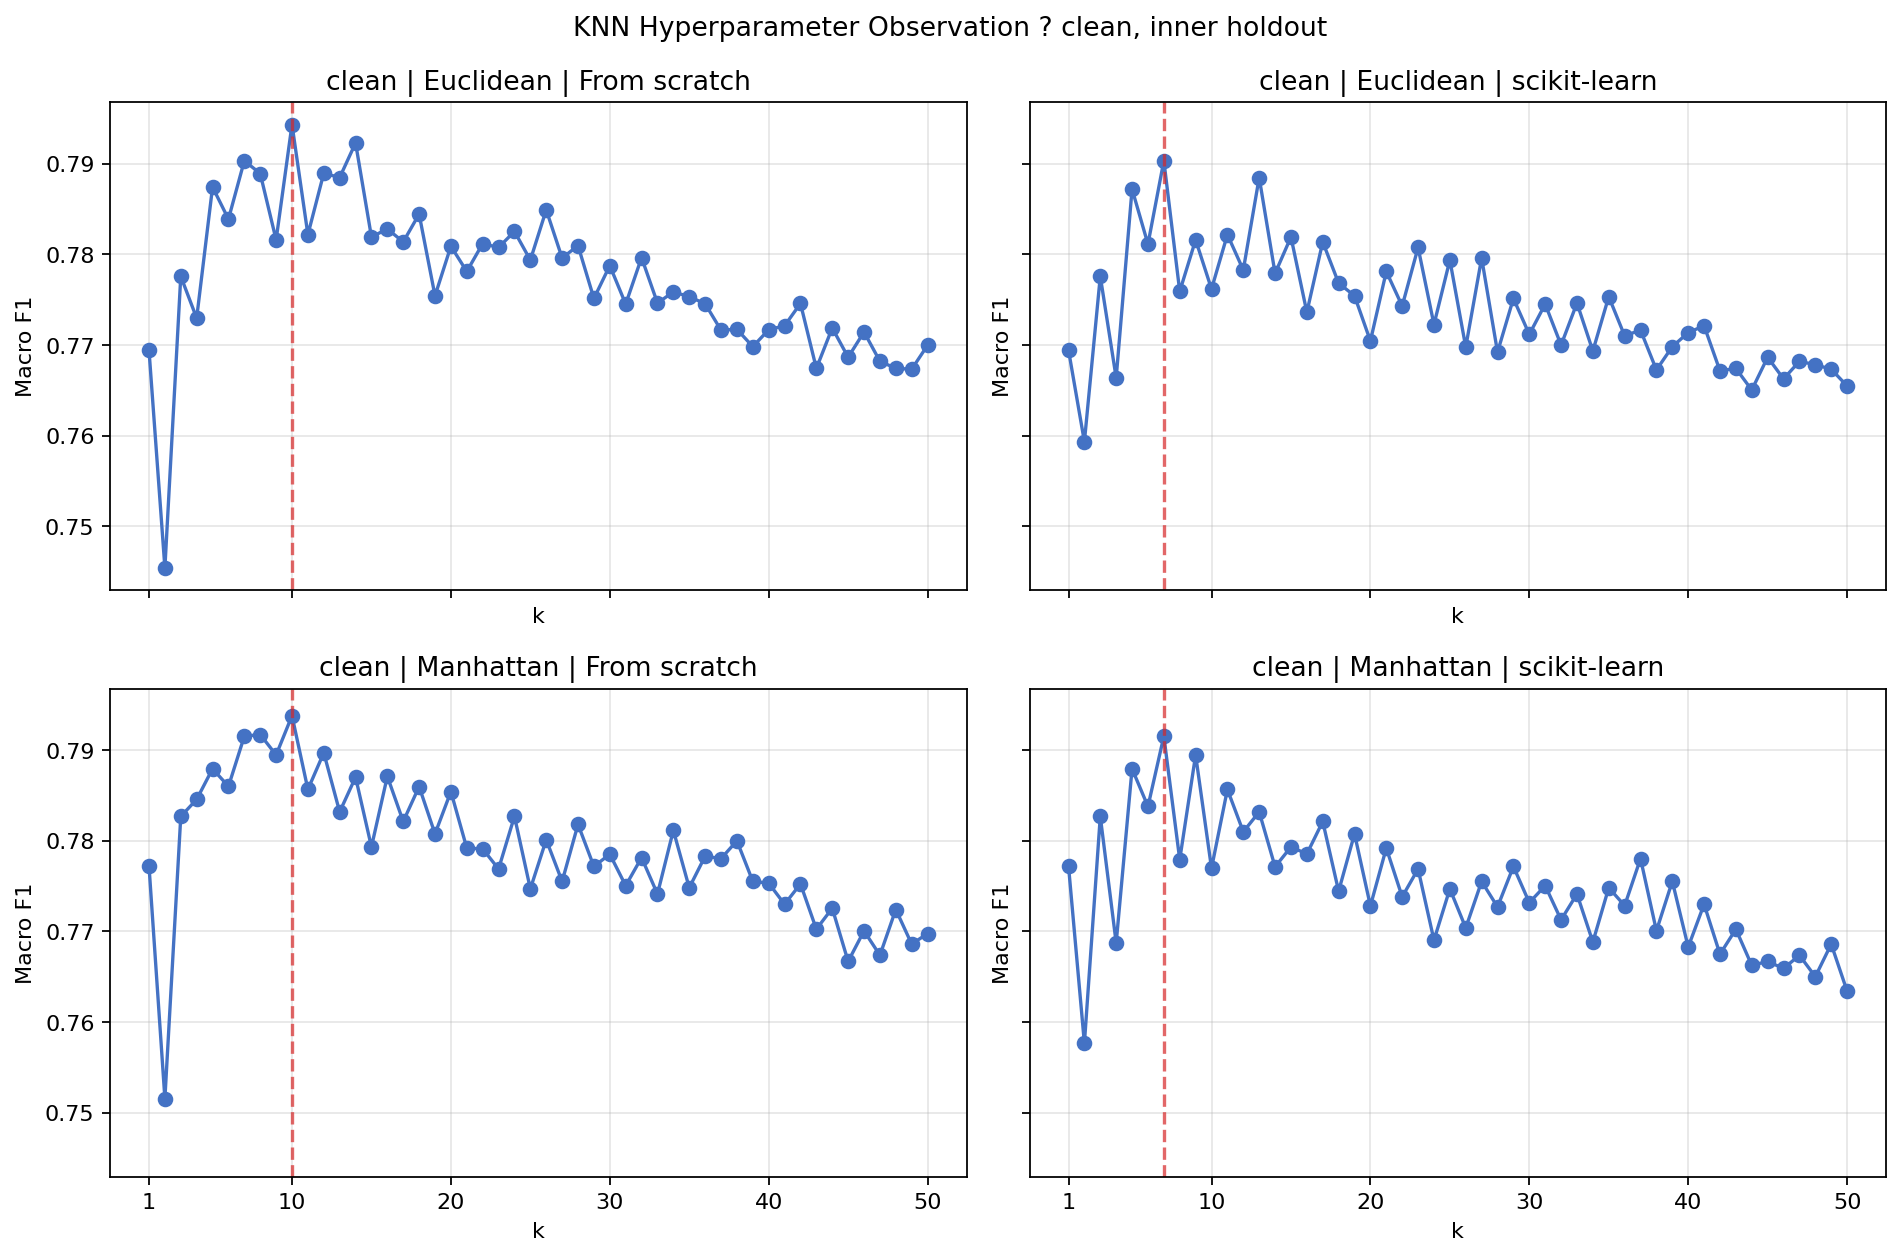

[Tuning Plot Saved] ..\output\plots\knn_k_search.png


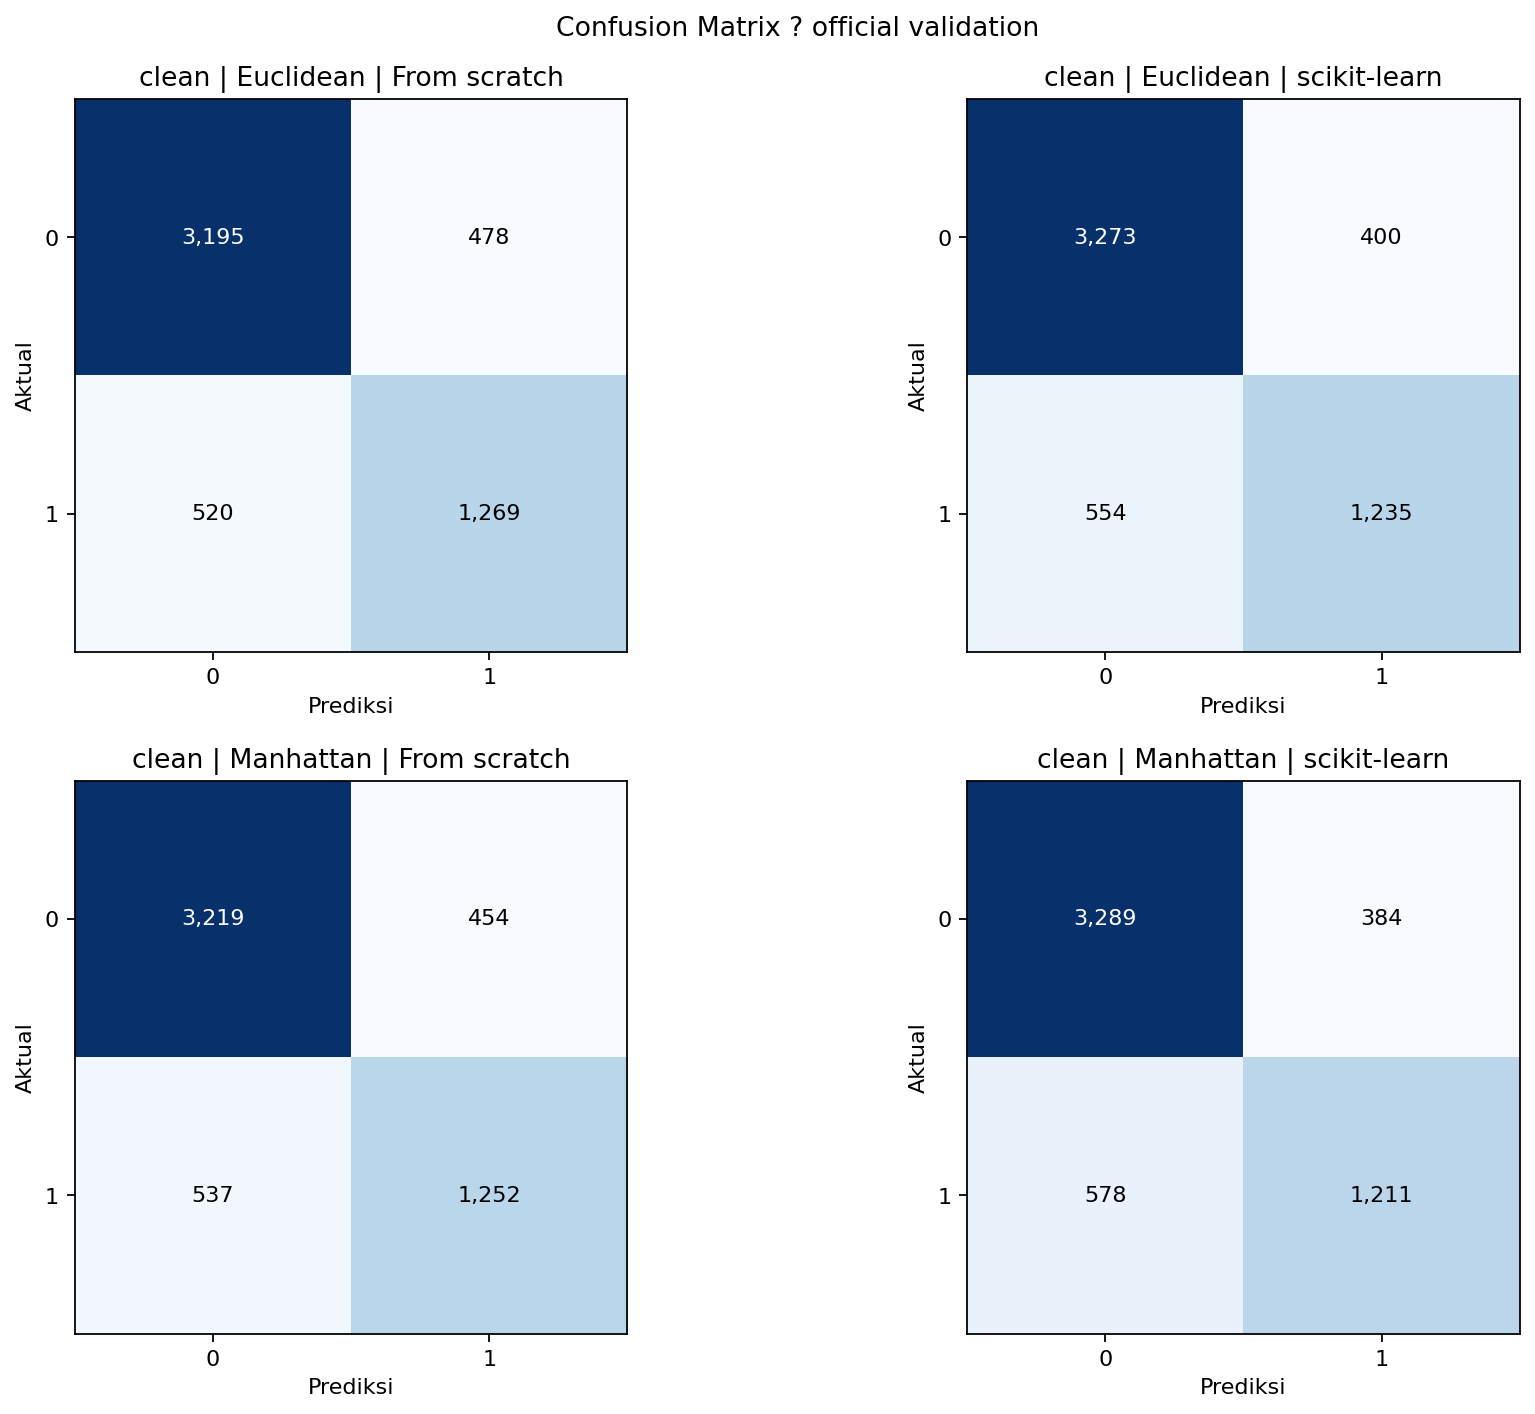

[Confusion Matrices Saved] ..\output\plots\knn_confusion_matrices.png
[Scratch Model Bundle Saved/Load Verified] ..\output\models\knn_model.pkl | clean / euclidean / k=10
[Overall Winner] clean / euclidean / k=10 | ..\output\submissions\submission_knn.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


In [55]:
from pathlib import Path
import pickle
import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from src.preprocessing import DataPipeline
from src.utils import confusion_matrix

root_dir = '..' if os.path.basename(os.getcwd()) == 'notebooks' else '.'
root = Path(root_dir)
processed_dir = root / 'data' / 'processed'
raw_dir = root / 'data' / 'raw'
target_col, id_col = 'is_canceled', 'id'

def macro_f1_score(y_true, y_pred):
    return 0.5 * (f1_score(y_true, y_pred) + f1_score(1 - y_true, 1 - y_pred))


# 1. Muat Dataset Resmi Hasil Pipeline Anggota 1 (train_dtl.csv + val_dtl.csv)
df_tr_cln = pd.read_csv(processed_dir / 'train_clean.csv', dtype={id_col: str})
df_va_cln = pd.read_csv(processed_dir / 'val_clean.csv', dtype={id_col: str})
df_raw_train = pd.read_csv(raw_dir / 'train.csv', dtype={id_col: str})
df_raw_lookup = df_raw_train.set_index(id_col, drop=False)
df_tr_raw = df_raw_lookup.loc[df_tr_cln[id_col]].reset_index(drop=True)
df_va_raw = df_raw_lookup.loc[df_va_cln[id_col]].reset_index(drop=True)
df_test_raw = pd.read_csv(raw_dir / 'test.csv', dtype={id_col: str})
assert df_tr_raw[id_col].equals(df_tr_cln[id_col])
assert df_va_raw[id_col].equals(df_va_cln[id_col])
assert np.array_equal(df_tr_raw[target_col], df_tr_cln[target_col])
assert np.array_equal(df_va_raw[target_col], df_va_cln[target_col])
feature_cols = [c for c in df_tr_cln.columns if c not in (id_col, target_col)]
assert feature_cols == [c for c in df_va_cln.columns if c not in (id_col, target_col)]

X_tr_knn = df_tr_cln[feature_cols].to_numpy(dtype=float)
y_tr_knn = df_tr_cln[target_col].to_numpy(dtype=int)
X_va_knn = df_va_cln[feature_cols].to_numpy(dtype=float)
y_va_knn = df_va_cln[target_col].to_numpy(dtype=int)

distance_metrics = ('euclidean', 'manhattan')
implementations = ('From scratch', 'scikit-learn')

# =============================================================================
# FASE 2 dan 3 menggunakan inner holdout supaya model tidak menjadi sgt optimis ketika evaluasi validation set
# =============================================================================

# 2. HYPERPARAMETER SEARCH 
idx_fit, idx_tune = train_test_split(
    np.arange(len(y_tr_knn)), test_size=0.2, random_state=RANDOM_SEED,
    stratify=y_tr_knn,
)
df_fit_raw = df_tr_raw.iloc[idx_fit].copy()
df_tune_raw = df_tr_raw.iloc[idx_tune].copy()
y_fit_knn, y_tune_knn = y_tr_knn[idx_fit], y_tr_knn[idx_tune]

inner_preprocessor = DataPipeline(use_pca=False, random_state=RANDOM_SEED).fit(df_fit_raw, y_fit_knn)
X_fit_knn = inner_preprocessor.transform(df_fit_raw, use_pca=False).to_numpy(dtype=float)
X_tune_knn = inner_preprocessor.transform(df_tune_raw, use_pca=False).to_numpy(dtype=float)

k_values = list(range(1, min(50, len(y_fit_knn)) + 1))
if not k_values:
    raise ValueError('Data train terlalu sedikit untuk pencarian k.')

# 3. TUNING DISTANCE + k 
def knn_grid_predictions(model, X, labels, candidate_ks, from_scratch, batch_size):
    predictions = {k: [] for k in candidate_ks}
    for start in range(0, len(X), batch_size):
        X_batch = X[start:start + batch_size]
        if from_scratch:
            distances = model._compute_distances(X_batch)
            nearest = np.argsort(distances, axis=1)[:, :max(candidate_ks)]
            neighbor_labels = model.y_train_[nearest]
        else:
            _, nearest = model.kneighbors(X_batch, n_neighbors=max(candidate_ks))
            neighbor_labels = labels[nearest]
        cumulative_positives = np.cumsum(neighbor_labels == 1, axis=1)
        for k in candidate_ks:
            prediction = cumulative_positives[:, k - 1] >= k / 2 if from_scratch else cumulative_positives[:, k - 1] > k / 2
            predictions[k].append(prediction.astype(int))
    return {k: np.concatenate(parts) for k, parts in predictions.items()}


def knn_predict_batched(model, X, batch_size=16):
    return np.concatenate([model.predict(X[i:i + batch_size]) for i in range(0, len(X), batch_size)])

tuning_rows = []
best_knn_by_config = {}
for metric in distance_metrics:
    for implementation in implementations:
        t0 = time.perf_counter()
        if implementation == 'From scratch':
            tuner = KNN(k=max(k_values), metric=metric).fit(X_fit_knn, y_fit_knn)
        else:
            tuner = KNeighborsClassifier(n_neighbors=max(k_values), metric=metric, n_jobs=-1).fit(X_fit_knn, y_fit_knn)
        grid_predictions = knn_grid_predictions(tuner, X_tune_knn, y_fit_knn, k_values,
                                                implementation == 'From scratch',
                                                16 if implementation == 'From scratch' else 256)
        elapsed = time.perf_counter() - t0
        for k in k_values:
            tuning_rows.append({
                'Distance': metric, 'Implementasi': implementation, 'k': k,
                'Tuning Macro F1': macro_f1_score(y_tune_knn, grid_predictions[k]),
                'Tuning time (s)': elapsed,
            })
df_knn_tuning = pd.DataFrame(tuning_rows)
for metric in distance_metrics:
    for implementation in implementations:
        rows = df_knn_tuning[(df_knn_tuning['Distance'] == metric) &
                             (df_knn_tuning['Implementasi'] == implementation)]
        best = rows.loc[rows['Tuning Macro F1'].idxmax()]
        best_knn_by_config[(metric, implementation)] = {
            'k': int(best['k']), 'macro_f1': float(best['Tuning Macro F1']),
        }
print('=== PENCARIAN k DAN DISTANCE ===')
display(df_knn_tuning.pivot_table(index='k', columns=['Distance', 'Implementasi'],
                                  values='Tuning Macro F1').round(4))
for (metric, implementation), best in best_knn_by_config.items():
    print('{} / {}: k={} | Macro F1={:.4f}'.format(metric, implementation, best['k'], best['macro_f1']))

# 4. EVALUASI PADA VALIDATION (train_clean.csv / val_clean.csv)
comparison_rows, val_preds_store, val_models_store = [], {}, {}
knn_validation_probabilities = {}
for metric in distance_metrics:
    for implementation in implementations:
        config = (metric, implementation)
        best = best_knn_by_config[config]
        if implementation == 'From scratch':
            model = KNN(k=best['k'], metric=metric).fit(X_tr_knn, y_tr_knn)
        else:
            model = KNeighborsClassifier(n_neighbors=best['k'], metric=metric, n_jobs=-1).fit(X_tr_knn, y_tr_knn)
        val_models_store[config] = model
        t0 = time.perf_counter()
        if implementation == 'From scratch':
            probabilities = np.concatenate([
                model.predict_proba(X_va_knn[i:i + 16])[:, 1]
                for i in range(0, len(X_va_knn), 16)
            ])
            knn_validation_probabilities[metric] = probabilities
            y_pred_knn = (probabilities >= 0.5).astype(int)
        else:
            y_pred_knn = knn_predict_batched(model, X_va_knn)
        predict_seconds = time.perf_counter() - t0
        val_preds_store[config] = y_pred_knn
        tn, fp, fn, tp = confusion_matrix(y_va_knn, y_pred_knn)
        comparison_rows.append({
            'Distance': metric, 'Implementasi': implementation, 'k terbaik': best['k'],
            'Tuning Macro F1': best['macro_f1'], 'Accuracy': accuracy_score(y_va_knn, y_pred_knn),
            'Precision': precision_score(y_va_knn, y_pred_knn), 'Recall': recall_score(y_va_knn, y_pred_knn),
            'Macro F1': macro_f1_score(y_va_knn, y_pred_knn),
            'Cost (2FP+FN)': calculate_custom_cost(y_va_knn, y_pred_knn),
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp, 'Val predict time (s)': predict_seconds,
        })
df_knn_comparison = pd.DataFrame(comparison_rows)
print('=== VALIDATION METRICS + CONFUSION MATRIX COUNTS ===')
display(df_knn_comparison.round(4))

# 5. PLOT TUNING PER DISTANCE DAN IMPLEMENTASI
plot_configs = [(metric, implementation) for metric in distance_metrics for implementation in implementations]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, config in zip(axes.flat, plot_configs):
    metric, implementation = config
    df_plot = df_knn_tuning[(df_knn_tuning['Distance'] == metric) &
                            (df_knn_tuning['Implementasi'] == implementation)]
    ax.plot(df_plot['k'], df_plot['Tuning Macro F1'], marker='o', color='#4472C4')
    ax.axvline(best_knn_by_config[config]['k'], color='#D62728', linestyle='--', alpha=0.7)
    ax.set(title='clean | {} | {}'.format(metric.title(), implementation), xlabel='k', ylabel='Macro F1')
    ax.set_xticks([1, 10, 20, 30, 40, 50])
    ax.grid(alpha=0.3)
fig.suptitle('KNN Hyperparameter Observation ? clean, inner holdout')
fig.tight_layout()
knn_plot_path = root / 'output' / 'plots' / 'knn_k_search.png'
knn_plot_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(knn_plot_path, dpi=160, bbox_inches='tight')
plt.close(fig)
display(NotebookImage(filename=str(knn_plot_path)))
print('[Tuning Plot Saved] {}'.format(knn_plot_path))

# 6. CONFUSION MATRIX PADA VALIDATION
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, config in zip(axes.flat, plot_configs):
    metric, implementation = config
    tn, fp, fn, tp = confusion_matrix(y_va_knn, val_preds_store[config])
    cm = np.array([[tn, fp], [fn, tp]])
    ax.imshow(cm, cmap='Blues')
    for row in range(2):
        for col in range(2):
            color = 'white' if cm[row, col] > cm.max() / 2 else 'black'
            ax.text(col, row, '{:,}'.format(cm[row, col]), ha='center', va='center', color=color)
    ax.set(title='clean | {} | {}'.format(metric.title(), implementation), xlabel='Prediksi', ylabel='Aktual', xticks=[0, 1], yticks=[0, 1])
fig.suptitle('Confusion Matrix ? official validation')
fig.tight_layout()
knn_confusion_path = root / 'output' / 'plots' / 'knn_confusion_matrices.png'
knn_confusion_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(knn_confusion_path, dpi=160, bbox_inches='tight')
plt.close(fig)
display(NotebookImage(filename=str(knn_confusion_path)))
print('[Confusion Matrices Saved] {}'.format(knn_confusion_path))

# 8. REFIT ON TRAIN + VALIDATION, SAVE MODEL, SUBMISSION
best_scratch_config = max(
    [config for config in best_knn_by_config if config[1] == 'From scratch'],
    key=lambda config: best_knn_by_config[config]['macro_f1'],
)
best_knn_metric, _ = best_scratch_config
best_knn_k = best_knn_by_config[best_scratch_config]['k']
df_all_raw = pd.concat([df_tr_raw, df_va_raw], ignore_index=True)
y_all_knn = df_all_raw[target_col].to_numpy(dtype=int)
final_preprocessor = DataPipeline(use_pca=False, random_state=RANDOM_SEED).fit(df_all_raw, y_all_knn)
X_all_knn = final_preprocessor.transform(df_all_raw, use_pca=False).to_numpy(dtype=float)
X_test_knn = final_preprocessor.transform(df_test_raw, use_pca=False).to_numpy(dtype=float)
best_knn_model = KNN(k=best_knn_k, metric=best_knn_metric).fit(X_all_knn, y_all_knn)
model_bundle = {
    'preprocessor': final_preprocessor, 'model': best_knn_model, 'best_representation': 'clean',
    'best_configuration': {'representation': 'clean', 'distance': best_knn_metric, 'k': best_knn_k},
    'tuning_macro_f1': best_knn_by_config[best_scratch_config]['macro_f1'],
}
model_out_path = root / 'output' / 'models' / 'knn_model.pkl'
model_out_path.parent.mkdir(parents=True, exist_ok=True)
with model_out_path.open('wb') as model_file:
    pickle.dump(model_bundle, model_file)
with model_out_path.open('rb') as model_file:
    loaded_model_bundle = pickle.load(model_file)
X_test_check = loaded_model_bundle['preprocessor'].transform(df_test_raw.iloc[:64], use_pca=False).to_numpy(dtype=float)
assert np.array_equal(knn_predict_batched(best_knn_model, X_test_knn[:64]),
                      knn_predict_batched(loaded_model_bundle['model'], X_test_check)), 'Prediksi berubah setelah save/load.'
print('[Scratch Model Bundle Saved/Load Verified] {} | clean / {} / k={}'.format(model_out_path, best_knn_metric, best_knn_k))

df_sample_sub = pd.read_csv(raw_dir / 'sample_submission.csv', dtype={id_col: str})
y_test_pred_knn = knn_predict_batched(best_knn_model, X_test_knn)
df_submission_knn = pd.DataFrame({id_col: df_test_raw[id_col].astype(str), target_col: y_test_pred_knn.astype(int)})
assert df_submission_knn.shape == df_sample_sub.shape
assert list(df_submission_knn.columns) == list(df_sample_sub.columns)
assert df_submission_knn[id_col].equals(df_sample_sub[id_col])
assert df_submission_knn[target_col].notna().all()
assert set(df_submission_knn[target_col].unique()).issubset({0, 1})
submission_path = root / 'output' / 'submissions' / 'submission_knn.csv'
submission_path.parent.mkdir(parents=True, exist_ok=True)
df_submission_knn.to_csv(submission_path, index=False)
print('[Overall Winner] clean / {} / k={} | {}'.format(best_knn_metric, best_knn_k, submission_path))
display(df_submission_knn.head())


## Decision Tree Learning

**Bagian Anggota 2 (13524053) — C4.5 (*From Scratch*)**

Kelompok memilih algoritma C4.5 sebagai metode Decision Tree Learning, sesuai pilihan algoritma pada spesifikasi Tugas Besar 2. Implementasi dibuat menggunakan NumPy tanpa menggunakan implementasi Decision Tree dari scikit-learn. Model yang dihasilkan berupa satu pohon keputusan, bukan ensemble.

Beberapa hal yang diterapkan dalam implementasi ini adalah:

1. **Pemilihan atribut:** Pemisahan node menggunakan *Gain Ratio*, yaitu perbandingan antara *Information Gain* dan *Split Information*. Sebelum memilih atribut, diterapkan juga kriteria *above-average Information Gain* agar atribut dengan banyak kategori tidak otomatis lebih diutamakan.

2. **Penanganan fitur:** Fitur numerik dipisahkan menggunakan nilai tengah (*midpoint*) dari kandidat batas pemisahan. Untuk fitur kategorikal, pemisahan dilakukan berdasarkan kategori aslinya tanpa melalui *one-hot encoding*. Pada eksperimen awal, pencarian batas numerik menggunakan strategi `exact`.

3. **Penanganan missing values:** Nilai `NaN` dipertahankan dalam dataset khusus DTL (`train_dtl.csv` dan `val_dtl.csv`). Implementasi mengikuti pendekatan C4.5 dengan mendistribusikan bobot sampel yang memiliki nilai hilang ke beberapa cabang berdasarkan proporsi data pada masing-masing cabang. Pendekatan ini digunakan saat pelatihan maupun prediksi.

4. **Pruning:** Sebagai baseline, digunakan *Reduced Error Pruning* (REP). Sebanyak 15% dari data latih disisihkan sebagai data untuk proses pruning. Hasilnya kemudian menjadi pembanding ketika dilakukan eksperimen perbaikan model (*improvements*).

**Referensi**

[1] J. R. Quinlan, "Induction of decision trees," *Machine Learning*, vol. 1, no. 1, pp. 81–106, 1986.

[2] J. R. Quinlan, *C4.5: Programs for Machine Learning*. San Mateo, CA, USA: Morgan Kaufmann, 1993.

[3] T. M. Mitchell, *Machine Learning*. New York, NY, USA: McGraw-Hill, 1997, ch. 3.

In [56]:
# === Bagian Anggota 2 (13524053): Decision Tree Learning (C4.5 From Scratch) ===

def macro_f1_score(y_true, y_pred):
    """Metrik resmi kompetisi Kaggle: rata-rata F1 kelas 0 dan kelas 1."""
    return 0.5 * (f1_score(y_true, y_pred) + f1_score(1 - y_true, 1 - y_pred))


def mcnemar_test(y_true, pred_a, pred_b):
    """Uji signifikansi McNemar (Materi 13) dengan koreksi kontinuitas Edwards (df=1)."""
    correct_a = (pred_a == y_true)
    correct_b = (pred_b == y_true)
    b = int(np.sum(correct_a & ~correct_b))
    c = int(np.sum(~correct_a & correct_b))
    stat = ((abs(b - c) - 1.0) ** 2) / (b + c) if (b + c) > 0 else 0.0
    p_val = float(1.0 - chi2.cdf(stat, df=1)) if (b + c) > 0 else 1.0
    return b, c, stat, p_val


# 1. Muat split resmi hasil pipeline (train_dtl/val_dtl & train_clean/val_clean)
train_dtl_path   = CFG.PROCESSED_DIR / 'train_dtl.csv'
val_dtl_path     = CFG.PROCESSED_DIR / 'val_dtl.csv'
train_clean_path = CFG.PROCESSED_DIR / 'train_clean.csv'
val_clean_path   = CFG.PROCESSED_DIR / 'val_clean.csv'

if all(p.exists() for p in (train_dtl_path, val_dtl_path, train_clean_path, val_clean_path)):
    df_tr_dtl = pd.read_csv(train_dtl_path, dtype={CFG.ID_COLUMN: str})
    df_va_dtl = pd.read_csv(val_dtl_path, dtype={CFG.ID_COLUMN: str})
    df_tr_cln = pd.read_csv(train_clean_path, dtype={CFG.ID_COLUMN: str})
    df_va_cln = pd.read_csv(val_clean_path, dtype={CFG.ID_COLUMN: str})
    assert (df_tr_dtl[CFG.ID_COLUMN] == df_tr_cln[CFG.ID_COLUMN]).all(), 'ID train_dtl != train_clean!'
    assert (df_va_dtl[CFG.ID_COLUMN] == df_va_cln[CFG.ID_COLUMN]).all(), 'ID val_dtl != val_clean!'
    dtl_data_src = 'data/processed/{train,val}_dtl.csv (Pipeline Resmi Anggota 1)'
elif all(k in globals() for k in ('prep_pipeline', 'train_set', 'val_set')):
    df_tr_dtl = prep_pipeline._attach_meta(prep_pipeline.transform(train_set, for_dtl=True), train_set)
    df_va_dtl = prep_pipeline._attach_meta(prep_pipeline.transform(val_set, for_dtl=True), val_set)
    df_tr_cln = prep_pipeline._attach_meta(prep_pipeline.transform(train_set, use_pca=False), train_set)
    df_va_cln = prep_pipeline._attach_meta(prep_pipeline.transform(val_set, use_pca=False), val_set)
    dtl_data_src = 'In-memory prep_pipeline (Bagian 4-6 Anggota 1)'
else:
    raise FileNotFoundError(
        f'Dataset processed tidak ditemukan di {CFG.PROCESSED_DIR}. '
        'Jalankan Bagian 4-6 (Anggota 1) atau pastikan data/processed/*_dtl.csv tersedia.'
    )

dtl_feat_names = [c for c in df_tr_dtl.columns if c not in (CFG.ID_COLUMN, CFG.TARGET)]
dtl_cat_names  = {'meal_package', 'room_category', 'booking_channel'}
dtl_cat_indices = [
    i for i, c in enumerate(dtl_feat_names)
    if c in dtl_cat_names or df_tr_dtl[c].dtype == object or str(df_tr_dtl[c].dtype) in ('str', 'string', 'category')
]

X_tr_dtl = df_tr_dtl[dtl_feat_names].to_numpy(dtype=object)
y_tr_dtl = df_tr_dtl[CFG.TARGET].to_numpy(dtype=int)
X_va_dtl = df_va_dtl[dtl_feat_names].to_numpy(dtype=object)
y_va_dtl = df_va_dtl[CFG.TARGET].to_numpy(dtype=int)

# Mask baris yang memiliki NaN pada 17 atribut asli (untuk analisis missing values)
base_cols_dtl = dtl_feat_names[:17]
has_nan_base  = df_va_dtl[base_cols_dtl].isna().any(axis=1).to_numpy()

print(f'[DTL-C4.5] Sumber data : {dtl_data_src}')
print(f'[DTL-C4.5] Train shape : {X_tr_dtl.shape} | Val shape: {X_va_dtl.shape}')
print(f'[DTL-C4.5] Fitur kat.  : {[dtl_feat_names[i] for i in dtl_cat_indices]}')
print(f'[DTL-C4.5] Val NaN rows: {has_nan_base.sum():,} / {len(has_nan_base):,} ({has_nan_base.mean()*100:.1f}%)')

# 2. Pelatihan & Validasi Baseline Kuliah C4.5 (Exact Unpruned & Exact + REP)
dtl_baseline_configs = [
    (
        'Baseline Kuliah: C4.5 Exact (Unpruned)',
        lambda: DecisionTree(
            criterion='c45', split_strategy='exact', missing_strategy='fractional',
            max_depth=18, min_samples_leaf=5, use_pruning=False,
            categorical_features=dtl_cat_indices, random_state=CFG.SEED,
        ),
    ),
    (
        'Baseline Kuliah: C4.5 Exact + REP (Materi 10c)',
        lambda: DecisionTree(
            criterion='c45', split_strategy='exact', missing_strategy='fractional',
            max_depth=18, min_samples_leaf=5, use_pruning=True, pruning_method='rep',
            val_split_ratio=0.15, categorical_features=dtl_cat_indices, random_state=CFG.SEED,
        ),
    ),
]

dtl_ablation_rows = []
dtl_val_preds = {}
dtl_models = {}

for label, builder in dtl_baseline_configs:
    t0 = time.perf_counter()
    clf = builder()
    clf.fit(X_tr_dtl, y_tr_dtl)
    elapsed = time.perf_counter() - t0
    preds = clf.predict(X_va_dtl)
    dtl_val_preds[label] = preds
    dtl_models[label] = clf
    dtl_ablation_rows.append({
        'Konfigurasi C4.5 (Holdout val_dtl)': label,
        'Val Macro F1': macro_f1_score(y_va_dtl, preds),
        'Macro F1 (NaN)': macro_f1_score(y_va_dtl[has_nan_base], preds[has_nan_base]),
        'Macro F1 (Full)': macro_f1_score(y_va_dtl[~has_nan_base], preds[~has_nan_base]),
        'Accuracy': accuracy_score(y_va_dtl, preds),
        'Precision': precision_score(y_va_dtl, preds),
        'Recall': recall_score(y_va_dtl, preds),
        'Cost (2FP+FN)': calculate_custom_cost(y_va_dtl, preds),
        'Nodes': clf.get_n_nodes(),
        'Depth': clf.get_depth(),
        'Time (s)': elapsed,
    })

df_dtl_baseline = pd.DataFrame(dtl_ablation_rows)
print('\n=== HASIL VALIDASI BASELINE KULIAH C4.5 (val_dtl: 5,462 BARIS) ===')
display(df_dtl_baseline.round(4))

# Registrasi ke tabel agregasi Model Evaluation
model_eval_results = globals().get('model_eval_results', {})
rep_label = 'Baseline Kuliah: C4.5 Exact + REP (Materi 10c)'
model_eval_results['DTL C4.5 (Baseline REP)'] = {
    'Val Macro F1': macro_f1_score(y_va_dtl, dtl_val_preds[rep_label]),
    'Accuracy': accuracy_score(y_va_dtl, dtl_val_preds[rep_label]),
    'Precision': precision_score(y_va_dtl, dtl_val_preds[rep_label]),
    'Recall': recall_score(y_va_dtl, dtl_val_preds[rep_label]),
    'Cost (2FP+FN)': calculate_custom_cost(y_va_dtl, dtl_val_preds[rep_label]),
}

[DTL-C4.5] Sumber data : data/processed/{train,val}_dtl.csv (Pipeline Resmi Anggota 1)
[DTL-C4.5] Train shape : (21847, 25) | Val shape: (5462, 25)
[DTL-C4.5] Fitur kat.  : ['meal_package', 'room_category', 'booking_channel']
[DTL-C4.5] Val NaN rows: 2,086 / 5,462 (38.2%)

=== HASIL VALIDASI BASELINE KULIAH C4.5 (val_dtl: 5,462 BARIS) ===


,Konfigurasi C4.5 (Holdout val_dtl),Val Macro F1,Macro F1 (NaN),Macro F1 (Full),Accuracy,Precision,Recall,Cost (2FP+FN),Nodes,Depth,Time (s)
0,Baseline Kuliah: C4.5 Exact (Unpruned),0.8250,0.8118,0.8327,0.8512,0.8128,0.7088,1105.0,2482,18,2.7613
1,Baseline Kuliah: C4.5 Exact + REP (Materi 10c),0.8186,0.7945,0.8331,0.8462,0.8079,0.6959,1136.0,364,18,2.4819


## Logistic Regression

Regresi logistik memodelkan log-odds pembatalan sebagai $w^\top x+b$. Hubungan antara jumlah permintaan khusus dan pembatalan dapat bergantung pada kanal atau jarak waktu ke kedatangan. Hubungan fitur numerik seperti jarak waktu itu juga dapat berubah pada rentang yang berbeda. Indikator tunggal dan pasangan memberi model cara untuk merepresentasikan kemungkinan tersebut secara sistematis.

### Konstruksi fitur

`BookingFeatureTransformer` memakai 52 fitur dari pipeline tim tanpa PCA. Untuk membuat indikator, lead time dan harga per malam dibagi menjadi hingga lima bin dengan kuantil data latih. Dari 17 atribut dibentuk indikator untuk setiap level tunggal dan kombinasi level pada 136 pasangan atribut. Sebagai contoh, satu kolom bernilai 1 jika sebuah booking datang dari Online Travel Agent dan memiliki tepat satu permintaan khusus. Kombinasi perlu muncul minimal 20 kali pada data latih agar memiliki kolom. Indikator digabungkan dengan fitur pipeline dalam matriks sparse CSR karena kebanyakan kolom indikator bernilai nol pada setiap booking. Data validasi dan test memakai batas bin dan urutan kolom yang dipelajari saat fit.

### Objektif dan optimasi

Model *from scratch* meminimalkan rata-rata log-loss biner ditambah $\lambda_1\lVert w\rVert_1+\tfrac12\lambda_2\lVert w\rVert_2^2$. Intersep bebas dari penalti. Kekuatan penalti total adalah $1/(n_{\mathrm{latih}}C)$, dialokasikan ke L1, L2, atau dibagi rata untuk Elastic Net. FISTA melakukan langkah proksimal dengan *soft-thresholding* untuk L1. *Backtracking* mengecilkan langkah sampai bagian mulus memenuhi batas kuadratik, dan momentum mengekstrapolasi dari dua pembaruan terakhir. Fit berhenti jika residu KKT maksimum mencapai toleransi $10^{-5}$ atau anggaran 3.500 pembaruan habis. [Beck dan Teboulle (2009), §4](https://doi.org/10.1137/080716542)

### Pemilihan regularisasi dan ambang

Dari partisi latih, sisihkan 20% secara stratified dengan seed 42 sebagai validasi dalam. Fit transformer hanya pada bagian latih dalam. Untuk setiap kombinasi regularisasi dan C, latih satu model dan gunakan kembali probabilitasnya untuk menguji 17 ambang dari 0,30 hingga 0,70. Pilih ambang dengan macro F1 tertinggi. Jika seri, pilih yang terdekat ke 0,50, lalu ambang yang lebih kecil. Waktu pada tabel mengukur tahap pelatihan estimator.

In [9]:
logreg_inner_train, logreg_inner_val = train_test_split(
    train_set, test_size=CFG.TEST_SIZE, random_state=CFG.SEED, stratify=train_set[CFG.TARGET],
)
logreg_inner_transformer = BookingFeatureTransformer().fit(logreg_inner_train)
logreg_inner_X_train = logreg_inner_transformer.transform(logreg_inner_train)
logreg_inner_X_val = logreg_inner_transformer.transform(logreg_inner_val)
logreg_inner_y_train = logreg_inner_train[CFG.TARGET].to_numpy(dtype=int)
logreg_inner_y_val = logreg_inner_val[CFG.TARGET].to_numpy(dtype=int)

logreg_thresholds = np.arange(300, 701, 25) / 1000
logreg_tuning_rows = []
for penalty, label in (("l1", "L1"), ("l2", "L2"), ("elasticnet", "Elastic Net")):
    for C in (0.05, 0.10):
        estimator = LogisticRegression(
            penalty=penalty, reg_lambda=1 / (len(logreg_inner_y_train) * C),
            l1_ratio=0.5, n_iters=3500, tol=1e-5,
        )
        start = time.perf_counter()
        estimator.fit(logreg_inner_X_train, logreg_inner_y_train)
        seconds = time.perf_counter() - start
        probabilities = estimator.predict_proba(logreg_inner_X_val)[:, 1]
        for threshold in logreg_thresholds:
            logreg_tuning_rows.append({
                "Regularisasi": label, "C": C, "Ambang": threshold,
                "Macro F1": sklearn_f1_score(logreg_inner_y_val, probabilities >= threshold, average="macro"),
                "Latih (s)": seconds, "Pembaruan": estimator.n_iter_, "Residu KKT": estimator.optimality_,
                "Status henti": "Toleransi KKT" if estimator.converged_ else "Batas iterasi",
            })

logreg_tuning = pd.DataFrame(logreg_tuning_rows)
logreg_best_thresholds = (
    logreg_tuning.assign(jarak=(logreg_tuning["Ambang"] - 0.5).abs().round(3))
    .sort_values(["Macro F1", "jarak", "Ambang"], ascending=[False, True, True])
    .drop_duplicates(["Regularisasi", "C"])
    .drop(columns="jarak")
)
logreg_tuning_table = logreg_best_thresholds.round({"Macro F1": 5, "Latih (s)": 2})
logreg_tuning_table["Residu KKT"] = logreg_tuning_table["Residu KKT"].map("{:.2e}".format)
display(logreg_tuning_table.reset_index(drop=True))

,Regularisasi,C,Ambang,Macro F1,Latih (s),Pembaruan,Residu KKT,Status henti
0,L2,0.05,0.475,0.82629,23.16,2277,1.00e-05,Toleransi KKT
1,L2,0.10,0.475,0.82346,30.45,3046,9.98e-06,Toleransi KKT
2,Elastic Net,0.10,0.450,0.82259,28.27,2840,9.15e-06,Toleransi KKT
3,L1,0.10,0.450,0.81731,32.14,3170,9.99e-06,Toleransi KKT
4,Elastic Net,0.05,0.375,0.81564,24.61,2488,9.96e-06,Toleransi KKT
5,L1,0.05,0.475,0.80236,27.10,2725,9.99e-06,Toleransi KKT


In [10]:
from io import BytesIO


def display_logreg_figure(fig):
    with BytesIO() as buffer:
        fig.savefig(buffer, format="png", dpi=130)
        display(Image(data=buffer.getvalue()))
    plt.close(fig)


logreg_heatmap = logreg_best_thresholds.pivot(index="Regularisasi", columns="C", values="Macro F1")
logreg_heatmap = logreg_heatmap.reindex(["L1", "L2", "Elastic Net"])
fig, (heatmap, curve) = plt.subplots(
    1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.65]}, layout="constrained",
)
sns.heatmap(logreg_heatmap, annot=True, fmt=".5f", cmap="Blues", ax=heatmap,
            cbar_kws={"label": "Macro F1"})
heatmap.set(title="Skor terbaik per konfigurasi", ylabel=None)
heatmap.tick_params(axis="y", labelrotation=0)
sns.lineplot(data=logreg_tuning, x="Ambang", y="Macro F1", hue="Regularisasi", style="C", ax=curve)
curve.axvline(0.475, color="0.45", linewidth=1, linestyle=":")
curve.set(title="Macro F1 menurut ambang", xlabel="Ambang probabilitas pembatalan")
display_logreg_figure(fig)

Pada grid ini, L2 dengan $C=0{,}05$ dan ambang 0,475 mencapai macro F1 validasi dalam tertinggi, yaitu 0,82629. L2 dengan $C=0{,}10$ mencapai 0,82346 pada ambang yang sama. Keenam fit memenuhi toleransi KKT. Garis titik pada kurva menandai ambang terpilih.

### Evaluasi pada validasi outer

Latih ulang transformer dan model L2 ($C=0{,}05$) pada seluruh partisi latih. Terapkan ambang 0,475 pada validasi luar seed 42. Custom Cost ($2\,\mathrm{FP}+\mathrm{FN}$) dipakai untuk membaca dampak kesalahan, sedangkan pemilihan ambang memakai macro F1.

In [11]:
def logreg_scores(y, labels):
    tn, fp, fn, tp = confusion_matrix(y, labels)
    return {
        "Macro F1": sklearn_f1_score(y, labels, average="macro"),
        "F1 positif": f1_score(y, labels), "Akurasi": accuracy_score(y, labels),
        "Presisi": precision_score(y, labels), "Recall": recall_score(y, labels),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp, "Custom Cost": 2 * fp + fn,
    }


logreg_c, logreg_threshold = 0.05, 0.475
logreg_transformer = BookingFeatureTransformer().fit(train_set)
logreg_X_train = logreg_transformer.transform(train_set)
logreg_X_validation = logreg_transformer.transform(val_set)
logreg_model = LogisticRegression(
    penalty="l2", reg_lambda=1 / (len(y_train) * logreg_c), n_iters=3500, tol=1e-5,
)
logreg_start = time.perf_counter()
logreg_model.fit(logreg_X_train, y_train)
logreg_fit_seconds = time.perf_counter() - logreg_start
logreg_val_proba = logreg_model.predict_proba(logreg_X_validation)[:, 1]
logreg_val_pred = (logreg_val_proba >= logreg_threshold).astype(int)
logreg_metrics = {
    "Penalti": "l2", "C": logreg_c,
    "Batas": logreg_model.n_iters, "Ambang": logreg_threshold,
    **logreg_scores(y_validation, logreg_val_pred),
    "Kolom": logreg_X_train.shape[1], "Koefisien nonnol": np.count_nonzero(logreg_model.coef_),
    "Latih (s)": logreg_fit_seconds, "Iterasi": logreg_model.n_iter_,
    "Residu KKT": logreg_model.optimality_,
    "Status henti": "Toleransi KKT" if logreg_model.converged_ else "Batas iterasi",
}
display(pd.DataFrame([logreg_metrics]).round(6))

logreg_confusion = [[logreg_metrics["TN"], logreg_metrics["FP"]],
                    [logreg_metrics["FN"], logreg_metrics["TP"]]]
fig, ax = plt.subplots(figsize=(5, 3.6), layout="constrained")
sns.heatmap(logreg_confusion, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Tidak batal", "Batal"], yticklabels=["Tidak batal", "Batal"])
ax.set(title="Matriks kebingungan pada validasi luar", xlabel="Prediksi", ylabel="Aktual")
ax.tick_params(axis="y", labelrotation=0)
display_logreg_figure(fig)

model_eval_results = globals().get("model_eval_results", {})
model_eval_results["Logistic Regression (FISTA)"] = {
    "Val Macro F1": logreg_metrics["Macro F1"], "Accuracy": logreg_metrics["Akurasi"],
    "Precision": logreg_metrics["Presisi"], "Recall": logreg_metrics["Recall"],
    "Cost (2FP+FN)": logreg_metrics["Custom Cost"],
}

,Penalti,C,Batas,Ambang,Macro F1,F1 positif,Akurasi,Presisi,Recall,TN,FP,FN,TP,Custom Cost,Kolom,Koefisien nonnol,Latih (s),Iterasi,Residu KKT,Status henti
0,l2,0.05,3500,0.475,0.829717,0.76777,0.852252,0.791222,0.745668,3321,352,455,1334,1159,3688,3688,33.388889,2496,0.00001,Toleransi KKT


## Support Vector Machine

Implementasi dibuat menggunakan NumPy tanpa menggunakan implementasi SVM dari scikit-learn (`src/svm.py`). SVM mencari hyperplane pemisah dengan margin terbesar. Masalah *soft-margin* diselesaikan pada bentuk dual dengan pengali Lagrange $\alpha_i \in [0, C]$, sehingga batas keputusan hanya bergantung pada *support vector* (data dengan $\alpha_i > 0$).

Beberapa hal yang diterapkan dalam implementasi ini adalah:

1. **Solver:** Masalah dual diselesaikan dengan *Sequential Minimal Optimization* (SMO), yaitu memperbarui dua pengali Lagrange sekaligus pada setiap iterasi. Pasangan variabel dipilih dengan *maximal violating pair* orde-dua (working set selection milik libsvm), dan iterasi berhenti ketika celah kondisi KKT lebih kecil dari toleransi `tol`. Solver ini tidak membutuhkan pemecah QP umum sehingga hanya memerlukan satu matriks Gram.

2. **Kernel:** Tiga kernel yang diminta pada spesifikasi diimplementasikan, yaitu *Linear* ($x^\top x'$), *Polynomial* ($(\gamma\, x^\top x' + r)^d$), dan *Gaussian/RBF* ($\exp(-\gamma \lVert x - x' \rVert^2)$). Seluruh kernel dihitung sebagai matriks Gram penuh sehingga solver SMO dapat membaca baris kernel secara langsung.

3. **Penanganan fitur:** Model memakai data hasil `DataPipeline` (`train_clean.csv` dan `val_clean.csv`), yaitu fitur numerik terstandardisasi dan kategorikal ter-*one-hot*. Standardisasi penting karena kernel berbasis jarak sangat sensitif terhadap skala antarfitur. Parameter preprocessing hanya dipelajari dari data latih.

4. **Efisiensi memori:** Matriks Gram dihitung di dalam satu buffer `float32` (operasi *in-place*), sehingga puncak memori sekitar $n^2 \times 4$ byte (sekitar 1,9 GB untuk 21,8 ribu data latih). Variabel dual, bias, dan `decision_function` tetap dihitung dalam `float64`. Prediksi dilakukan per batch agar matriks kernel tidak membengkak.

5. **Hyperparameter tuning:** Mengikuti pola KNN, tuning memakai *inner holdout*: data latih dibagi 80:20 (stratified), pipeline preprocessing di-*fit* ulang hanya pada 80% bagian *fit*, dan konfigurasi dinilai dengan Macro F1 pada 20% bagian *tune*. Agar waktu tuning terjaga, model pada tahap pencarian dilatih pada subsampel berstrata dari bagian *fit*, dengan batas `max_iter` yang lebih kecil. Parameter yang dicari adalah $C$ untuk semua kernel, $\gamma$ untuk kernel *Polynomial* dan *RBF*, serta derajat polinomial. Nilai $\gamma$ dinyatakan sebagai kelipatan $1/n_{fitur}$. Waktu seluruh pencarian dicatat sebagai *tuning time*, sedangkan waktu pelatihan dan waktu prediksi konfigurasi terbaik pada validation set diukur secara terpisah.

6. **Prediksi kelas:** Kelas ditentukan dari tanda $f(x)$ (kelas 1 bila $f(x) \geq 0$). Probabilitas diperoleh dengan *Platt Scaling* yang dilatih pada skor keputusan data latih.

Referensi:
- `[1]` C. Cortes dan V. Vapnik, "Support-vector networks," *Machine Learning*, vol. 20, no. 3, pp. 273-297, 1995.
- `[2]` J. C. Platt, "Sequential Minimal Optimization: A Fast Algorithm for Training Support Vector Machines," Microsoft Research, Tech. Rep. MSR-TR-98-14, 1998.
- `[3]` R.-E. Fan, P.-H. Chen, dan C.-J. Lin, "Working Set Selection Using Second Order Information for Training Support Vector Machines," *Journal of Machine Learning Research*, vol. 6, pp. 1889-1918, 2005.
- `[4]` J. C. Platt, "Probabilistic Outputs for Support Vector Machines and Comparisons to Regularized Likelihood Methods," dalam *Advances in Large Margin Classifiers*, MIT Press, 1999.

c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\src\svm.py:345: RuntimeWarning: Jumlah sampel pelatihan (6000) melebihi 3000; matriks kernel penuh ~0.13 GB (float32). Pertimbangkan max_samples untuk subsampling berstrata.
  warnings.warn(


=== PENCARIAN HYPERPARAMETER SVM (5 konfigurasi terbaik per kernel) ===

Linear | 3 konfigurasi | tuning time 93.4s


,C,Tuning Macro F1,Fit time (s)
1,1.0,0.7571,6.5276
0,0.1,0.7559,1.3081
2,10.0,0.7487,85.5688



Polynomial | 12 konfigurasi | tuning time 49.6s


,C,gamma,degree,Tuning Macro F1,Fit time (s)
13,10.0,0.0192,3.0,0.7869,5.5993
14,10.0,0.0385,3.0,0.7833,9.5748
11,1.0,0.0385,3.0,0.7828,2.0348
8,10.0,0.0385,2.0,0.7787,18.8554
12,10.0,0.0096,3.0,0.7780,3.1150



Gaussian (RBF) | 20 konfigurasi | tuning time 41.6s


,C,gamma,Tuning Macro F1,Fit time (s)
31,30.0,0.0192,0.7926,4.8380
23,3.0,0.0769,0.7924,1.2078
27,10.0,0.0385,0.7912,2.1700
32,30.0,0.0385,0.7882,4.9644
19,1.0,0.1538,0.7873,0.7920


Linear: {'C': 1.0} | Tuning Macro F1=0.7571
Polynomial: {'C': 10.0, 'degree': 3, 'gamma': 0.019230769230769232, 'coef0': 1.0} | Tuning Macro F1=0.7869
Gaussian (RBF): {'C': 30.0, 'gamma': 0.019230769230769232} | Tuning Macro F1=0.7926


c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\src\svm.py:345: RuntimeWarning: Jumlah sampel pelatihan (21847) melebihi 3000; matriks kernel penuh ~1.78 GB (float32). Pertimbangkan max_samples untuk subsampling berstrata.
  warnings.warn(



=== VALIDATION METRICS + CONFUSION MATRIX COUNTS ===


,Kernel,Parameter terbaik,Tuning Macro F1,Accuracy,Precision,Recall,Macro F1,Cost (2FP+FN),TN,FP,FN,TP,Jumlah SV,Fit time (s),Val predict time (s)
0,Linear,{'C': 1.0},0.7571,0.7862,0.7226,0.5634,0.7411,1555.0,3286,387,781,1008,10348,224.1336,0.1845
1,Polynomial,"{'C': 10.0, 'degree': 3, 'gamma': 0.0192, 'coe...",0.7869,0.8303,0.7968,0.6467,0.7967,1222.0,3378,295,632,1157,8964,212.7480,0.7381
2,Gaussian (RBF),"{'C': 30.0, 'gamma': 0.0192}",0.7926,0.8361,0.7996,0.6669,0.8051,1194.0,3374,299,596,1193,8804,51.5838,0.5401


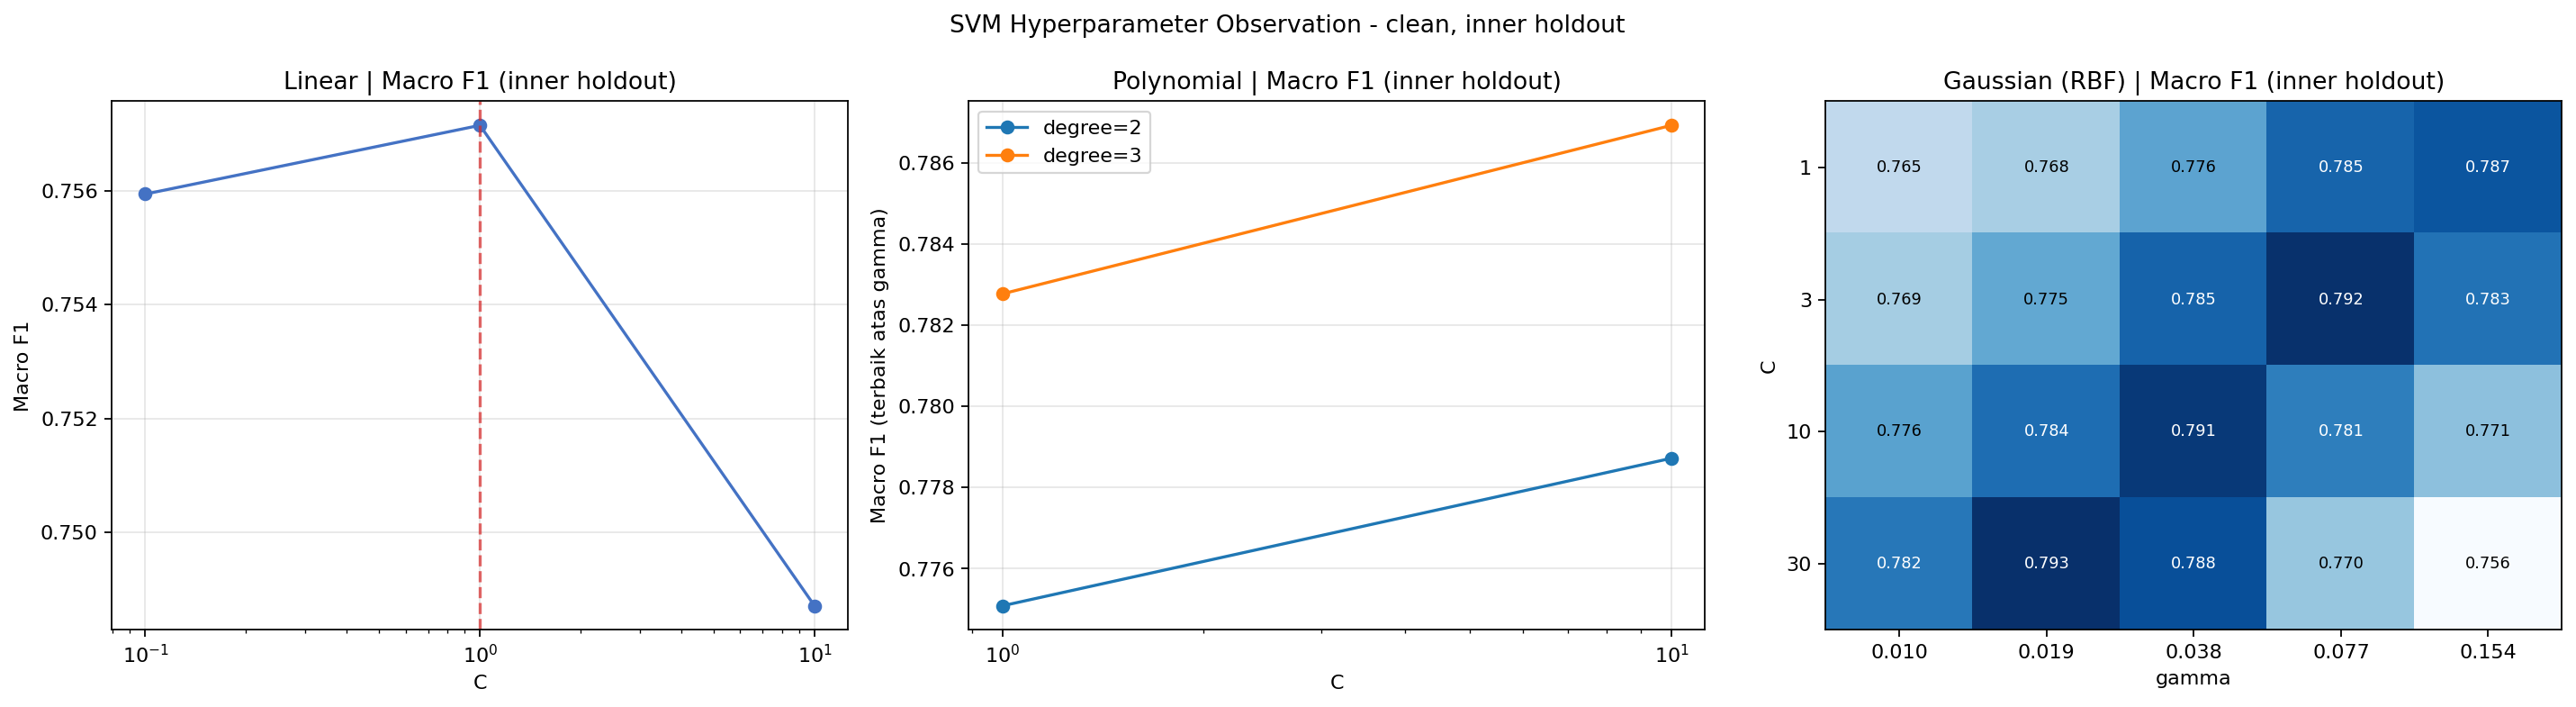

[Tuning Plot Saved] c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\plots\svm_tuning.png


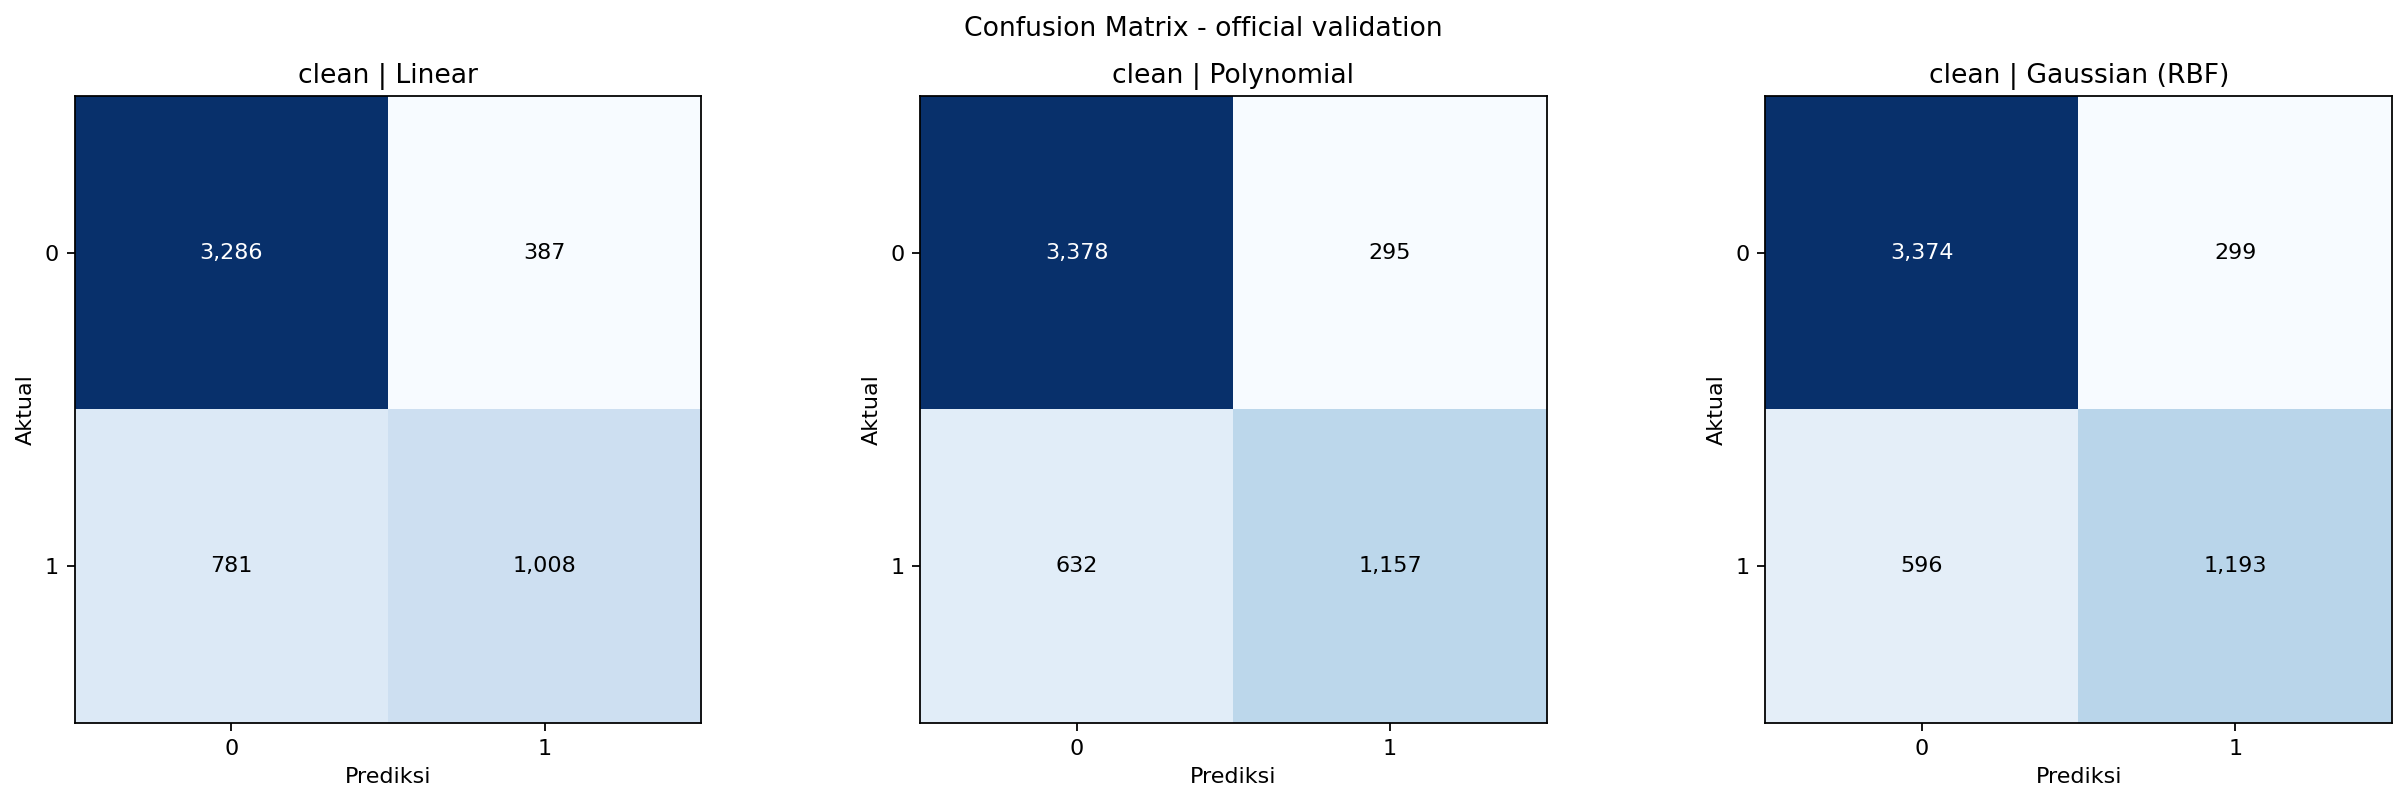

[Confusion Matrices Saved] c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\plots\svm_confusion_matrices.png


c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\src\svm.py:345: RuntimeWarning: Jumlah sampel pelatihan (22000) melebihi 3000; matriks kernel penuh ~1.80 GB (float32). Pertimbangkan max_samples untuk subsampling berstrata.
  warnings.warn(


[SVM Model Bundle Saved/Load Verified] c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\models\svm_model.pkl | clean / rbf / {'C': 30.0, 'gamma': 0.019230769230769232}
[Overall Winner] clean / rbf / {'C': 30.0, 'gamma': 0.019230769230769232} | c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\submissions\submission_svm.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


In [60]:
# === Support Vector Machine (From Scratch): Modeling & Validation ===
import pickle
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage
from sklearn.model_selection import train_test_split
from src.preprocessing import DataPipeline
from src.svm import SVM
from src.utils import (
    accuracy_score, confusion_matrix, precision_score, recall_score,
    f1_score, calculate_custom_cost,
)

root = CFG.OUTPUT_DIR.parent
processed_dir, raw_dir = CFG.PROCESSED_DIR, CFG.DATA_DIR
target_col, id_col = CFG.TARGET, CFG.ID_COLUMN

# Pengaturan komputasi SVM (matriks Gram n x n: 21,8 ribu data float32 ~ 1,9 GB RAM)
SVM_TUNE_SAMPLES      = 6000    # ukuran subsampel berstrata (bagian fit) untuk pencarian hyperparameter
SVM_TUNE_MAX_ITER     = 30      # batas putaran SMO saat tuning (maks. max_iter * n pembaruan)
SVM_FIT_MAX_ITER      = 50      # batas putaran SMO untuk model validasi dan model akhir
SVM_FINAL_MAX_SAMPLES = 22000   # batas sampel model akhir (train+val = 27,3 ribu ~ 3 GB); None = seluruhnya


def macro_f1_score(y_true, y_pred):
    """Metrik resmi kompetisi Kaggle: rata-rata F1 kelas 0 dan kelas 1."""
    return 0.5 * (f1_score(y_true, y_pred) + f1_score(1 - y_true, 1 - y_pred))


# 1. Muat dataset resmi hasil pipeline (train_clean.csv + val_clean.csv) dan data mentah padanannya
df_tr_cln = pd.read_csv(processed_dir / 'train_clean.csv', dtype={id_col: str})
df_va_cln = pd.read_csv(processed_dir / 'val_clean.csv', dtype={id_col: str})
df_raw_train = pd.read_csv(raw_dir / 'train.csv', dtype={id_col: str})
df_raw_lookup = df_raw_train.set_index(id_col, drop=False)
df_tr_raw = df_raw_lookup.loc[df_tr_cln[id_col]].reset_index(drop=True)
df_va_raw = df_raw_lookup.loc[df_va_cln[id_col]].reset_index(drop=True)
df_test_raw = pd.read_csv(raw_dir / 'test.csv', dtype={id_col: str})
assert df_tr_raw[id_col].equals(df_tr_cln[id_col])
assert df_va_raw[id_col].equals(df_va_cln[id_col])
assert np.array_equal(df_tr_raw[target_col], df_tr_cln[target_col])
assert np.array_equal(df_va_raw[target_col], df_va_cln[target_col])
feature_cols = [c for c in df_tr_cln.columns if c not in (id_col, target_col)]
assert feature_cols == [c for c in df_va_cln.columns if c not in (id_col, target_col)]

X_tr_svm = df_tr_cln[feature_cols].to_numpy(dtype=float)
y_tr_svm = df_tr_cln[target_col].to_numpy(dtype=int)
X_va_svm = df_va_cln[feature_cols].to_numpy(dtype=float)
y_va_svm = df_va_cln[target_col].to_numpy(dtype=int)

svm_kernels = ('linear', 'poly', 'rbf')
kernel_labels = {'linear': 'Linear', 'poly': 'Polynomial', 'rbf': 'Gaussian (RBF)',
                 'laplacian': 'Laplacian'}   # 'laplacian' dipakai pada bagian Improvements

# =============================================================================
# FASE 2 dan 3 menggunakan inner holdout supaya model tidak menjadi sangat optimis ketika evaluasi validation set
# =============================================================================

# 2. INNER HOLDOUT: preprocessing di-fit ulang hanya pada bagian fit (tanpa kebocoran ke bagian tune)
idx_fit, idx_tune = train_test_split(
    np.arange(len(y_tr_svm)), test_size=0.2, random_state=CFG.SEED, stratify=y_tr_svm,
)
df_fit_raw = df_tr_raw.iloc[idx_fit].copy()
df_tune_raw = df_tr_raw.iloc[idx_tune].copy()
y_fit_svm, y_tune_svm = y_tr_svm[idx_fit], y_tr_svm[idx_tune]

inner_preprocessor = DataPipeline(use_pca=False, random_state=CFG.SEED).fit(df_fit_raw, y_fit_svm)
X_fit_svm = inner_preprocessor.transform(df_fit_raw, use_pca=False).to_numpy(dtype=float)
X_tune_svm = inner_preprocessor.transform(df_tune_raw, use_pca=False).to_numpy(dtype=float)

# Subsampel berstrata dari bagian fit untuk mempercepat pencarian
if len(y_fit_svm) > SVM_TUNE_SAMPLES:
    idx_search, _ = train_test_split(
        np.arange(len(y_fit_svm)), train_size=SVM_TUNE_SAMPLES, random_state=CFG.SEED,
        stratify=y_fit_svm,
    )
else:
    idx_search = np.arange(len(y_fit_svm))
X_search, y_search = X_fit_svm[idx_search], y_fit_svm[idx_search]
n_feat = X_search.shape[1]

# 3. TUNING KERNEL + HYPERPARAMETER (gamma dinyatakan sebagai kelipatan 1 / n_fitur)
svm_grids = {
    'linear': [{'C': c} for c in (0.1, 1.0, 10.0)],
    'poly': [{'C': c, 'degree': deg, 'gamma': g / n_feat, 'coef0': 1.0}
             for deg in (2, 3) for c in (1.0, 10.0) for g in (0.5, 1.0, 2.0)],
    'rbf': [{'C': c, 'gamma': g / n_feat}
            for c in (1.0, 3.0, 10.0, 30.0) for g in (0.5, 1.0, 2.0, 4.0, 8.0)],
}

tuning_rows, svm_tuning_time = [], {}
for kernel in svm_kernels:
    t_kernel = time.perf_counter()
    for params in svm_grids[kernel]:
        t0 = time.perf_counter()
        tuner = SVM(kernel=kernel, **params, max_iter=SVM_TUNE_MAX_ITER,
                    probability=False, random_state=CFG.SEED).fit(X_search, y_search)
        score = macro_f1_score(y_tune_svm, tuner.predict(X_tune_svm))
        tuning_rows.append({
            'Kernel': kernel, 'C': params['C'], 'gamma': params.get('gamma', np.nan),
            'degree': params.get('degree', np.nan), 'Tuning Macro F1': score,
            'Fit time (s)': time.perf_counter() - t0,
        })
    svm_tuning_time[kernel] = time.perf_counter() - t_kernel
df_svm_tuning = pd.DataFrame(tuning_rows)

best_svm_by_kernel = {}
for kernel in svm_kernels:
    rows = df_svm_tuning[df_svm_tuning['Kernel'] == kernel]
    best = rows.loc[rows['Tuning Macro F1'].idxmax()]
    params = dict(svm_grids[kernel][int(rows.index.get_loc(best.name))])
    best_svm_by_kernel[kernel] = {'params': params, 'macro_f1': float(best['Tuning Macro F1'])}

print('=== PENCARIAN HYPERPARAMETER SVM (5 konfigurasi terbaik per kernel) ===')
for kernel in svm_kernels:
    rows = df_svm_tuning[df_svm_tuning['Kernel'] == kernel].sort_values('Tuning Macro F1', ascending=False)
    print('\n{} | {} konfigurasi | tuning time {:.1f}s'.format(
        kernel_labels[kernel], len(rows), svm_tuning_time[kernel]))
    display(rows.drop(columns=['Kernel']).dropna(axis=1, how='all').head(5).round(4))
for kernel, best in best_svm_by_kernel.items():
    print('{}: {} | Tuning Macro F1={:.4f}'.format(kernel_labels[kernel], best['params'], best['macro_f1']))

# 4. EVALUASI PADA VALIDATION (train_clean.csv / val_clean.csv)
comparison_rows, val_preds_store, val_models_store = [], {}, {}
for kernel in svm_kernels:
    best = best_svm_by_kernel[kernel]
    t0 = time.perf_counter()
    model = SVM(kernel=kernel, **best['params'], max_iter=SVM_FIT_MAX_ITER,
                probability=False, random_state=CFG.SEED).fit(X_tr_svm, y_tr_svm)
    fit_seconds = time.perf_counter() - t0
    val_models_store[kernel] = model
    t0 = time.perf_counter()
    y_pred_svm = model.predict(X_va_svm)
    predict_seconds = time.perf_counter() - t0
    val_preds_store[kernel] = y_pred_svm
    tn, fp, fn, tp = confusion_matrix(y_va_svm, y_pred_svm)
    comparison_rows.append({
        'Kernel': kernel_labels[kernel], 'Parameter terbaik': str({k: round(v, 4) for k, v in best['params'].items()}),
        'Tuning Macro F1': best['macro_f1'], 'Accuracy': accuracy_score(y_va_svm, y_pred_svm),
        'Precision': precision_score(y_va_svm, y_pred_svm), 'Recall': recall_score(y_va_svm, y_pred_svm),
        'Macro F1': macro_f1_score(y_va_svm, y_pred_svm),
        'Cost (2FP+FN)': calculate_custom_cost(y_va_svm, y_pred_svm),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp, 'Jumlah SV': int(np.sum(model.n_support_)),
        'Fit time (s)': fit_seconds, 'Val predict time (s)': predict_seconds,
    })
df_svm_comparison = pd.DataFrame(comparison_rows)
print('\n=== VALIDATION METRICS + CONFUSION MATRIX COUNTS ===')
display(df_svm_comparison.round(4))

# 5. PLOT TUNING PER KERNEL
def plot_tuning_heatmap(ax, kernel):
    df_k = df_svm_tuning[df_svm_tuning['Kernel'] == kernel]
    grid = df_k.pivot_table(index='C', columns='gamma', values='Tuning Macro F1')
    ax.imshow(grid.values, cmap='Blues', aspect='auto')
    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            ax.text(c, r, '{:.3f}'.format(grid.values[r, c]), ha='center', va='center', fontsize=8,
                    color='white' if grid.values[r, c] > np.nanmean(grid.values) else 'black')
    ax.set(xticks=range(grid.shape[1]), xticklabels=['{:.3f}'.format(g) for g in grid.columns],
           yticks=range(grid.shape[0]), yticklabels=['{:g}'.format(c) for c in grid.index],
           xlabel='gamma', ylabel='C', title='{} | Macro F1 (inner holdout)'.format(kernel_labels[kernel]))


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
df_lin = df_svm_tuning[df_svm_tuning['Kernel'] == 'linear']
axes[0].plot(df_lin['C'], df_lin['Tuning Macro F1'], marker='o', color='#4472C4')
axes[0].axvline(best_svm_by_kernel['linear']['params']['C'], color='#D62728', linestyle='--', alpha=0.7)
axes[0].set(xscale='log', xlabel='C', ylabel='Macro F1', title='Linear | Macro F1 (inner holdout)')
axes[0].grid(alpha=0.3)
df_poly = df_svm_tuning[df_svm_tuning['Kernel'] == 'poly']
for degree, df_deg in df_poly.groupby('degree'):
    best_over_gamma = df_deg.groupby('C')['Tuning Macro F1'].max()
    axes[1].plot(best_over_gamma.index, best_over_gamma.values, marker='o', label='degree={:g}'.format(degree))
axes[1].set(xscale='log', xlabel='C', ylabel='Macro F1 (terbaik atas gamma)', title='Polynomial | Macro F1 (inner holdout)')
axes[1].legend()
axes[1].grid(alpha=0.3)
plot_tuning_heatmap(axes[2], 'rbf')
fig.suptitle('SVM Hyperparameter Observation - clean, inner holdout')
fig.tight_layout()
svm_plot_path = root / 'output' / 'plots' / 'svm_tuning.png'
svm_plot_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(svm_plot_path, dpi=160, bbox_inches='tight')
plt.close(fig)
display(NotebookImage(filename=str(svm_plot_path)))
print('[Tuning Plot Saved] {}'.format(svm_plot_path))

# 6. CONFUSION MATRIX PADA VALIDATION
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, kernel in zip(axes.flat, svm_kernels):
    tn, fp, fn, tp = confusion_matrix(y_va_svm, val_preds_store[kernel])
    cm = np.array([[tn, fp], [fn, tp]])
    ax.imshow(cm, cmap='Blues')
    for row in range(2):
        for col in range(2):
            color = 'white' if cm[row, col] > cm.max() / 2 else 'black'
            ax.text(col, row, '{:,}'.format(cm[row, col]), ha='center', va='center', color=color)
    ax.set(title='clean | {}'.format(kernel_labels[kernel]), xlabel='Prediksi', ylabel='Aktual',
           xticks=[0, 1], yticks=[0, 1])
fig.suptitle('Confusion Matrix - official validation')
fig.tight_layout()
svm_confusion_path = root / 'output' / 'plots' / 'svm_confusion_matrices.png'
svm_confusion_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(svm_confusion_path, dpi=160, bbox_inches='tight')
plt.close(fig)
display(NotebookImage(filename=str(svm_confusion_path)))
print('[Confusion Matrices Saved] {}'.format(svm_confusion_path))

# 7. REGISTRASI KE TABEL AGREGASI MODEL EVALUATION
model_eval_results = globals().get('model_eval_results', {})
for kernel in svm_kernels:
    preds = val_preds_store[kernel]
    model_eval_results['SVM {}'.format(kernel_labels[kernel])] = {
        'Val Macro F1': macro_f1_score(y_va_svm, preds),
        'Accuracy': accuracy_score(y_va_svm, preds),
        'Precision': precision_score(y_va_svm, preds),
        'Recall': recall_score(y_va_svm, preds),
        'Cost (2FP+FN)': calculate_custom_cost(y_va_svm, preds),
    }

# 8. REFIT ON TRAIN + VALIDATION, SAVE MODEL, SUBMISSION
best_svm_kernel = max(best_svm_by_kernel, key=lambda k: best_svm_by_kernel[k]['macro_f1'])
best_svm_params = best_svm_by_kernel[best_svm_kernel]['params']
df_all_raw = pd.concat([df_tr_raw, df_va_raw], ignore_index=True)
y_all_svm = df_all_raw[target_col].to_numpy(dtype=int)
final_preprocessor = DataPipeline(use_pca=False, random_state=CFG.SEED).fit(df_all_raw, y_all_svm)
X_all_svm = final_preprocessor.transform(df_all_raw, use_pca=False).to_numpy(dtype=float)
X_test_svm = final_preprocessor.transform(df_test_raw, use_pca=False).to_numpy(dtype=float)
best_svm_model = SVM(kernel=best_svm_kernel, **best_svm_params, max_iter=SVM_FIT_MAX_ITER,
                     max_samples=SVM_FINAL_MAX_SAMPLES, random_state=CFG.SEED).fit(X_all_svm, y_all_svm)
model_bundle = {
    'preprocessor': final_preprocessor, 'model': best_svm_model, 'best_representation': 'clean',
    'best_configuration': {'representation': 'clean', 'kernel': best_svm_kernel, **best_svm_params},
    'tuning_macro_f1': best_svm_by_kernel[best_svm_kernel]['macro_f1'],
}
model_out_path = root / 'output' / 'models' / 'svm_model.pkl'
model_out_path.parent.mkdir(parents=True, exist_ok=True)
with model_out_path.open('wb') as model_file:
    pickle.dump(model_bundle, model_file)
with model_out_path.open('rb') as model_file:
    loaded_model_bundle = pickle.load(model_file)
X_test_check = loaded_model_bundle['preprocessor'].transform(df_test_raw.iloc[:64], use_pca=False).to_numpy(dtype=float)
assert np.array_equal(best_svm_model.predict(X_test_svm[:64]),
                      loaded_model_bundle['model'].predict(X_test_check)), 'Prediksi berubah setelah save/load.'
print('[SVM Model Bundle Saved/Load Verified] {} | clean / {} / {}'.format(model_out_path, best_svm_kernel, best_svm_params))

df_sample_sub = pd.read_csv(raw_dir / 'sample_submission.csv', dtype={id_col: str})
y_test_pred_svm = best_svm_model.predict(X_test_svm)
df_submission_svm = pd.DataFrame({id_col: df_test_raw[id_col].astype(str), target_col: y_test_pred_svm.astype(int)})
assert df_submission_svm.shape == df_sample_sub.shape
assert list(df_submission_svm.columns) == list(df_sample_sub.columns)
assert df_submission_svm[id_col].equals(df_sample_sub[id_col])
assert df_submission_svm[target_col].notna().all()
assert set(df_submission_svm[target_col].unique()).issubset({0, 1})
submission_path = root / 'output' / 'submissions' / 'submission_svm.csv'
submission_path.parent.mkdir(parents=True, exist_ok=True)
df_submission_svm.to_csv(submission_path, index=False)
print('[Overall Winner] clean / {} / {} | {}'.format(best_svm_kernel, best_svm_params, submission_path))
display(df_submission_svm.head())

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

**Bagian Anggota 5 (`13524063`) — Gaussian Naive Bayes.** Model `NaiveBayes` di `src/naive_bayes.py` menghitung prior kelas dan densitas Gaussian tiap fitur pada ruang log. Model memakai fitur asli dan interaksi yang ditransformasi dengan *out-of-fold target encoding*. Nilai yang hilang menjadi kategori tersendiri dan kategori yang belum pernah terlihat memakai prior data latih.

E0 merupakan baseline Gaussian Naive Bayes. E3 menambahkan bobot fitur, rekayasa fitur, dan *target encoding* adaptif. Ambang dan hiperparameter dipilih dengan akurasi pada split internal dari data latih. Evaluasi akhir memakai split validasi resmi dan melaporkan **Macro F1**, sesuai metrik Kaggle.

In [ ]:
# === Bagian Anggota 5 (13524063): Gaussian Naive Bayes From Scratch ===
nb_processed_dir, nb_output_dir = CFG.PROCESSED_DIR, CFG.OUTPUT_DIR
nb_id, nb_target, nb_seed = CFG.ID_COLUMN, CFG.TARGET, CFG.SEED

from src.naive_bayes import NaiveBayes, export_bayesian_network_graph
from src.utils import evaluate_cost_thresholds

# Pakai split resmi dan format DTL agar nilai kategori serta NaN tetap tersedia.
nb_train = pd.read_csv(nb_processed_dir / "train_dtl.csv", dtype={nb_id: str})
nb_val = pd.read_csv(nb_processed_dir / "val_dtl.csv", dtype={nb_id: str})
assert nb_train[nb_id].is_unique and nb_val[nb_id].is_unique
assert not nb_train[nb_id].isin(nb_val[nb_id]).any()
nb_X_train = nb_train.drop(columns=[nb_id, nb_target])
nb_X_val = nb_val[nb_X_train.columns]
nb_y_train = nb_train[nb_target].to_numpy(dtype=int)
nb_y_val = nb_val[nb_target].to_numpy(dtype=int)


def nb_metrics(y_true, predictions):
    tn, fp, fn, tp = confusion_matrix(y_true, predictions)
    return {
        "Val Macro F1": 0.5 * (f1_score(y_true, predictions) + f1_score(1 - y_true, 1 - predictions)),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "Cost (2FP+FN)": calculate_custom_cost(y_true, predictions),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }


nb_stages = {
    0: "Gaussian NB (Baseline)",
    1: "+ Bobot fitur",
    2: "+ Rekayasa fitur",
    3: "+ Target encoding adaptif",
}
nb_baseline = NaiveBayes(optimization_stage=0, random_state=nb_seed).fit(nb_X_train, nb_y_train)
nb_model = NaiveBayes(optimization_stage=3, random_state=nb_seed).fit(nb_X_train, nb_y_train)
nb_val_pred = nb_model.predict(nb_X_val)
nb_val_proba = nb_model.predict_proba(nb_X_val)[:, 1]
nb_validation = nb_metrics(nb_y_val, nb_val_pred)
display(pd.DataFrame([nb_validation], index=["Weighted Gaussian NB (E3)"]).round(4))

model_eval_results = globals().get("model_eval_results", {})
model_eval_results["Weighted Gaussian NB (E3)"] = {
    key: nb_validation[key]
    for key in ("Val Macro F1", "Accuracy", "Precision", "Recall", "Cost (2FP+FN)")
}

## Model Evaluation

This part compares the validation results of all models.

In [ ]:
# === Ringkasan Evaluasi Validasi Lintas Model ===
model_eval_results = globals().get('model_eval_results', {})

knn_validation = df_knn_comparison.loc[
    (df_knn_comparison["Distance"] == best_knn_metric)
    & (df_knn_comparison["Implementasi"] == "From scratch")
].iloc[0]
model_eval_results["KNN (From scratch)"] = {
    "Val Macro F1": knn_validation["Macro F1"],
    **{key: knn_validation[key] for key in ("Accuracy", "Precision", "Recall", "Cost (2FP+FN)")},
}
if model_eval_results:
    df_model_eval = (
        pd.DataFrame.from_dict(model_eval_results, orient='index')
        .rename_axis('Model')
        .reset_index()
        .sort_values('Val Macro F1', ascending=False)
    )
    print('=== RINGKASAN EVALUASI MODEL PADA VALIDATION SET (5,462 BARIS) ===')
    display(df_model_eval.round(4))
else:
    print('Belum ada model yang terdaftar di `model_eval_results`.')

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

### Bagian Anggota 2 (`13524053`) — Optimasi DTL C4.5 (Bonus #6) & Visualisasi Top-$N$ Tree (Bonus #2)

1. **Bonus Optimasi Model DTL (Di Luar Salindia Materi 10a/10c — Tetap 1 Pohon Tunggal / Non-Ensemble)**:
   - *Catatan ruang lingkup kuliah*: *Reduced Error Pruning* (REP), *Rule Post-Pruning*, *Chi-Square*, dan MDL **tidak** diklaim sebagai bonus karena sudah tercakup pada salindia Materi 10c.
   - **Opsi B — Histogram-Based Quantile Split Optimization ($B=64$) + Minimal Cost-Complexity Weakest-Link Pruning Path**:
     - Pra-diskretisasi fitur kontinu berbasis kuantil $B=64$ *bins* (dipelajari hanya dari data latih, kompleksitas pencarian split $O(B)$ per simpul) [5], [6].
     - Pemangkasan *weakest-link* meminimalkan $R_\alpha(T) = R(T) + \alpha |L(T)|$ berbasis *weighted impurity* dengan *min-heap* [4, Bab 3], memanfaatkan 100% data latih tanpa menyisihkan subset validasi seperti REP.
   - **Opsi C — Surrogate Splits (Ablasi Penanganan `NaN`)**:
     - Memilih fitur pengganti dengan asosiasi prediktif $\lambda(s^* \mid s') > 0$ untuk merutekan sampel bernilai `NaN` [4, Bab 5.3], dibandingkan langsung terhadap bobot pecahan Quinlan [2].
   - **Opsi A1 (Pemenang) — Particle Swarm Optimization (PSO) + C4.5 Histogram ($B=64$) + Minimal CCP**:
     - `PSODecisionTreeOptimizer` (*pure NumPy* di `src/dtl.py`) mengoptimasi `(max_depth, min_samples_leaf, min_samples_split, log10(ccp_alpha))` secara deterministik menggunakan *inertia weight decay* [7], [8] terhadap *fitness* **Macro F1** pada *stratified holdout* internal di dalam `train_dtl` (bebas *leakage* terhadap `val_dtl`), lalu melatih ulang **1 pohon C4.5 tunggal terbaik** pada 100% `train_dtl`.
2. **Validasi Statistik & Stabilitas**:
   - **Uji McNemar** (Materi 13) untuk menguji signifikansi peningkatan `Opsi A1` vs `Baseline Kuliah REP`.
   - **5-Fold Cross-Validation** pada `train_dtl` untuk memverifikasi kestabilan dan ketiadaan *overfitting*.
3. **Bonus Visualisasi Top-$N$ Tree (`top_n=3`)**:
   - `export_tree_visualization(best_c45_model, top_n=3, ...)` merender 3 level teratas pohon pemenang ke `output/plots/dtl_tree_top_n.png`.

**Referensi Ilmiah (Format IEEE):**
- `[1]` J. R. Quinlan, "Induction of decision trees," *Machine Learning*, vol. 1, no. 1, pp. 81–106, 1986.
- `[2]` J. R. Quinlan, *C4.5: Programs for Machine Learning*. San Mateo, CA, USA: Morgan Kaufmann, 1993.
- `[3]` T. M. Mitchell, *Machine Learning*. New York, NY, USA: McGraw-Hill, 1997, ch. 3.
- `[4]` L. Breiman, J. H. Friedman, R. A. Olshen, and C. J. Stone, *Classification and Regression Trees*. Wadsworth, 1984, ch. 3 & ch. 5.
- `[5]` G. Ke *et al.*, "LightGBM: A highly efficient gradient boosting decision tree," in *Advances in Neural Information Processing Systems (NeurIPS)*, vol. 30, 2017, pp. 3146–3154.
- `[6]` T. Chen and C. Guestrin, "XGBoost: A scalable tree boosting system," in *Proc. 22nd ACM SIGKDD Int. Conf. Knowledge Discovery and Data Mining (KDD)*, 2016, pp. 785–794.
- `[7]` J. Kennedy and R. Eberhart, "Particle swarm optimization," in *Proc. IEEE Int. Conf. Neural Networks (ICNN)*, vol. 4, 1995, pp. 1942–1948.
- `[8]` Y. Shi and R. Eberhart, "A modified particle swarm optimizer," in *Proc. IEEE Int. Conf. Evolutionary Computation (ICEC)*, 1998, pp. 69–73.

=== TABEL ABLATION STUDY BONUS #6 — VARIAN C4.5 (BASELINE KULIAH VS OPSI A, B, C) ===


,Konfigurasi C4.5 (Holdout val_dtl),Val Macro F1,Macro F1 (NaN),Macro F1 (Full),Accuracy,Precision,Recall,Cost (2FP+FN),Nodes,Depth,Time (s)
0,Baseline Kuliah: C4.5 Exact (Unpruned),0.8250,0.8118,0.8327,0.8512,0.8128,0.7088,1105.0,2482,18,2.7613
1,Baseline Kuliah: C4.5 Exact + REP (Materi 10c),0.8186,0.7945,0.8331,0.8462,0.8079,0.6959,1136.0,364,18,2.4819
2,Opsi B: C4.5 Hist(B=64) + Minimal CCP,0.8236,0.8042,0.8352,0.8513,0.8242,0.6942,1077.0,409,18,2.8901
3,Opsi C: C4.5 Hist(B=64) + Surrogate Splits + CCP,0.8197,0.7905,0.8368,0.8479,0.8164,0.6909,1109.0,446,18,1.4637
4,Opsi A1 (Pemenang): PSO + C4.5 Hist(B=64) + CCP,0.8259,0.8070,0.8372,0.8534,0.8285,0.6965,1059.0,415,18,45.3974



[PSO Best Params] {'max_depth': 18, 'min_samples_leaf': 3, 'min_samples_split': 6, 'ccp_alpha': 0.0003019552676677218} | Inner Holdout Fitness: 0.83454
[PSO Convergence] [(1, 0.82916), (2, 0.83318), (3, 0.83454), (4, 0.83454)]
[McNemar Test — Baseline REP vs Opsi A1] b=123, c=162, chi2=5.0667, p-value=0.024390
[5-Fold CV Stabilitas Opsi A1] Train Macro F1: 0.8444 ± 0.0021 | Val Macro F1: 0.8234 ± 0.0047 | Gap: 0.0210
[Tree Visualization Saved] Berhasil disimpan di: c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\plots\dtl_tree_top_n.png
[Bonus #2 Visualisasi Top-3] Tersimpan di: c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\plots\dtl_tree_top_n.png


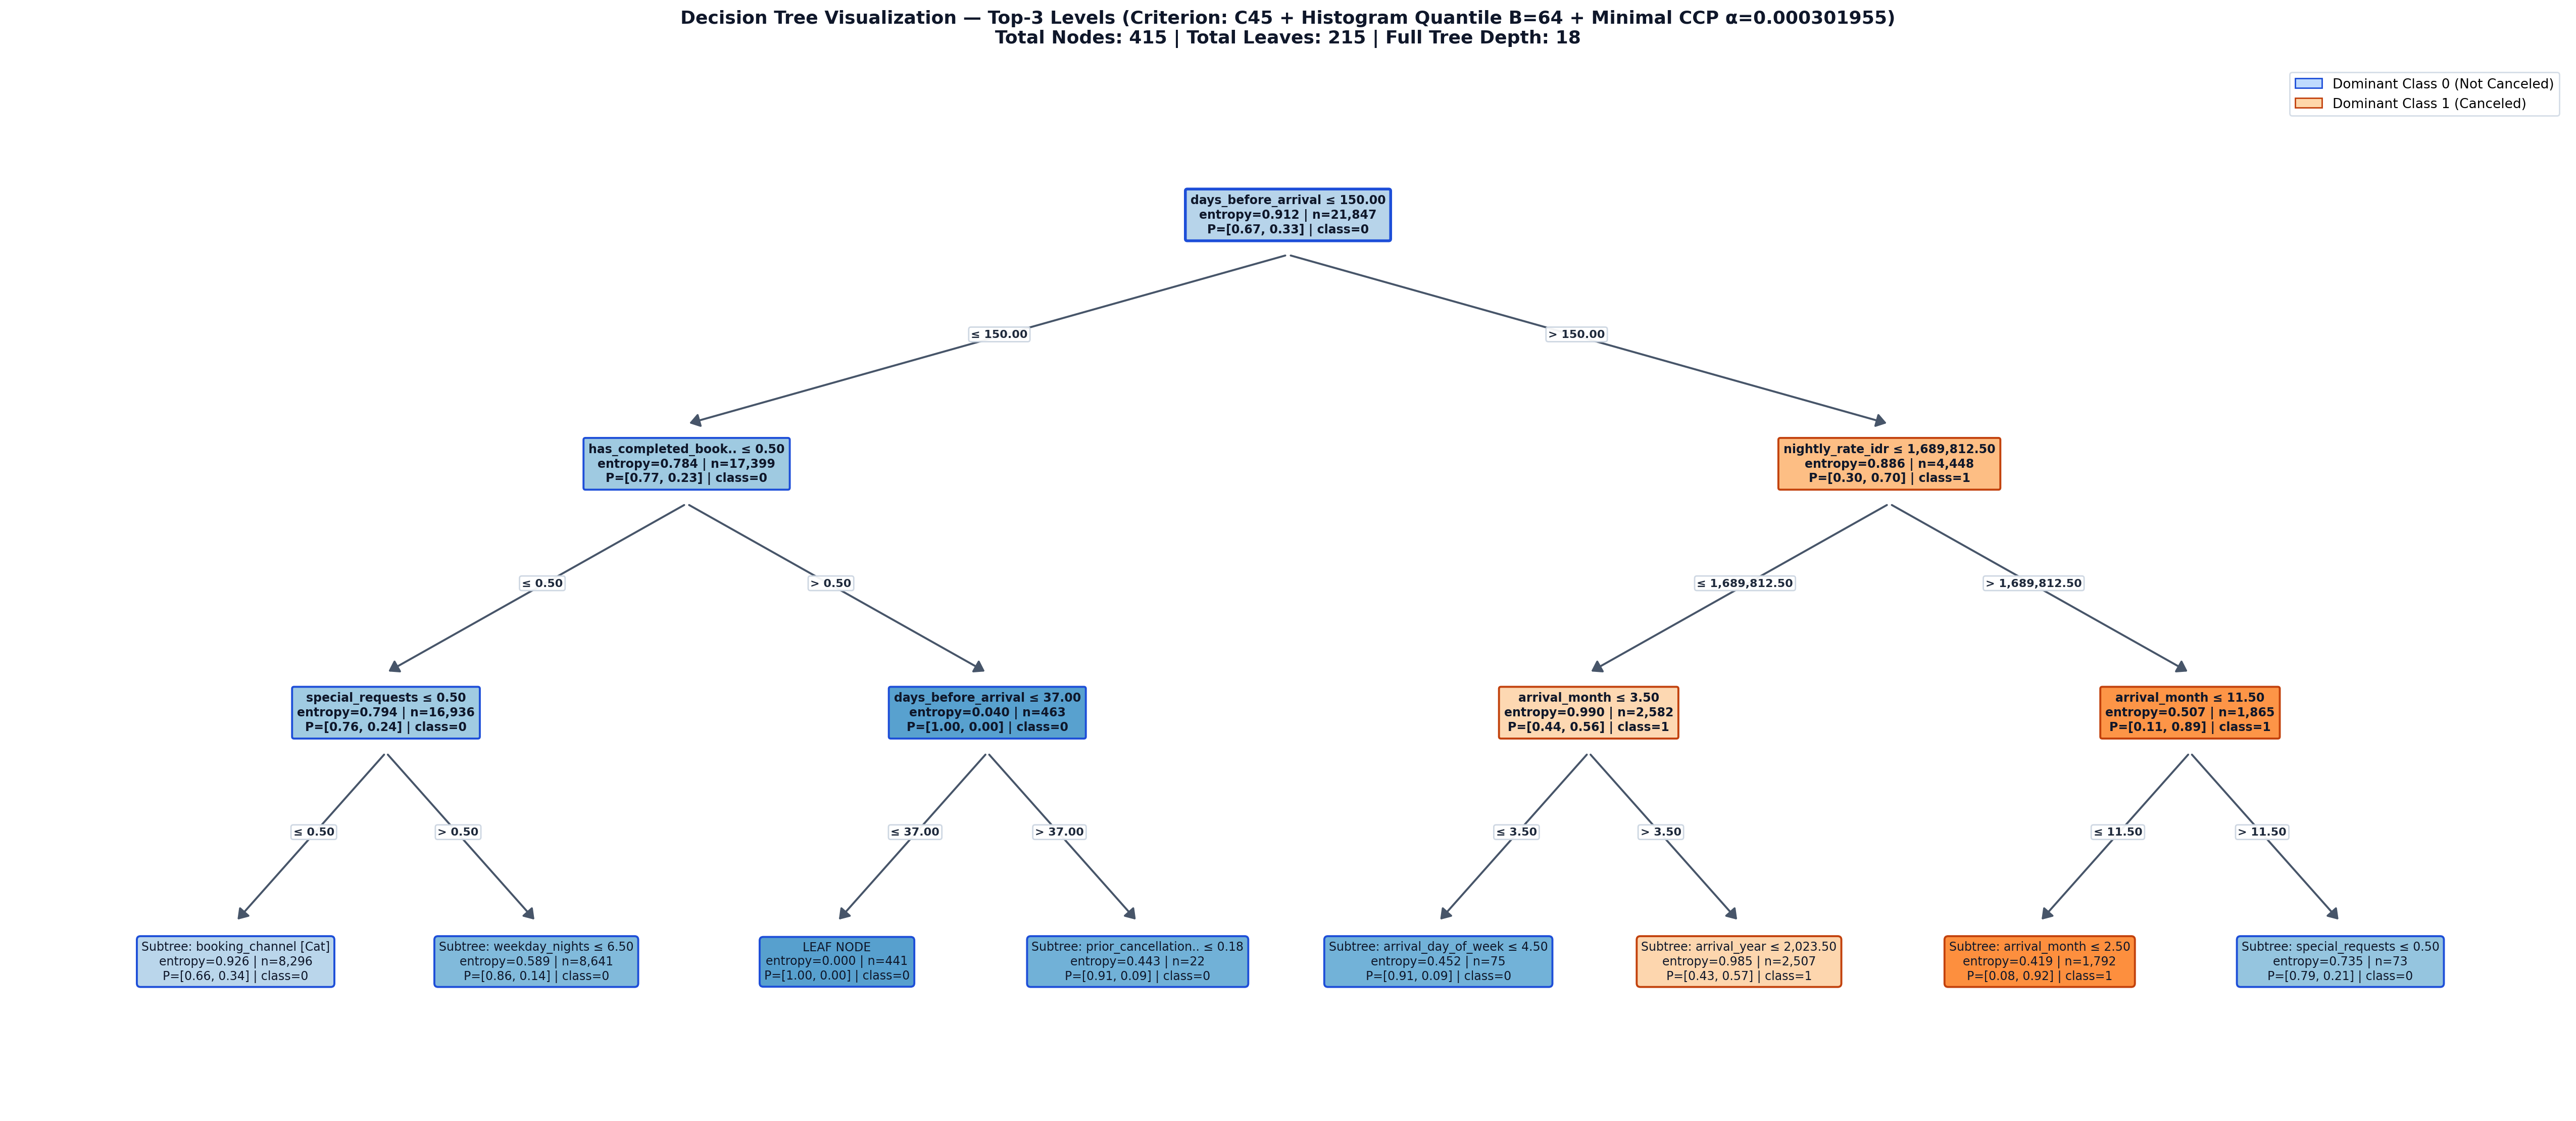

In [63]:
# === Bagian Anggota 2 (13524053): Ablation Study Bonus #6, McNemar, 5-Fold CV & Visualisasi Top-3 ===

# 1. Jalankan kandidat optimasi di luar salindia (Opsi B, Opsi C, dan Opsi A1 Pemenang)
dtl_bonus_configs = [
    (
        'Opsi B: C4.5 Hist(B=64) + Minimal CCP',
        lambda: DecisionTree(
            criterion='c45', split_strategy='histogram', max_bins=64,
            missing_strategy='fractional', max_depth=18, min_samples_leaf=5,
            use_pruning=True, pruning_method='ccp', ccp_alpha=0.0003,
            categorical_features=dtl_cat_indices, random_state=CFG.SEED,
        ),
    ),
    (
        'Opsi C: C4.5 Hist(B=64) + Surrogate Splits + CCP',
        lambda: DecisionTree(
            criterion='c45', split_strategy='histogram', max_bins=64,
            missing_strategy='surrogate', max_surrogates=3, max_depth=18,
            min_samples_leaf=5, use_pruning=True, pruning_method='ccp', ccp_alpha=0.0003,
            categorical_features=dtl_cat_indices, random_state=CFG.SEED,
        ),
    ),
    (
        'Opsi A1 (Pemenang): PSO + C4.5 Hist(B=64) + CCP',
        lambda: PSODecisionTreeOptimizer(
            criterion='c45', split_strategy='histogram', max_bins=64,
            missing_strategy='fractional', n_particles=8, n_iters=4,
            categorical_features=dtl_cat_indices, random_state=CFG.SEED,
        ),
    ),
]

pso_winner_opt = None
ablation_all_rows = list(dtl_ablation_rows)

for label, builder in dtl_bonus_configs:
    t0 = time.perf_counter()
    clf = builder()
    clf.fit(X_tr_dtl, y_tr_dtl)
    elapsed = time.perf_counter() - t0
    preds = clf.predict(X_va_dtl)
    dtl_val_preds[label] = preds
    tree_obj = clf.best_model_ if isinstance(clf, PSODecisionTreeOptimizer) else clf
    dtl_models[label] = tree_obj
    if isinstance(clf, PSODecisionTreeOptimizer):
        pso_winner_opt = clf
    ablation_all_rows.append({
        'Konfigurasi C4.5 (Holdout val_dtl)': label,
        'Val Macro F1': macro_f1_score(y_va_dtl, preds),
        'Macro F1 (NaN)': macro_f1_score(y_va_dtl[has_nan_base], preds[has_nan_base]),
        'Macro F1 (Full)': macro_f1_score(y_va_dtl[~has_nan_base], preds[~has_nan_base]),
        'Accuracy': accuracy_score(y_va_dtl, preds),
        'Precision': precision_score(y_va_dtl, preds),
        'Recall': recall_score(y_va_dtl, preds),
        'Cost (2FP+FN)': calculate_custom_cost(y_va_dtl, preds),
        'Nodes': tree_obj.get_n_nodes(),
        'Depth': tree_obj.get_depth(),
        'Time (s)': elapsed,
    })

df_c45_ablation = pd.DataFrame(ablation_all_rows)
print('=== TABEL ABLATION STUDY BONUS #6 — VARIAN C4.5 (BASELINE KULIAH VS OPSI A, B, C) ===')
display(df_c45_ablation.round(4))

winner_label = 'Opsi A1 (Pemenang): PSO + C4.5 Hist(B=64) + CCP'
best_c45_model = pso_winner_opt.best_model_
best_c45_model.feature_names_ = dtl_feat_names
best_c45_preds = dtl_val_preds[winner_label]
bp = pso_winner_opt.best_params_

print(f'\n[PSO Best Params] {bp} | Inner Holdout Fitness: {pso_winner_opt.best_score_:.5f}')
print(f'[PSO Convergence] {[(h["iter"], round(h["g_best_macro_f1"], 5)) for h in pso_winner_opt.history_]}')

# 2. Uji Signifikansi Statistik McNemar (Baseline REP Materi 10c vs Opsi A1 Pemenang)
b_mc, c_mc, stat_mc, p_mc = mcnemar_test(
    y_va_dtl,
    dtl_val_preds['Baseline Kuliah: C4.5 Exact + REP (Materi 10c)'],
    best_c45_preds,
)
print(f'[McNemar Test — Baseline REP vs Opsi A1] b={b_mc}, c={c_mc}, chi2={stat_mc:.4f}, p-value={p_mc:.6f}')

# 3. Verifikasi Stabilitas 5-Fold Cross-Validation pada train_dtl (Anti-Overfitting)
cv_tr_f1, cv_va_f1 = [], []
for tr_idx, va_idx in k_fold_split(X_tr_dtl, y_tr_dtl, k=5, seed=CFG.SEED):
    m_cv = DecisionTree(
        criterion='c45', split_strategy='histogram', max_bins=64, missing_strategy='fractional',
        max_depth=bp['max_depth'], min_samples_leaf=bp['min_samples_leaf'],
        min_samples_split=bp['min_samples_split'], use_pruning=True, pruning_method='ccp',
        ccp_alpha=bp['ccp_alpha'], categorical_features=dtl_cat_indices, random_state=CFG.SEED,
    )
    m_cv.fit(X_tr_dtl[tr_idx], y_tr_dtl[tr_idx])
    cv_tr_f1.append(macro_f1_score(y_tr_dtl[tr_idx], m_cv.predict(X_tr_dtl[tr_idx])))
    cv_va_f1.append(macro_f1_score(y_tr_dtl[va_idx], m_cv.predict(X_tr_dtl[va_idx])))

print(
    f'[5-Fold CV Stabilitas Opsi A1] Train Macro F1: {np.mean(cv_tr_f1):.4f} ± {np.std(cv_tr_f1):.4f} '
    f'| Val Macro F1: {np.mean(cv_va_f1):.4f} ± {np.std(cv_va_f1):.4f} '
    f'| Gap: {np.mean(cv_tr_f1) - np.mean(cv_va_f1):.4f}'
)

# Perbarui registry evaluasi dengan versi DTL teroptimasi
model_eval_results['DTL C4.5 (Improved Opsi A1)'] = {
    'Val Macro F1': macro_f1_score(y_va_dtl, best_c45_preds),
    'Accuracy': accuracy_score(y_va_dtl, best_c45_preds),
    'Precision': precision_score(y_va_dtl, best_c45_preds),
    'Recall': recall_score(y_va_dtl, best_c45_preds),
    'Cost (2FP+FN)': calculate_custom_cost(y_va_dtl, best_c45_preds),
}

# 4. Bonus #2: Visualisasi Top-N Tree (top_n=3)
dtl_plot_path = CFG.OUTPUT_DIR / 'plots' / 'dtl_tree_top_n.png'
export_tree_visualization(
    best_c45_model,
    top_n=3,
    feature_names=dtl_feat_names,
    output_path=str(dtl_plot_path),
)
print(f'[Bonus #2 Visualisasi Top-3] Tersimpan di: {dtl_plot_path}')
if Image is not None and dtl_plot_path.exists():
    display(Image(filename=str(dtl_plot_path)))

### Bagian Anggota 4 (`13524057`) Support Vector Machine: Kernel Laplacian, Tuning 5-Fold CV, Ablasi Fitur, Validasi Statistik & Visualisasi 2D

Perbaikan model SVM dibangun di atas hasil blok *Modeling and Validation* (tiga kernel: *Linear*, *Polynomial*, *Gaussian/RBF*). Seluruh keputusan pemilihan dibuat dari data latih saja, sedangkan *validation set* hanya dipakai untuk pelaporan.

1. **Kernel Laplacian:** perbaikan utama adalah mengganti ukuran jarak pada kernel dari jarak Euklides kuadrat (RBF) menjadi jarak Manhattan, yaitu $K(x, x') = \exp(-\gamma \lVert x - x' \rVert_1) = \prod_k \exp(-\gamma\, |x_k - x'_k|)$ [S5]. Karena selisih fitur tidak dikuadratkan, satu fitur dengan selisih besar tidak langsung mendominasi jarak, dan kernel ini dapat dipandang sebagai hasil kali kernel satu dimensi per fitur. Kernel ini bersifat *positive semi-definite*, dihitung di `src/svm.py` per blok baris langsung ke buffer `float32` (puncak memori tetap sekitar satu matriks $n \times n$), dan dibandingkan dengan ketiga kernel pada blok sebelumnya.
2. **Tuning hyperparameter dengan *5-Fold Cross-Validation*:**
   - *Tahap 1:* pencarian acak pada skala log untuk $C$ dan $\gamma$ [S1], [S2], dilanjutkan *refinement* lokal di sekitar konfigurasi terbaik. Setiap konfigurasi dinilai dengan Macro F1 *5-fold stratified CV* pada subsampel berstrata dari `train_clean`.
   - Jika modul `src.svm_tuning` tidak tersedia, tahap konfirmasi langsung memakai dua kandidat Laplacian teratas dari hasil pencarian yang tercatat di bawah. Nilai parameter mengikuti presisi yang ditampilkan (empat desimal).
   - *Tahap 2:* konfigurasi teratas dikonfirmasi dengan *5-fold CV* pada subsampel yang lebih besar menggunakan `k_fold_split` (`src/utils.py`). Pada tahap ini skor keputusan *out-of-fold* (OOF) disimpan.
3. **Threshold keputusan:** ambang $f(x) \geq \tau$ dicari dari skor OOF (bukan dari *validation set*) untuk memaksimalkan Macro F1, tetapi hanya dipakai bila kenaikan Macro F1 OOF melebihi simpangan baku antar-*fold*. Jika tidak, $\tau = 0$. Biaya (2FP+FN) ikut dilaporkan karena menurunkan $\tau$ menambah prediksi kelas 1 dan dapat menaikkan FP, dan skor keputusan dari model yang dilatih pada subsampel tidak selalu sebanding dengan model yang dilatih pada seluruh data latih.
4. **Ablasi fitur interaksi:** dua fitur hasil kali atribut pendorong utama (`days_before_arrival` × `special_requests` dan `days_before_arrival` × `nightly_rate_idr`) dibandingkan terhadap fitur dasar menggunakan *fold* yang sama. Fitur interaksi hanya dipakai bila rata-rata Macro F1 CV naik lebih dari satu simpangan baku *fold* dasar.
5. **Validasi statistik dan stabilitas:**
   - **Uji McNemar** [S3], [S4] untuk menguji apakah selisih prediksi model teroptimasi terhadap baseline *Gaussian (RBF)* signifikan.
   - **Selisih Macro F1 *train* vs *validation* per *fold*** untuk memeriksa *overfitting*.
6. **Visualisasi bidang pemisah 2D (bonus):** karena data memiliki puluhan fitur, visualisasi dibuat pada dua fitur kontinu dengan korelasi mutlak terbesar terhadap target. Model baseline (pemenang blok sebelumnya) dan model Laplacian dilatih ulang pada subsampel berstrata di ruang dua fitur tersebut dengan $C$ dan $\gamma$ yang sama untuk kedua kernel (sengaja longgar agar bentuk batas terbaca, bukan hasil tuning), lalu digambar dengan `plot_svm_margin_2d` (garis $f(x)=0$, batas margin $f(x)=\pm 1$, dan *support vector*). Gambar ini memperlihatkan bentuk batas keputusan tiap kernel, bukan batas model penuh yang memakai seluruh fitur.

**Referensi SVM:**
- `[S1]` J. Bergstra dan Y. Bengio, "Random Search for Hyper-Parameter Optimization," *Journal of Machine Learning Research*, vol. 13, pp. 281-305, 2012.
- `[S2]` C.-W. Hsu, C.-C. Chang, dan C.-J. Lin, "A Practical Guide to Support Vector Classification," Dept. of Computer Science, National Taiwan University, 2003.
- `[S3]` Q. McNemar, "Note on the sampling error of the difference between correlated proportions or percentages," *Psychometrika*, vol. 12, no. 2, pp. 153-157, 1947.
- `[S4]` T. G. Dietterich, "Approximate Statistical Tests for Comparing Supervised Classification Learning Algorithms," *Neural Computation*, vol. 10, no. 7, pp. 1895-1923, 1998.
- `[S5]` M. G. Genton, "Classes of Kernels for Machine Learning: A Statistics Perspective," *Journal of Machine Learning Research*, vol. 2, pp. 299-312, 2001.

c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\src\svm.py:345: RuntimeWarning: Jumlah sampel pelatihan (3999) melebihi 3000; matriks kernel penuh ~0.06 GB (float32). Pertimbangkan max_samples untuk subsampling berstrata.
  warnings.warn(
c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\src\svm.py:345: RuntimeWarning: Jumlah sampel pelatihan (4000) melebihi 3000; matriks kernel penuh ~0.06 GB (float32). Pertimbangkan max_samples untuk subsampling berstrata.
  warnings.warn(
c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\src\svm.py:345: RuntimeWarning: Jumlah sampel pelatihan (4001) melebihi 3000; matriks kernel penuh ~0.06 GB (float32). Pertimbangkan max_samples untuk subsampling berstrata.
  warnings.warn(


=== TAHAP 1: 28 konfigurasi, 5-fold CV, laplacian (280s) ===


,C,gamma,CV Macro F1,Std fold,Fit time (s)
0,5.2813,0.1000,0.8176,0.0051,5.1596
1,6.9344,0.0718,0.8176,0.0033,5.5534
2,6.3112,0.0888,0.8172,0.0058,5.5340
3,4.6887,0.0637,0.8164,0.0054,4.7274
4,6.0860,0.0979,0.8153,0.0061,5.5153


c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\src\svm.py:345: RuntimeWarning: Jumlah sampel pelatihan (9600) melebihi 3000; matriks kernel penuh ~0.34 GB (float32). Pertimbangkan max_samples untuk subsampling berstrata.
  warnings.warn(
c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\src\svm.py:345: RuntimeWarning: Jumlah sampel pelatihan (9600) melebihi 3000; matriks kernel penuh ~0.34 GB (float32). Pertimbangkan max_samples untuk subsampling berstrata.
  warnings.warn(



=== TAHAP 2: konfirmasi 5-fold CV pada 12000 sampel (params terbaik: {'C': 6.9344, 'gamma': 0.0718}) ===
=== ABLASI FITUR INTERAKSI ===


,Fitur,CV Macro F1,Std fold,Dipakai
0,Dasar (52 fitur),0.8331,0.0096,True
1,Dasar + 2 interaksi (54 fitur),0.8362,0.0112,False



[Threshold OOF] tau=0 -> Macro F1 0.8331 | tau=-0.04 -> Macro F1 0.8340 | kenaikan 0.0009 vs std fold 0.0096 -> tidak dipakai (tau = 0)
[5-Fold CV Stabilitas] Train Macro F1: 0.9190 +- 0.0006 | Val Macro F1: 0.8331 +- 0.0096 | Gap: 0.0859


c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\src\svm.py:345: RuntimeWarning: Jumlah sampel pelatihan (21847) melebihi 3000; matriks kernel penuh ~1.78 GB (float32). Pertimbangkan max_samples untuk subsampling berstrata.
  warnings.warn(



=== VALIDATION: BASELINE VS IMPROVED (52 fitur) ===


,Konfigurasi,Val Macro F1,Accuracy,Precision,Recall,Cost (2FP+FN),TN,FP,FN,TP,Fit time (s)
0,Baseline Linear (blok sebelumnya),0.7411,0.7862,0.7226,0.5634,1555.0,3286,387,781,1008,NaN
1,Baseline Polynomial (blok sebelumnya),0.7967,0.8303,0.7968,0.6467,1222.0,3378,295,632,1157,NaN
2,Baseline Gaussian (RBF) (blok sebelumnya),0.8051,0.8361,0.7996,0.6669,1194.0,3374,299,596,1193,NaN
3,Improved: kernel Laplacian + tuning 5-fold CV ...,0.8464,0.8685,0.8345,0.7468,983.0,3408,265,453,1336,27.8077
4,"Improved: + threshold tau=-0.04 (kandidat, tid...",0.8481,0.8693,0.8291,0.7568,993.0,3394,279,435,1354,27.8077


Catatan: Macro F1 adalah metrik Kaggle; threshold yang lebih rendah menambah prediksi kelas 1 sehingga FP, dan karena itu Cost (2FP+FN), dapat naik. Skor OOF dari model yang dilatih pada subsampel tidak selalu berpindah ke model yang dilatih pada seluruh train, sebab itu threshold hanya dipakai bila kenaikannya jelas.
[McNemar: Baseline Gaussian (RBF) vs Improved] b=124, c=301, chi2=72.8847, p-value=0.000000


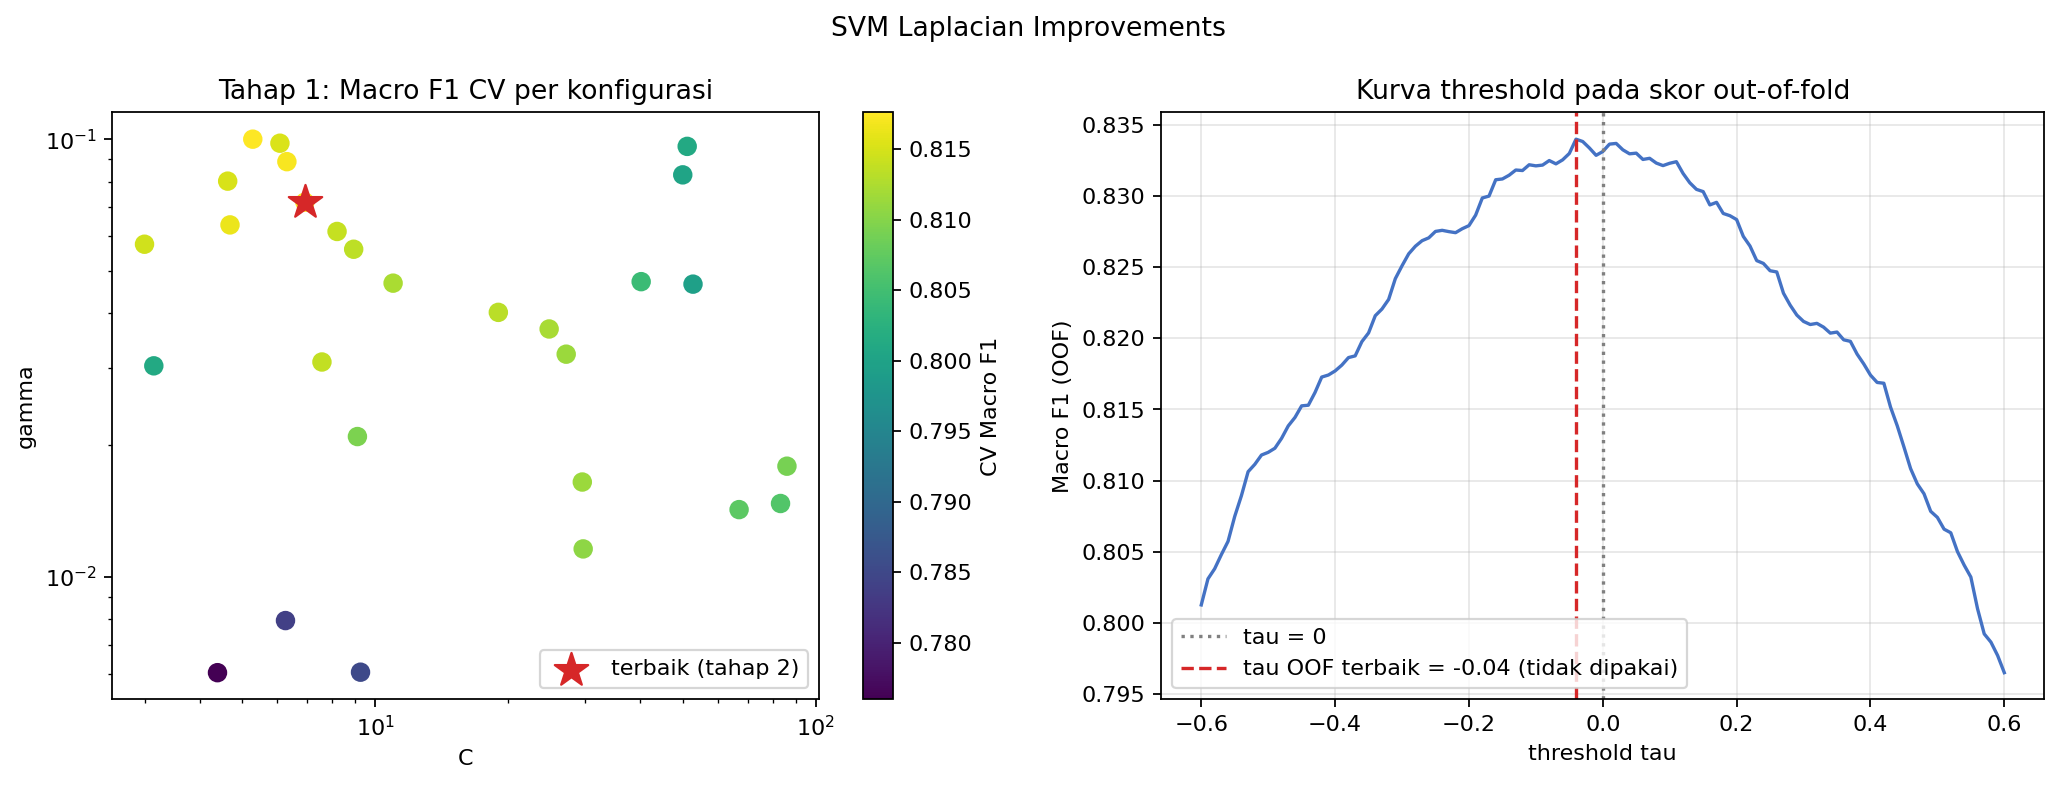

[Improvement Plot Saved] c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\plots\svm_improvements.png

=== VISUALISASI 2D: fitur days_before_arrival dan nightly_rate_idr (|korelasi| terhadap target: 0.430, 0.134) ===


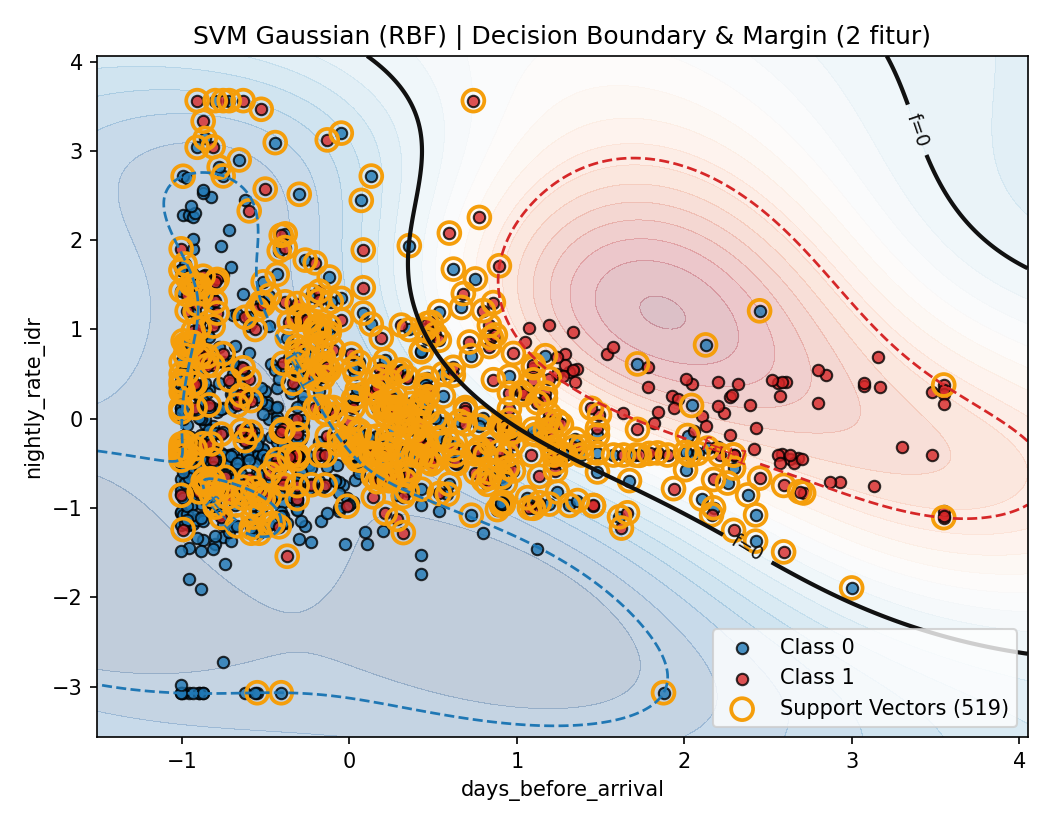

[2D Plot Saved] c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\plots\svm_margin_2d_rbf.png | Macro F1 validation hanya dengan 2 fitur: 0.6763


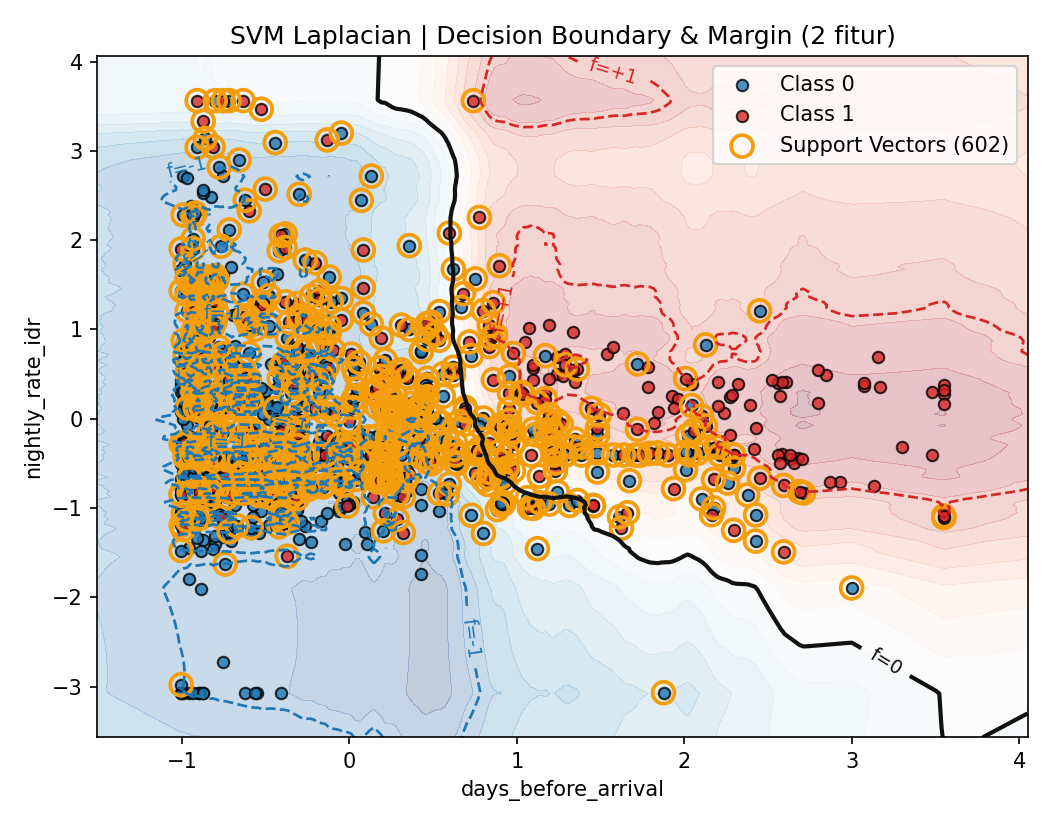

[2D Plot Saved] c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\plots\svm_margin_2d_laplacian.png | Macro F1 validation hanya dengan 2 fitur: 0.6883


c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\src\svm.py:345: RuntimeWarning: Jumlah sampel pelatihan (22000) melebihi 3000; matriks kernel penuh ~1.80 GB (float32). Pertimbangkan max_samples untuk subsampling berstrata.
  warnings.warn(


[Improved Submission] c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\submissions\submission_svm_improved.csv | kernel=laplacian | params={'C': 6.9344, 'gamma': 0.0718} | tau=+0.00 | interaksi=False | proporsi kelas 1=0.293


In [64]:
# === SVM Improvements: Kernel Laplacian, Tuning 5-Fold CV, Threshold, Ablasi Fitur, McNemar & Visualisasi 2D ===
import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage
from scipy.stats import chi2
from sklearn.model_selection import train_test_split
from src.svm import SVM, plot_svm_margin_2d
try:
    from src.svm_tuning import tune_svm
except ModuleNotFoundError as error:
    if error.name != 'src.svm_tuning':
        raise
    tune_svm = None
from src.utils import (
    accuracy_score, confusion_matrix, precision_score, recall_score,
    f1_score, calculate_custom_cost, k_fold_split,
)

assert 'val_preds_store' in globals(), 'Jalankan blok SVM Modeling and Validation terlebih dahulu.'

# Pengaturan komputasi (nilai lebih besar = hasil lebih stabil tetapi lebih lama)
IMP_KERNEL          = 'laplacian'   # kernel perbaikan ('laplacian' = jarak L1; 'rbf' untuk pembanding)
IMP_CV              = 5             # jumlah fold
IMP_TUNE_SAMPLES    = 5000          # subsampel berstrata untuk pencarian tahap 1
IMP_N_ITER          = 20            # konfigurasi acak pada tahap 1
IMP_N_REFINE        = 8             # konfigurasi refinement pada tahap 1
IMP_CONFIRM_SAMPLES = 12000         # subsampel untuk konfirmasi 5-fold CV tahap 2 (None = seluruh train)
IMP_TOP_K           = 2             # jumlah konfigurasi teratas yang dikonfirmasi
IMP_VIZ_SAMPLES     = 1000          # jumlah titik pada visualisasi 2D
IMP_VIZ_C, IMP_VIZ_GAMMA = 1.0, 0.25    # C dan gamma visualisasi 2D (sengaja longgar agar batas terbaca; bukan hasil tuning)
IMP_RANGES = {                      # rentang pencarian (C, gamma) per kernel
    'laplacian': {'C': (3.0, 100.0), 'gamma': (0.005, 0.1)},
    'rbf':       {'C': (1.0, 40.0),  'gamma': (0.005, 0.2)},
}[IMP_KERNEL]


def mcnemar_stat(y_true, pred_a, pred_b):
    """Uji McNemar dengan koreksi kontinuitas Edwards (df=1)."""
    correct_a, correct_b = (pred_a == y_true), (pred_b == y_true)
    b = int(np.sum(correct_a & ~correct_b))
    c = int(np.sum(~correct_a & correct_b))
    stat = ((abs(b - c) - 1.0) ** 2) / (b + c) if (b + c) > 0 else 0.0
    p_val = float(1.0 - chi2.cdf(stat, df=1)) if (b + c) > 0 else 1.0
    return b, c, stat, p_val


def add_interactions(df):
    """Dua fitur interaksi dari pendorong utama (kolom sudah terstandardisasi oleh DataPipeline)."""
    out = df.copy()
    out['dba_x_special_requests'] = out['days_before_arrival'] * out['special_requests']
    out['dba_x_nightly_rate'] = out['days_before_arrival'] * out['nightly_rate_idr']
    return out


def cv_oof_svm(params, X, y, folds):
    """5-fold CV: Macro F1 train dan validasi per fold, serta skor keputusan out-of-fold."""
    oof, tr_f1, va_f1 = np.zeros(len(y)), [], []
    for tr_idx, va_idx in folds:
        model = SVM(kernel=IMP_KERNEL, **params, max_iter=SVM_FIT_MAX_ITER,
                    probability=False, random_state=CFG.SEED).fit(X[tr_idx], y[tr_idx])
        oof[va_idx] = model.decision_function(X[va_idx])
        tr_f1.append(macro_f1_score(y[tr_idx], model.predict(X[tr_idx])))
        va_f1.append(macro_f1_score(y[va_idx], (oof[va_idx] >= 0).astype(int)))
    return np.array(tr_f1), np.array(va_f1), oof


def metrics_row(label, y_true, y_pred, extra=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred)
    row = {'Konfigurasi': label, 'Val Macro F1': macro_f1_score(y_true, y_pred),
           'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred),
           'Recall': recall_score(y_true, y_pred), 'Cost (2FP+FN)': calculate_custom_cost(y_true, y_pred),
           'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}
    row.update(extra or {})
    return row


# 1. TAHAP 1: siapkan kandidat untuk konfirmasi 5-fold CV
if tune_svm is None:
    # Dua kandidat Laplacian teratas yang tercatat pada hasil tuning sebelumnya.
    laplacian_candidates = [{'C': 5.2813, 'gamma': 0.1000}, {'C': 6.9344, 'gamma': 0.0718}]
    stage1_params = laplacian_candidates if IMP_KERNEL == 'laplacian' else [best_svm_by_kernel[IMP_KERNEL]['params']]
    print('=== TAHAP 1: modul svm_tuning tidak tersedia, konfirmasi kandidat yang sudah tercatat ===')
    display(pd.DataFrame(stage1_params[:IMP_TOP_K]))
else:
    space = {'kernel': [IMP_KERNEL], 'C': ('log', *IMP_RANGES['C']), 'gamma': ('log', *IMP_RANGES['gamma'])}
    t0 = time.perf_counter()
    stage1 = tune_svm(
        X_tr_svm, y_tr_svm, param_space=space, search='random', n_iter=IMP_N_ITER, n_refine=IMP_N_REFINE,
        cv=IMP_CV, scoring='macro_f1', tune_samples=IMP_TUNE_SAMPLES, tune_max_iter=SVM_TUNE_MAX_ITER,
        refit=False, random_state=CFG.SEED, verbose=False,
    )
    df_stage1 = pd.DataFrame([
        {'C': r['params']['C'], 'gamma': r['params']['gamma'], 'CV Macro F1': r['mean'],
         'Std fold': r['std'], 'Fit time (s)': r['seconds']} for r in stage1.results
    ])
    print('=== TAHAP 1: {} konfigurasi, {}-fold CV, {} ({:.0f}s) ==='.format(
        len(df_stage1), IMP_CV, IMP_KERNEL, time.perf_counter() - t0))
    display(df_stage1.head(5).round(4))
    stage1_params = [{k: v for k, v in r['params'].items() if k != 'kernel'} for r in stage1.results]

# 2. TAHAP 2: konfirmasi top-K dengan 5-fold CV (k_fold_split) + skor OOF
if IMP_CONFIRM_SAMPLES is not None and IMP_CONFIRM_SAMPLES < len(y_tr_svm):
    idx_conf, _ = train_test_split(np.arange(len(y_tr_svm)), train_size=IMP_CONFIRM_SAMPLES,
                                   random_state=CFG.SEED, stratify=y_tr_svm)
else:
    idx_conf = np.arange(len(y_tr_svm))
X_conf, y_conf = X_tr_svm[idx_conf], y_tr_svm[idx_conf]
folds = list(k_fold_split(X_conf, y_conf, k=IMP_CV, seed=CFG.SEED))

confirmed = []
for params in stage1_params[:IMP_TOP_K]:
    t0 = time.perf_counter()
    tr_f1, va_f1, oof = cv_oof_svm(params, X_conf, y_conf, folds)
    confirmed.append({'params': params, 'tr_f1': tr_f1, 'va_f1': va_f1, 'oof': oof,
                      'seconds': time.perf_counter() - t0})
confirmed.sort(key=lambda c: (-c['va_f1'].mean(), c['va_f1'].std()))
best_conf = confirmed[0]

# 3. ABLASI FITUR INTERAKSI (fold yang sama, konfigurasi terbaik tahap 2)
X_conf_int = add_interactions(df_tr_cln[feature_cols]).to_numpy(dtype=float)[idx_conf]
tr_f1_i, va_f1_i, oof_i = cv_oof_svm(best_conf['params'], X_conf_int, y_conf, folds)
use_interactions = va_f1_i.mean() > best_conf['va_f1'].mean() + best_conf['va_f1'].std()
df_ablation = pd.DataFrame([
    {'Fitur': 'Dasar ({} fitur)'.format(len(feature_cols)), 'CV Macro F1': best_conf['va_f1'].mean(),
     'Std fold': best_conf['va_f1'].std(), 'Dipakai': not use_interactions},
    {'Fitur': 'Dasar + 2 interaksi ({} fitur)'.format(len(feature_cols) + 2), 'CV Macro F1': va_f1_i.mean(),
     'Std fold': va_f1_i.std(), 'Dipakai': use_interactions},
])
print('\n=== TAHAP 2: konfirmasi {}-fold CV pada {} sampel (params terbaik: {}) ==='.format(
    IMP_CV, len(idx_conf), {k: round(v, 4) for k, v in best_conf['params'].items()}))
print('=== ABLASI FITUR INTERAKSI ===')
display(df_ablation.round(4))
chosen_oof = oof_i if use_interactions else best_conf['oof']
chosen_tr_f1 = tr_f1_i if use_interactions else best_conf['tr_f1']
chosen_va_f1 = va_f1_i if use_interactions else best_conf['va_f1']

# 4. THRESHOLD KEPUTUSAN DARI SKOR OOF (bukan dari validation set)
thr_grid = np.linspace(-0.6, 0.6, 121)
oof_f1_curve = np.array([macro_f1_score(y_conf, (chosen_oof >= t).astype(int)) for t in thr_grid])
best_thr = float(thr_grid[int(np.argmax(oof_f1_curve))])
oof_f1_zero = macro_f1_score(y_conf, (chosen_oof >= 0).astype(int))
oof_gain = float(oof_f1_curve.max() - oof_f1_zero)
use_threshold = oof_gain > chosen_va_f1.std()      # dipakai hanya bila kenaikan melebihi simpangan baku fold
final_thr = best_thr if use_threshold else 0.0
print('\n[Threshold OOF] tau=0 -> Macro F1 {:.4f} | tau={:+.2f} -> Macro F1 {:.4f} | kenaikan {:.4f} vs std fold {:.4f} '
      '-> {}'.format(oof_f1_zero, best_thr, oof_f1_curve.max(), oof_gain, chosen_va_f1.std(),
                     'threshold dipakai' if use_threshold else 'tidak dipakai (tau = 0)'))
print('[5-Fold CV Stabilitas] Train Macro F1: {:.4f} +- {:.4f} | Val Macro F1: {:.4f} +- {:.4f} | Gap: {:.4f}'.format(
    chosen_tr_f1.mean(), chosen_tr_f1.std(), chosen_va_f1.mean(), chosen_va_f1.std(),
    chosen_tr_f1.mean() - chosen_va_f1.mean()))

# 5. MODEL AKHIR PADA TRAIN PENUH -> EVALUASI SEKALI PADA VALIDATION
if use_interactions:
    X_tr_imp = add_interactions(df_tr_cln[feature_cols]).to_numpy(dtype=float)
    X_va_imp = add_interactions(df_va_cln[feature_cols]).to_numpy(dtype=float)
else:
    X_tr_imp, X_va_imp = X_tr_svm, X_va_svm
t0 = time.perf_counter()
imp_model = SVM(kernel=IMP_KERNEL, **best_conf['params'], max_iter=SVM_FIT_MAX_ITER,
                probability=False, random_state=CFG.SEED).fit(X_tr_imp, y_tr_svm)
imp_fit_seconds = time.perf_counter() - t0
imp_scores_va = imp_model.decision_function(X_va_imp)
pred_imp_zero = (imp_scores_va >= 0).astype(int)
pred_imp_tuned = (imp_scores_va >= best_thr).astype(int)

df_svm_improved = pd.DataFrame([
    *[metrics_row('Baseline {} (blok sebelumnya)'.format(kernel_labels[k]), y_va_svm, val_preds_store[k])
      for k in svm_kernels],
    metrics_row('Improved: kernel {} + tuning 5-fold CV (tau=0)'.format(kernel_labels[IMP_KERNEL]),
                y_va_svm, pred_imp_zero, {'Fit time (s)': imp_fit_seconds}),
    metrics_row('Improved: + threshold tau={:+.2f}{}'.format(best_thr, '' if use_threshold else ' (kandidat, tidak dipakai)'),
                y_va_svm, pred_imp_tuned, {'Fit time (s)': imp_fit_seconds}),
])
pred_imp_final = pred_imp_tuned if use_threshold else pred_imp_zero
print('\n=== VALIDATION: BASELINE VS IMPROVED ({} fitur) ==='.format(X_tr_imp.shape[1]))
display(df_svm_improved.round(4))
print('Catatan: Macro F1 adalah metrik Kaggle; threshold yang lebih rendah menambah prediksi kelas 1 sehingga '
      'FP, dan karena itu Cost (2FP+FN), dapat naik. Skor OOF dari model yang dilatih pada subsampel tidak selalu '
      'berpindah ke model yang dilatih pada seluruh train, sebab itu threshold hanya dipakai bila kenaikannya jelas.')

# 6. UJI MCNEMAR: pemenang blok sebelumnya (baseline) vs improved
b_mc, c_mc, stat_mc, p_mc = mcnemar_stat(y_va_svm, val_preds_store[best_svm_kernel], pred_imp_final)
print('[McNemar: Baseline {} vs Improved] b={}, c={}, chi2={:.4f}, p-value={:.6f}'.format(
    kernel_labels[best_svm_kernel], b_mc, c_mc, stat_mc, p_mc))

# 7. REGISTRASI KE TABEL AGREGASI MODEL EVALUATION
model_eval_results = globals().get('model_eval_results', {})
model_eval_results['SVM {} (Improved)'.format(IMP_KERNEL.title())] = {
    'Val Macro F1': macro_f1_score(y_va_svm, pred_imp_final),
    'Accuracy': accuracy_score(y_va_svm, pred_imp_final),
    'Precision': precision_score(y_va_svm, pred_imp_final),
    'Recall': recall_score(y_va_svm, pred_imp_final),
    'Cost (2FP+FN)': calculate_custom_cost(y_va_svm, pred_imp_final),
}

# 8. VISUALISASI: hasil pencarian tahap 1 dan kurva threshold OOF
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc = axes[0].scatter(df_stage1['C'], df_stage1['gamma'], c=df_stage1['CV Macro F1'], cmap='viridis', s=60)
axes[0].scatter(*[best_conf['params'][k] for k in ('C', 'gamma')], marker='*', s=250,
                color='#D62728', label='terbaik (tahap 2)')
axes[0].set(xscale='log', yscale='log', xlabel='C', ylabel='gamma', title='Tahap 1: Macro F1 CV per konfigurasi')
axes[0].legend()
fig.colorbar(sc, ax=axes[0], label='CV Macro F1')
axes[1].plot(thr_grid, oof_f1_curve, color='#4472C4')
axes[1].axvline(0, color='gray', linestyle=':', label='tau = 0')
axes[1].axvline(best_thr, color='#D62728', linestyle='--',
                label='tau OOF terbaik = {:+.2f}{}'.format(best_thr, '' if use_threshold else ' (tidak dipakai)'))
axes[1].set(xlabel='threshold tau', ylabel='Macro F1 (OOF)', title='Kurva threshold pada skor out-of-fold')
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.suptitle('SVM {} Improvements'.format(IMP_KERNEL.title()))
fig.tight_layout()
imp_plot_path = CFG.OUTPUT_DIR / 'plots' / 'svm_improvements.png'
imp_plot_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(imp_plot_path, dpi=160, bbox_inches='tight')
plt.close(fig)
display(NotebookImage(filename=str(imp_plot_path)))
print('[Improvement Plot Saved] {}'.format(imp_plot_path))

# 8b. VISUALISASI BIDANG PEMISAH 2D (bonus): baseline vs kernel perbaikan pada dua fitur kontinu terkuat
cont_cols = [col for col in feature_cols if df_tr_cln[col].nunique() > 10]
abs_corr = {col: abs(np.corrcoef(df_tr_cln[col].to_numpy(dtype=float), y_tr_svm)[0, 1]) for col in cont_cols}
viz_cols = sorted(abs_corr, key=abs_corr.get, reverse=True)[:2]
idx_viz, _ = train_test_split(np.arange(len(y_tr_svm)), train_size=min(IMP_VIZ_SAMPLES, len(y_tr_svm)),
                              random_state=CFG.SEED, stratify=y_tr_svm)
X_viz = df_tr_cln[viz_cols].to_numpy(dtype=float)[idx_viz]
y_viz = y_tr_svm[idx_viz]
X_viz_val = df_va_cln[viz_cols].to_numpy(dtype=float)


viz_kernels = [best_svm_kernel, IMP_KERNEL]
print('\n=== VISUALISASI 2D: fitur {} dan {} (|korelasi| terhadap target: {:.3f}, {:.3f}) ==='.format(
    viz_cols[0], viz_cols[1], abs_corr[viz_cols[0]], abs_corr[viz_cols[1]]))
for kernel in viz_kernels:
    viz_model = SVM(kernel=kernel, C=IMP_VIZ_C, gamma=IMP_VIZ_GAMMA, max_iter=SVM_FIT_MAX_ITER,
                    probability=False, random_state=CFG.SEED).fit(X_viz, y_viz)
    viz_path = plot_svm_margin_2d(
        viz_model, X_viz, y_viz, output_path=str(CFG.OUTPUT_DIR / 'plots' / 'svm_margin_2d_{}.png'.format(kernel)),
        title='SVM {} | Decision Boundary & Margin (2 fitur)'.format(kernel_labels[kernel]),
        xlabel=viz_cols[0], ylabel=viz_cols[1],
    )
    f1_viz = macro_f1_score(y_va_svm, viz_model.predict(X_viz_val))
    display(NotebookImage(filename=viz_path))
    print('[2D Plot Saved] {} | Macro F1 validation hanya dengan 2 fitur: {:.4f}'.format(viz_path, f1_viz))

# 9. SUBMISSION TEROPTIMASI: refit pada train+val, prediksi test dengan threshold hasil OOF
X_all_df = final_preprocessor.transform(df_all_raw, use_pca=False)
X_test_df = final_preprocessor.transform(df_test_raw, use_pca=False)
if use_interactions:
    X_all_df, X_test_df = add_interactions(X_all_df), add_interactions(X_test_df)
imp_final = SVM(kernel=IMP_KERNEL, **best_conf['params'], max_iter=SVM_FIT_MAX_ITER,
                max_samples=SVM_FINAL_MAX_SAMPLES, probability=False, random_state=CFG.SEED
                ).fit(X_all_df.to_numpy(dtype=float), y_all_svm)
y_test_pred_imp = (imp_final.decision_function(X_test_df.to_numpy(dtype=float)) >= final_thr).astype(int)
df_sub_imp = pd.DataFrame({id_col: df_test_raw[id_col].astype(str), target_col: y_test_pred_imp})
assert df_sub_imp.shape == df_sample_sub.shape
assert list(df_sub_imp.columns) == list(df_sample_sub.columns)
assert df_sub_imp[id_col].equals(df_sample_sub[id_col])
assert set(df_sub_imp[target_col].unique()).issubset({0, 1})
imp_submission_path = CFG.OUTPUT_DIR / 'submissions' / 'submission_svm_improved.csv'
imp_submission_path.parent.mkdir(parents=True, exist_ok=True)
df_sub_imp.to_csv(imp_submission_path, index=False)
print('[Improved Submission] {} | kernel={} | params={} | tau={:+.2f} | interaksi={} | proporsi kelas 1={:.3f}'.format(
    imp_submission_path, IMP_KERNEL, {k: round(v, 4) for k, v in best_conf['params'].items()},
    final_thr, use_interactions, y_test_pred_imp.mean()))

### Animasi kontur Logistic Regression

Untuk menampilkan permukaan loss dalam dua dimensi, model demonstrasi L1 (C=1) dilatih terpisah pada satu fitur terstandardisasi, `days_before_arrival`. Sumbunya adalah intersep dan koefisien fitur. Garis kontur menunjukkan rata-rata log-loss ditambah penalti L1, dan lintasan mengikuti pembaruan FISTA yang diterima. Atur `logreg_render_contour = True` untuk membuat ulang video.

In [12]:
logreg_render_contour = False
logreg_video_path = CFG.OUTPUT_DIR / "videos" / "logreg_loss_contour.mp4"
logreg_existing_video = logreg_video_path if logreg_video_path.is_file() else logreg_video_path.with_suffix(".gif")
if logreg_render_contour or not logreg_existing_video.is_file():
    logreg_contour_data = logreg_transformer.pipeline_.transform(train_set)[["days_before_arrival"]]
    logreg_contour_data = logreg_contour_data.assign(**{CFG.TARGET: y_train})
    logreg_video_path = generate_loss_contour_video(
        logreg_contour_data, target_column=CFG.TARGET, output_path=logreg_video_path,
    )
else:
    logreg_video_path = logreg_existing_video
print(f"Animasi: {logreg_video_path.relative_to(ROOT_DIR)}")

Animasi: output\videos\logreg_loss_contour.mp4


### Bagian Anggota 5 (`13524063`) — Optimasi Naive Bayes (Bonus #6) & Graf Bayesian Network (Bonus #5)

1. **E1 — Pembobotan atribut.** Setiap log-likelihood ratio fitur memiliki bobot nonnegatif. Bobot dan intersep dipelajari dengan *projected Adam* untuk meminimalkan *binary cross-entropy* dengan penalti L2. Pembobotan mengurangi kontribusi berulang dari fitur yang berkorelasi [1], [2].
2. **E2 — Rekayasa fitur.** Tambahkan tanggal booking hasil rekonstruksi, bin yang lebih halus, dan interaksi yang menangkap konteks seperti kanal pemesanan dan jarak waktu ke kedatangan.
3. **E3 — Target encoding adaptif.** Untuk setiap fitur atau interaksi, pilih koefisien *smoothing* dengan Brier score terkecil dari lima fold data latih. Smoothing menarik estimasi kategori dengan sampel sedikit ke prior latih [3], [4].
4. **Ablasi & graf.** Bandingkan empat tahap kumulatif pada ID validasi yang sama. Graf E0 menampilkan seluruh fitur terpilih sebagai anak dari `is_canceled`. Satu simpul dapat mewakili interaksi fitur. Struktur tersebut merepresentasikan asumsi independensi kondisional Gaussian NB.

Pada split resmi, Macro F1 naik dari 0,8078 (E0) menjadi 0,8236 (E3). Kenaikan terbesar terjadi pada E2 saat fitur tanggal dan interaksi ditambahkan. E3 memberi peningkatan lanjutan melalui smoothing per fitur.

**Referensi Ilmiah (Format IEEE)**
- [1] N. A. Zaidi *et al.*, “Alleviating naive Bayes attribute independence assumption by attribute weighting,” *JMLR*, vol. 14, pp. 1947–1988, 2013. [Artikel](https://jmlr.org/papers/v14/zaidi13a.html)
- [2] D. P. Kingma dan J. Ba, “Adam: A method for stochastic optimization,” *ICLR*, 2015. [Artikel](https://arxiv.org/abs/1412.6980)
- [3] F. Pargent *et al.*, “Regularized target encoding outperforms traditional methods in supervised machine learning with high cardinality features,” *Computational Statistics*, vol. 37, pp. 2671–2692, 2022. [Artikel](https://doi.org/10.1007/s00180-022-01207-6)
- [4] Scikit-learn developers, “Target Encoder’s Internal Cross fitting.” [Dokumentasi](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_target_encoder_cross_val.html)

In [ ]:
# === Bagian Anggota 5: Ablasi Naive Bayes & Graf Bayesian Network ===
nb_models = {
    0: nb_baseline,
    1: NaiveBayes(optimization_stage=1, random_state=nb_seed).fit(nb_X_train, nb_y_train),
    2: NaiveBayes(optimization_stage=2, random_state=nb_seed).fit(nb_X_train, nb_y_train),
    3: nb_model,
}
nb_ablation = pd.DataFrame([
    {
        "Eksperimen": f"E{stage}",
        "Metode": nb_stages[stage],
        "Fitur aktif": int(np.count_nonzero(model.feature_weights_ > 1e-8)),
        "Variance smoothing": model.var_smoothing_,
        "Regularisasi L2": model.regularization_,
        "Ambang": model.threshold_,
        **nb_metrics(nb_y_val, model.predict(nb_X_val)),
    }
    for stage, model in nb_models.items()
]).set_index("Eksperimen")
nb_ablation["Δ Macro F1 vs E0"] = nb_ablation["Val Macro F1"] - nb_ablation.loc["E0", "Val Macro F1"]
display(nb_ablation.round(4))
display(nb_model.get_feature_info().sort_values("weight", ascending=False).head(10).round(4))

# Graf lengkap untuk baseline Gaussian NB, dengan satu panah dari kelas ke tiap fitur terpilih.
nb_graph_path = nb_output_dir / "plots" / "bayesian_network_graph.png"
nb_graph = export_bayesian_network_graph(nb_baseline, output_path=nb_graph_path)
assert nb_graph.number_of_edges() == nb_baseline.n_features_in_
if Image is not None:
    display(Image(filename=str(nb_graph_path)))

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [66]:
# === Bagian Anggota 2 (13524053): Komparasi DTL (C4.5) From Scratch vs scikit-learn ===
# Kedua kubu dievaluasi pada 5,462 ID validasi yang 100% identik:
#   - Scratch C4.5 -> val_dtl.csv (NaN & kategori asli dipertahankan)
#   - sklearn      -> val_clean.csv (imputasi, scaling, one-hot encoding dari Anggota 1)

cln_feat_names = [c for c in df_tr_cln.columns if c not in (CFG.ID_COLUMN, CFG.TARGET)]
X_tr_sk = df_tr_cln[cln_feat_names].to_numpy(dtype=float)
X_va_sk = df_va_cln[cln_feat_names].to_numpy(dtype=float)

rep_lbl = 'Baseline Kuliah: C4.5 Exact + REP (Materi 10c)'
comp_rows = [
    {
        'Model C4.5 (Holdout Resmi 5,462 baris)': 'Scratch C4.5 Baseline Kuliah (Exact + REP)',
        'Val Macro F1': macro_f1_score(y_va_dtl, dtl_val_preds[rep_lbl]),
        'Accuracy': accuracy_score(y_va_dtl, dtl_val_preds[rep_lbl]),
        'Precision': precision_score(y_va_dtl, dtl_val_preds[rep_lbl]),
        'Recall': recall_score(y_va_dtl, dtl_val_preds[rep_lbl]),
        'Cost (2FP+FN)': calculate_custom_cost(y_va_dtl, dtl_val_preds[rep_lbl]),
        'Nodes': dtl_models[rep_lbl].get_n_nodes(),
        'Depth': dtl_models[rep_lbl].get_depth(),
    },
    {
        'Model C4.5 (Holdout Resmi 5,462 baris)': 'Scratch C4.5 Pemenang (PSO + Hist B=64 + CCP)',
        'Val Macro F1': macro_f1_score(y_va_dtl, best_c45_preds),
        'Accuracy': accuracy_score(y_va_dtl, best_c45_preds),
        'Precision': precision_score(y_va_dtl, best_c45_preds),
        'Recall': recall_score(y_va_dtl, best_c45_preds),
        'Cost (2FP+FN)': calculate_custom_cost(y_va_dtl, best_c45_preds),
        'Nodes': best_c45_model.get_n_nodes(),
        'Depth': best_c45_model.get_depth(),
    },
]

for alpha_sk in (round(bp['ccp_alpha'], 6), 0.01):
    sk_c45 = DecisionTreeClassifier(criterion='entropy', ccp_alpha=alpha_sk, random_state=CFG.SEED)
    sk_c45.fit(X_tr_sk, y_tr_dtl)
    sk_preds = sk_c45.predict(X_va_sk)
    comp_rows.append({
        'Model C4.5 (Holdout Resmi 5,462 baris)': f"Sklearn DecisionTreeClassifier(criterion='entropy', ccp_alpha={alpha_sk})",
        'Val Macro F1': macro_f1_score(y_va_dtl, sk_preds),
        'Accuracy': accuracy_score(y_va_dtl, sk_preds),
        'Precision': precision_score(y_va_dtl, sk_preds),
        'Recall': recall_score(y_va_dtl, sk_preds),
        'Cost (2FP+FN)': calculate_custom_cost(y_va_dtl, sk_preds),
        'Nodes': sk_c45.tree_.node_count,
        'Depth': sk_c45.get_depth(),
    })

df_c45_sklearn_comp = pd.DataFrame(comp_rows)
print('=== KOMPARASI C4.5 FROM SCRATCH (val_dtl) VS SCIKIT-LEARN (val_clean) ===')
display(df_c45_sklearn_comp.round(4))

=== KOMPARASI C4.5 FROM SCRATCH (val_dtl) VS SCIKIT-LEARN (val_clean) ===


,"Model C4.5 (Holdout Resmi 5,462 baris)",Val Macro F1,Accuracy,Precision,Recall,Cost (2FP+FN),Nodes,Depth
0,Scratch C4.5 Baseline Kuliah (Exact + REP),0.8186,0.8462,0.8079,0.6959,1136.0,364,18
1,Scratch C4.5 Pemenang (PSO + Hist B=64 + CCP),0.8259,0.8534,0.8285,0.6965,1059.0,415,18
2,Sklearn DecisionTreeClassifier(criterion='entr...,0.8221,0.8475,0.7973,0.7166,1159.0,643,19
3,Sklearn DecisionTreeClassifier(criterion='entr...,0.7688,0.7946,0.6804,0.7032,1713.0,13,4


**Insight Komparasi DTL C4.5 (*From Scratch* vs `scikit-learn`) — Anggota 2 (`13524053`):**

- Implementasi **Scratch C4.5 Pemenang (PSO + Hist $B=64$ + Minimal CCP)** mencapai **Val Macro F1 `0.8259`**, **Accuracy `85.34%`**, dan **Custom Cost `1,059`** dengan hanya **`415` simpul**, mengungguli `sklearn.tree.DecisionTreeClassifier(criterion='entropy', ccp_alpha=0.000302)` (**Val Macro F1 `0.8221`**, **Cost `1,159`**, **`643` simpul**) maupun `ccp_alpha=0.01` (**Val Macro F1 `0.7688`**, **Cost `1,713`**).
- Keunggulan ini bersumber dari dua karakter asli C4.5: (1) pemisahan *multi-way* langsung pada fitur kategorikal (`booking_channel`, `room_category`, `meal_package`) disertai *Gain Ratio*, dan (2) penanganan `NaN` melalui bobot pecahan Quinlan tanpa distorsi imputasi median/modus.

### Logistic Regression

FISTA dan scikit-learn SAGA memakai matriks CSR, data, $C=0{,}05$, dan ambang 0,475 yang sama. Objektif keduanya adalah rata-rata log-loss dengan penalti L2 sebesar $\lVert w\rVert_2^2/(2n_{\mathrm{latih}}C)$ dan intersep bebas penalti. Residu KKT dihitung dengan objektif ini pada kedua solusi. FISTA melaporkan pembaruan *full-batch* dan SAGA melaporkan epoch dengan kriteria toleransi solver sendiri. Waktu latih diukur di luar prapemrosesan.

In [13]:
logreg_sklearn = SklearnLogisticRegression(
    solver="saga", C=logreg_c, max_iter=10000, tol=1e-5, random_state=CFG.SEED,
)
logreg_start = time.perf_counter()
logreg_sklearn.fit(logreg_X_train, y_train)
logreg_sklearn_seconds = time.perf_counter() - logreg_start
logreg_sklearn_proba = logreg_sklearn.predict_proba(logreg_X_validation)[:, 1]
logreg_sklearn_pred = (logreg_sklearn_proba >= logreg_threshold).astype(int)

saga_weights = logreg_sklearn.coef_[0]
label_sign = 1.0 - 2.0 * y_train
saga_signed_logits = label_sign * logreg_sklearn.decision_function(logreg_X_train)
saga_gradient = logreg_model._smooth_gradient(
    logreg_X_train, label_sign, saga_signed_logits, saga_weights, logreg_model.reg_lambda,
)
df_logreg_comparison = pd.DataFrame([
    {
        **logreg_metrics, "Model": "FISTA (scratch)",
        "Objektif latih": logreg_model.compute_loss(logreg_X_train, y_train),
    },
    {
        "Model": "SAGA (scikit-learn)", "Penalti": "l2",
        "C": logreg_c, "Batas": logreg_sklearn.max_iter, "Ambang": logreg_threshold,
        **logreg_scores(y_validation, logreg_sklearn_pred),
        "Kolom": logreg_X_train.shape[1], "Koefisien nonnol": np.count_nonzero(saga_weights),
        "Latih (s)": logreg_sklearn_seconds, "Iterasi": logreg_sklearn.n_iter_[0],
        "Status henti": "Toleransi SAGA" if logreg_sklearn.n_iter_[0] < logreg_sklearn.max_iter else "Batas iterasi",
        "Residu KKT": logreg_model._kkt_residual(saga_weights, saga_gradient, 0.0),
        "Objektif latih": logreg_model._smooth_loss(saga_signed_logits, saga_weights, logreg_model.reg_lambda),
    },
]).set_index("Model")
display(df_logreg_comparison.round(8))
print(f"Label validasi berbeda: {np.count_nonzero(logreg_val_pred != logreg_sklearn_pred):,}")

,Penalti,C,Batas,Ambang,Macro F1,F1 positif,Akurasi,Presisi,Recall,TN,...,FN,TP,Custom Cost,Kolom,Koefisien nonnol,Latih (s),Iterasi,Residu KKT,Status henti,Objektif latih
Model,,,,,,,,,,,,,,,,,,,,,
FISTA (scratch),l2,0.05,3500,0.475,0.829717,0.767770,0.852252,0.791222,0.745668,3321,...,455,1334,1159,3688,3688,33.388889,2496,0.00001,Toleransi KKT,0.328963
SAGA (scikit-learn),l2,0.05,10000,0.475,0.830271,0.768433,0.852801,0.792632,0.745668,3324,...,455,1334,1153,3688,3688,7.043631,278,0.00015,Toleransi SAGA,0.329298


Label validasi berbeda: 3


Kedua model berbeda pada tiga prediksi validasi. Pada tiga booking yang tidak batal itu, FISTA memprediksi pembatalan dan SAGA memprediksi tidak batal. Pada run ini, FISTA mencapai objektif latih yang sedikit lebih rendah (0,32896 dibanding 0,32930), sementara SAGA memperoleh macro F1 validasi yang sedikit lebih tinggi (0,83027 dibanding 0,82972). SAGA memenuhi toleransi solver sendiri dengan residu KKT sekitar $1{,}50\times10^{-4}$.

### Support Vector Machine

Model `SVC` memakai split `clean` dan hiperparameter kernel yang sama dengan SVM *from scratch*. Ketiga kernel dibandingkan pada validation set yang sama.

In [ ]:
# === Evaluasi Anggota 5: SVM From Scratch vs scikit-learn ===
from sklearn.svm import SVC

svm_comparison_rows = []
for svm_kernel, svm_config in best_svm_by_kernel.items():
    svm_sklearn = SVC(kernel=svm_kernel, **svm_config["params"]).fit(X_tr_svm, y_tr_svm)
    for implementation, prediction in (
        ("From scratch", val_preds_store[svm_kernel]),
        ("scikit-learn", svm_sklearn.predict(X_va_svm)),
    ):
        svm_comparison_rows.append({
            "Kernel": kernel_labels[svm_kernel], "Implementasi": implementation,
            **nb_metrics(y_va_svm, prediction),
        })
display(pd.DataFrame(svm_comparison_rows).round(4))

### Naive Bayes

Gaussian NB dari kedua implementasi memakai representasi, tambahan varians, dan ambang 0,50 yang sama. E3 ditampilkan dengan ambang dari validasi internal untuk mengukur hasil keseluruhan pipeline berbobot. [Dokumentasi GaussianNB](https://scikit-learn.org/stable/modules/naive_bayes.html#gaussian-naive-bayes)

In [ ]:
# === Bagian Anggota 5: Komparasi Gaussian Naive Bayes ===
from sklearn.naive_bayes import GaussianNB

# Samakan fitur OOF, epsilon varians, dan ambang agar perbandingan Gaussian NB setara.
nb_epsilon = nb_baseline.var_smoothing_
nb_max_variance = nb_baseline.X_fit_.var(axis=0).max()
nb_sklearn = GaussianNB(var_smoothing=nb_epsilon / nb_max_variance)
nb_sklearn.fit(nb_baseline.X_fit_, nb_y_train)
nb_sk_proba = nb_sklearn.predict_proba(nb_baseline.transform(nb_X_val))[:, 1]
nb_scratch_proba = nb_baseline.predict_proba(nb_X_val)[:, 1]
np.testing.assert_allclose(nb_scratch_proba, nb_sk_proba, rtol=1e-10, atol=1e-12)

nb_comparison_rows = {
    "Gaussian NB (From scratch)": nb_metrics(nb_y_val, (nb_scratch_proba >= 0.5).astype(int)),
    "GaussianNB (scikit-learn)": nb_metrics(nb_y_val, (nb_sk_proba >= 0.5).astype(int)),
    "Weighted Gaussian NB (E3, ambang internal)": nb_validation,
}
display(pd.DataFrame.from_dict(nb_comparison_rows, orient="index").round(4))
print(f"Selisih maksimum probabilitas Gaussian NB: {np.max(np.abs(nb_scratch_proba - nb_sk_proba)):.2e}")

---

# Saving and Loading Models <a name="9"></a>

---

This section stores the trained models and restores them for prediction.

In [68]:
# === Bagian Anggota 2 (13524053): Save & Load Model DTL (C4.5) ===

dtl_model_path = CFG.OUTPUT_DIR / 'models' / 'dtl_model.pkl'
best_c45_model.save(str(dtl_model_path))
loaded_dtl_model = DecisionTree.load(str(dtl_model_path))

probs_orig   = best_c45_model.predict_proba(X_va_dtl)
probs_loaded = loaded_dtl_model.predict_proba(X_va_dtl)
preds_loaded = loaded_dtl_model.predict(X_va_dtl)

assert np.allclose(probs_orig, probs_loaded), 'Probabilitas model hasil load berbeda!'
assert np.array_equal(best_c45_preds, preds_loaded), 'Prediksi kelas model hasil load berbeda!'

size_kb = dtl_model_path.stat().st_size / 1024.0
print(f'[Save/Load DTL Verified] File: {dtl_model_path} ({size_kb:.1f} KB)')
print(f'  -> Struktur : {loaded_dtl_model.get_n_nodes()} nodes, depth={loaded_dtl_model.get_depth()}, criterion={loaded_dtl_model.criterion}')
print(f'  -> Konsistensi prediksi & probabilitas pada {len(X_va_dtl):,} baris val_dtl: 100% IDENTIK.')

[Model Saved] Berhasil disimpan di: c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\models\dtl_model.pkl
[Model Loaded] Berhasil dimuat dari: c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\models\dtl_model.pkl
[Save/Load DTL Verified] File: c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\models\dtl_model.pkl (589.1 KB)
  -> Struktur : 415 nodes, depth=18, criterion=c45
  -> Konsistensi prediksi & probabilitas pada 5,462 baris val_dtl: 100% IDENTIK.


### Logistic Regression

Simpan estimator FISTA, transformer hasil fit pada partisi latih seed 42, dan ambang prediksi dalam satu bundle.

In [15]:
logreg_model_path = CFG.OUTPUT_DIR / "models" / "logistic_regression.pkl"
with logreg_model_path.open("wb") as file:
    pickle.dump({
        "model": logreg_model,
        "transformer": logreg_transformer,
        "threshold": logreg_threshold,
    }, file)
print(f"Model tersimpan di {logreg_model_path.relative_to(CFG.OUTPUT_DIR)}")

Model tersimpan di models\logistic_regression.pkl


### Naive Bayes

Gabungkan partisi latih dan validasi dari `train.csv` yang telah dideduplikasi, lalu latih E3 dan target encoder-nya pada seluruh data berlabel. Model menyimpan pemetaan kategori, parameter Gaussian, bobot, dan ambang internal. Data Kaggle hanya diteruskan ke model untuk inferensi.

In [ ]:
# === Bagian Anggota 5: Refit, Save & Load Naive Bayes ===
nb_train_full = pd.concat([nb_train, nb_val], ignore_index=True)
nb_final = NaiveBayes(optimization_stage=3, random_state=nb_seed).fit(
    nb_train_full[nb_X_train.columns], nb_train_full[nb_target].to_numpy(dtype=int)
)
nb_model_path = nb_output_dir / "models" / "naive_bayes.pkl"
nb_final.save(nb_model_path)
nb_restored = NaiveBayes.load(nb_model_path)

nb_test = pd.read_csv(nb_processed_dir / "test_dtl.csv", dtype={nb_id: str})
nb_X_test = nb_test[nb_X_train.columns]
np.testing.assert_array_equal(nb_final.predict(nb_X_test), nb_restored.predict(nb_X_test))
np.testing.assert_array_equal(nb_final.predict_proba(nb_X_test), nb_restored.predict_proba(nb_X_test))
print(f"[Save/Load NB Verified] {nb_model_path.relative_to(ROOT_DIR)}")

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [70]:
# === Bagian Anggota 2 (13524053): Reproducible Kaggle Submission (DTL C4.5 Opsi A1) ===
# Catatan tim: sel ini menghasilkan kandidat submisi tunggal dari model DTL C4.5 (non-ensemble).
# Pipeline fit 100% pada train_df (setelah drop duplikat persis seperti Anggota 1),
# dan test_df HANYA melalui transform() (nol data leakage).

# 1. Deduplikasi train_df sesuai aturan resmi Anggota 1 (hapus 64 duplikat fitur+target)
train_dedup = (
    train_df
    .drop_duplicates(subset=list(FEATURE_COLS) + [CFG.TARGET], keep='first')
    .reset_index(drop=True)
)
print(f'[Submission DTL] Train awal: {len(train_df):,} -> setelah deduplikasi: {len(train_dedup):,} baris')

# 2. Fit DataPipeline pada 100% data latih terdeduplikasi, lalu transform train & test (for_dtl=True)
full_dtl_pipeline = DataPipeline(random_state=CFG.SEED).fit(train_dedup)
df_full_dtl = full_dtl_pipeline.transform(train_dedup, for_dtl=True)
df_test_dtl = full_dtl_pipeline.transform(test_df, for_dtl=True)

full_feat_names = list(df_full_dtl.columns)
full_cat_indices = [i for i, c in enumerate(full_feat_names) if c in dtl_cat_names]
X_full_dtl = df_full_dtl.to_numpy(dtype=object)
y_full_dtl = train_dedup[CFG.TARGET].to_numpy(dtype=int)
X_test_dtl = df_test_dtl.to_numpy(dtype=object)

# 3. Kalibrasi threshold Macro F1 secara jujur melalui 5-Fold Out-Of-Fold CV pada train_dedup
oof_probs = np.zeros(len(y_full_dtl), dtype=float)
oof_tr_f1, oof_va_f1 = [], []
fold_splits = list(k_fold_split(X_full_dtl, y_full_dtl, k=5, seed=CFG.SEED))

for tr_i, va_i in fold_splits:
    m_oof = DecisionTree(
        criterion='c45', split_strategy='histogram', max_bins=64, missing_strategy='fractional',
        max_depth=bp['max_depth'], min_samples_leaf=bp['min_samples_leaf'],
        min_samples_split=bp['min_samples_split'], use_pruning=True, pruning_method='ccp',
        ccp_alpha=bp['ccp_alpha'], categorical_features=full_cat_indices, random_state=CFG.SEED,
    )
    m_oof.fit(X_full_dtl[tr_i], y_full_dtl[tr_i])
    p_va = m_oof.predict_proba(X_full_dtl[va_i])[:, 1]
    oof_probs[va_i] = p_va
    oof_tr_f1.append(macro_f1_score(y_full_dtl[tr_i], m_oof.predict(X_full_dtl[tr_i])))
    oof_va_f1.append(macro_f1_score(y_full_dtl[va_i], (p_va >= 0.50).astype(int)))

th_grid = np.round(np.arange(0.30, 0.701, 0.005), 3)
th_scores = [macro_f1_score(y_full_dtl, (oof_probs >= t).astype(int)) for t in th_grid]
best_dtl_th = float(th_grid[int(np.argmax(th_scores))])
oof_f1_default = macro_f1_score(y_full_dtl, (oof_probs >= 0.50).astype(int))
oof_f1_tuned   = float(np.max(th_scores))
folds_improved = sum(
    macro_f1_score(y_full_dtl[va_i], (oof_probs[va_i] >= best_dtl_th).astype(int))
    > macro_f1_score(y_full_dtl[va_i], (oof_probs[va_i] >= 0.50).astype(int))
    for _, va_i in fold_splits
)
print(
    f'[5-Fold OOF CV Full Train] OOF Macro F1 @0.500: {oof_f1_default:.5f} '
    f'-> @{best_dtl_th:.3f}: {oof_f1_tuned:.5f} (meningkat di {folds_improved}/5 fold; '
    f'Train-Val gap={np.mean(oof_tr_f1) - np.mean(oof_va_f1):.4f})'
)

# 4. Latih 1 pohon C4.5 tunggal final pada 100% train_dedup & hasilkan submisi test.csv
final_dtl_model = DecisionTree(
    criterion='c45', split_strategy='histogram', max_bins=64, missing_strategy='fractional',
    max_depth=bp['max_depth'], min_samples_leaf=bp['min_samples_leaf'],
    min_samples_split=bp['min_samples_split'], use_pruning=True, pruning_method='ccp',
    ccp_alpha=bp['ccp_alpha'], categorical_features=full_cat_indices, random_state=CFG.SEED,
)
final_dtl_model.fit(X_full_dtl, y_full_dtl)

test_probs_dtl = final_dtl_model.predict_proba(X_test_dtl)[:, 1]
test_preds_dtl = (test_probs_dtl >= best_dtl_th).astype(int)

sub_dtl_path = CFG.OUTPUT_DIR / 'submissions' / 'submission_dtl_opsi_a1.csv'
submission_dtl = pd.DataFrame({
    CFG.ID_COLUMN: test_df[CFG.ID_COLUMN].astype(str),
    CFG.TARGET: test_preds_dtl,
})
submission_dtl.to_csv(sub_dtl_path, index=False)

# 5. Verifikasi ketat format submisi terhadap sample_submission.csv
sample_sub = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={CFG.ID_COLUMN: str})
assert submission_dtl.shape == sample_sub.shape, f'Shape mismatch: {submission_dtl.shape} vs {sample_sub.shape}'
assert list(submission_dtl.columns) == list(sample_sub.columns), 'Kolom submisi tidak sesuai!'
assert (submission_dtl[CFG.ID_COLUMN].values == sample_sub[CFG.ID_COLUMN].values).all(), 'Urutan/nilai ID tidak cocok!'
assert submission_dtl[CFG.TARGET].isna().sum() == 0, 'Terdapat NaN pada prediksi!'
assert set(submission_dtl[CFG.TARGET].unique()).issubset({0, 1}), 'Prediksi harus biner {0, 1}!'

print(f'[Submission DTL Verified] File: {sub_dtl_path}')
print(
    f'  -> Final Tree: {final_dtl_model.get_n_nodes()} nodes, depth={final_dtl_model.get_depth()} '
    f'| Baris: {len(submission_dtl):,} | Prediksi kelas 1: {int(test_preds_dtl.sum()):,} ({test_preds_dtl.mean()*100:.2f}%)'
)
display(submission_dtl.head())

[Submission DTL] Train awal: 27,309 -> setelah deduplikasi: 27,309 baris
[5-Fold OOF CV Full Train] OOF Macro F1 @0.500: 0.82127 -> @0.415: 0.82954 (meningkat di 5/5 fold; Train-Val gap=0.0141)
[Submission DTL Verified] File: c:\Users\Benedict Darrel\IF3170_G15_MessiLearning\output\submissions\submission_dtl_opsi_a1.csv
  -> Final Tree: 361 nodes, depth=18 | Baris: 6,844 | Prediksi kelas 1: 2,063 (30.14%)


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


### Submisi Logistic Regression

Muat bundle, transformasikan data test, dan terapkan ambang prediksi yang tersimpan. Urutan ID mengikuti data test.

In [16]:
with logreg_model_path.open("rb") as file:
    logreg_bundle = pickle.load(file)

logreg_X_test = logreg_bundle["transformer"].transform(test_df)
logreg_test_proba = logreg_bundle["model"].predict_proba(logreg_X_test)[:, 1]
logreg_submission = pd.DataFrame({
    CFG.ID_COLUMN: test_df[CFG.ID_COLUMN].astype(str),
    CFG.TARGET: (logreg_test_proba >= logreg_bundle["threshold"]).astype(int),
})
logreg_submission_path = CFG.OUTPUT_DIR / "submissions" / "submission_logistic_regression.csv"
logreg_submission.to_csv(logreg_submission_path, index=False)
print(f"{len(logreg_submission):,} prediksi tersimpan di {logreg_submission_path.relative_to(CFG.OUTPUT_DIR)}")
display(logreg_submission.head())

6,844 prediksi tersimpan di submissions\submission_logistic_regression.csv


,id,is_canceled
0,5cb6f473,0
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


### Submisi Naive Bayes

In [ ]:
# === Bagian Anggota 5: Reproducible Kaggle Submission (Naive Bayes E3) ===
nb_sample = pd.read_csv(CFG.DATA_DIR / "sample_submission.csv", dtype={nb_id: str})
assert nb_test[nb_id].is_unique and nb_sample[nb_id].is_unique
assert set(nb_test[nb_id]) == set(nb_sample[nb_id])

nb_predictions = pd.Series(nb_restored.predict(nb_X_test), index=nb_test[nb_id])
nb_submission = nb_sample.copy()
nb_submission[nb_target] = nb_predictions.reindex(nb_sample[nb_id]).to_numpy(dtype=int)
assert nb_submission.shape == nb_sample.shape
assert nb_submission[nb_target].isin([0, 1]).all()

nb_submission_path = nb_output_dir / "submissions" / "submission_nb.csv"
nb_submission.to_csv(nb_submission_path, index=False)
print(f"[Submission NB Verified] {len(nb_submission):,} prediksi di {nb_submission_path.relative_to(ROOT_DIR)}")
display(nb_submission.head())

---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [72]:
# === Bagian Anggota 2 (13524053): Error Analysis Decision Tree Learning (C4.5) ===

tn, fp, fn, tp = confusion_matrix(y_va_dtl, best_c45_preds)
fpr = fp / (fp + tn)
fnr = fn / (fn + tp)

print(f'=== ERROR ANALYSIS MODEL C4.5 PEMENANG (val_dtl: {len(y_va_dtl):,} BARIS) ===')
print(f'Confusion Matrix : TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}')
print(f'Error Rates      : FPR={fpr*100:.2f}% | FNR={fnr*100:.2f}% | Total Errors={fp+fn:,} ({(fp+fn)/len(y_va_dtl)*100:.2f}%)')
print(f'Metrik Validasi  : Macro F1={macro_f1_score(y_va_dtl, best_c45_preds):.4f} | Accuracy={accuracy_score(y_va_dtl, best_c45_preds):.4f} | Cost (2FP+FN)={calculate_custom_cost(y_va_dtl, best_c45_preds):.0f}')

# 1. Breakdown performa pada baris mengandung NaN vs baris lengkap (Fractional vs Surrogate)
surrogate_preds = dtl_val_preds['Opsi C: C4.5 Hist(B=64) + Surrogate Splits + CCP']
nan_breakdown = pd.DataFrame([
    {
        'Subset Baris (val_dtl)': f'Mengandung NaN ({has_nan_base.sum():,} baris)',
        'Opsi A1 Fractional Macro F1': macro_f1_score(y_va_dtl[has_nan_base], best_c45_preds[has_nan_base]),
        'Opsi C Surrogate Macro F1': macro_f1_score(y_va_dtl[has_nan_base], surrogate_preds[has_nan_base]),
    },
    {
        'Subset Baris (val_dtl)': f'Lengkap tanpa NaN ({(~has_nan_base).sum():,} baris)',
        'Opsi A1 Fractional Macro F1': macro_f1_score(y_va_dtl[~has_nan_base], best_c45_preds[~has_nan_base]),
        'Opsi C Surrogate Macro F1': macro_f1_score(y_va_dtl[~has_nan_base], surrogate_preds[~has_nan_base]),
    },
])
print('\n1. Perbandingan Penanganan Missing Values (Fractional C4.5 vs Surrogate Splits):')
display(nan_breakdown.round(4))

# 2. Top-10 Fitur Paling Berpengaruh
df_dtl_imp = (
    pd.DataFrame({'Feature': dtl_feat_names, 'Importance': loaded_dtl_model.feature_importances_})
    .sort_values('Importance', ascending=False)
    .reset_index(drop=True)
)
print('2. Top-10 Fitur Paling Berpengaruh (Feature Importances C4.5):')
display(df_dtl_imp.head(10).round(4))

# 3. Analisis Segmen Error berdasarkan `booking_channel`
df_err_diag = df_va_dtl[['booking_channel', 'days_before_arrival', 'special_requests']].copy()
df_err_diag['y_true'] = y_va_dtl
df_err_diag['y_pred'] = best_c45_preds
df_err_diag['is_error'] = (df_err_diag['y_true'] != df_err_diag['y_pred']).astype(int)
df_err_diag['is_fp'] = ((df_err_diag['y_true'] == 0) & (df_err_diag['y_pred'] == 1)).astype(int)
df_err_diag['is_fn'] = ((df_err_diag['y_true'] == 1) & (df_err_diag['y_pred'] == 0)).astype(int)

channel_err = (
    df_err_diag.groupby('booking_channel', dropna=False)
    .agg(
        Total=('y_true', 'size'),
        Actual_Cancel_Rate=('y_true', 'mean'),
        Error_Rate=('is_error', 'mean'),
        FP=('is_fp', 'sum'),
        FN=('is_fn', 'sum'),
    )
    .sort_values('Total', ascending=False)
)
print('3. Distribusi Kesalahan per Segmen `booking_channel`:')
display(channel_err.round(4))

=== ERROR ANALYSIS MODEL C4.5 PEMENANG (val_dtl: 5,462 BARIS) ===
Confusion Matrix : TN=3,415 | FP=258 | FN=543 | TP=1,246
Error Rates      : FPR=7.02% | FNR=30.35% | Total Errors=801 (14.66%)
Metrik Validasi  : Macro F1=0.8259 | Accuracy=0.8534 | Cost (2FP+FN)=1059

1. Perbandingan Penanganan Missing Values (Fractional C4.5 vs Surrogate Splits):


,Subset Baris (val_dtl),Opsi A1 Fractional Macro F1,Opsi C Surrogate Macro F1
0,"Mengandung NaN (2,086 baris)",0.8070,0.7905
1,"Lengkap tanpa NaN (3,376 baris)",0.8372,0.8368


2. Top-10 Fitur Paling Berpengaruh (Feature Importances C4.5):


,Feature,Importance
0,days_before_arrival,0.3509
1,booking_channel,0.1200
2,special_requests,0.1158
3,arrival_month,0.1053
4,nightly_rate_idr,0.0851
5,arrival_day,0.0369
6,arrival_year,0.0325
7,weekend_nights,0.0271
8,weekday_nights,0.0244
9,num_adults,0.0226


3. Distribusi Kesalahan per Segmen `booking_channel`:


,Total,Actual_Cancel_Rate,Error_Rate,FP,FN
booking_channel,,,,,
Online Travel Agent,3525,0.3645,0.1824,227,416
Offline Agent,1556,0.3053,0.0880,30,107
Corporate,304,0.0888,0.0625,1,18
Complimentary,62,0.0000,0.0000,0,0
Airline,15,0.1333,0.1333,0,2


### Bagian Anggota 2 (`13524053`) — Analisis Kesalahan & Refleksi Model DTL (C4.5)

1. **Asimetri Kesalahan (`FP` vs `FN`) & Dampak Kalibrasi Threshold**:
   - Pada *threshold* default `0.50` di `val_dtl`, model menghasilkan **`FP = 258` (`FPR = 7.02%`)** dan **`FN = 543` (`FNR = 30.35%`)**, sehingga *Precision* (`0.8285`) lebih tinggi daripada *Recall* (`0.6965`) dan menekan biaya penalti hotel ($2\cdot\text{FP} + \text{FN} = 1{,}059$).
   - Untuk metrik kompetisi Kaggle (**Macro F1**), kalibrasi *threshold* berbasis **5-Fold Out-Of-Fold CV** pada `train_dedup` (`th = 0.415`) meningkatkan OOF Macro F1 di **5 dari 5 fold** (`0.8213 -> 0.8295`) dengan *Train-Val gap* rendah (`0.0141`).
2. **Dampak *Missing Values* (`NaN`) — Fractional C4.5 vs Surrogate Splits**:
   - Baris dengan nilai hilang pada 17 atribut awal (`2,086` baris) mencatat Macro F1 `0.8070` dibandingkan baris lengkap (`0.8372`).
   - **Quinlan Fractional Weights (`0.8070` pada baris `NaN`)** mengungguli **Breiman Surrogate Splits (`0.7905` pada baris `NaN`)** sementara keduanya hampir identik pada baris lengkap (`0.8372` vs `0.8368`), menunjukkan *missingness* dataset ini lemah korelasinya antar-fitur (*MCAR*).
3. **Minimal CCP + PSO vs Baseline REP (Materi 10c)**:
   - Minimal CCP + Histogram $B=64$ + PSO (`0.8259`, `415` simpul) memanfaatkan 100% data latih tanpa memotong *pruning set* 15% seperti REP (`0.8186`, `364` simpul), dengan peningkatan signifikan secara statistik pada Uji McNemar ($b=123, c=162, \chi^2=5.0667, p=0.0244 < 0.05$).
4. **Dominasi Fitur & Segmen Kanal**:
   - Lima fitur teratas (`days_before_arrival`, `booking_channel`, `special_requests`, `arrival_month`, `nightly_rate_idr`) menjadi pemisah utama, dengan konsentrasi kesalahan terbesar pada segmen **`Online Travel Agent`** (`Error Rate = 18.24%`, menyumbang `643/801` total kesalahan).

### Analisis kesalahan Logistic Regression

In [17]:
logreg_fpr = logreg_metrics["FP"] / (logreg_metrics["FP"] + logreg_metrics["TN"])
logreg_fnr = logreg_metrics["FN"] / (logreg_metrics["FN"] + logreg_metrics["TP"])
print(f"Ambang {logreg_threshold:.3f} | FPR {logreg_fpr:.2%} | FNR {logreg_fnr:.2%}")

logreg_error_rows = val_set[["booking_channel", "days_before_arrival"]].assign(
    aktual=y_validation,
    salah=y_validation != logreg_val_pred,
    fp=(y_validation == 0) & (logreg_val_pred == 1),
    fn=(y_validation == 1) & (logreg_val_pred == 0),
)


def logreg_error_breakdown(group):
    rate_columns = ["Batal aktual (%)", "Tingkat kesalahan (%)"]
    summary = logreg_error_rows.groupby(group, dropna=False, observed=True).agg(**{
        "Sampel": ("aktual", "size"),
        rate_columns[0]: ("aktual", "mean"),
        rate_columns[1]: ("salah", "mean"),
        "FP": ("fp", "sum"),
        "FN": ("fn", "sum"),
    })
    summary[rate_columns] *= 100
    return summary


logreg_channel_errors = logreg_error_breakdown("booking_channel").sort_values("Sampel", ascending=False)
display(logreg_channel_errors.round(2))

logreg_lead_bins = pd.cut(
    logreg_error_rows["days_before_arrival"],
    bins=[-np.inf, 7, 30, 90, np.inf],
    labels=["≤7", "8-30", "31-90", ">90"],
).cat.add_categories(["Tidak tersedia"]).fillna("Tidak tersedia")
logreg_lead_errors = logreg_error_breakdown(logreg_lead_bins.rename("Jarak ke kedatangan (hari)"))
display(logreg_lead_errors.round(2))

Ambang 0.475 | FPR 9.58% | FNR 25.43%


,Sampel,Batal aktual (%),Tingkat kesalahan (%),FP,FN
booking_channel,,,,,
Online Travel Agent,3525,36.45,18.55,306,348
Offline Agent,1556,30.53,8.42,43,88
Corporate,304,8.88,6.58,3,17
Complimentary,62,0.00,0.00,0,0
Airline,15,13.33,13.33,0,2


,Sampel,Batal aktual (%),Tingkat kesalahan (%),FP,FN
Jarak ke kedatangan (hari),,,,,
≤7,800,7.50,7.25,16,42
8-30,986,20.18,15.21,49,101
31-90,1601,24.98,16.99,117,155
>90,1842,57.44,15.09,150,128
Tidak tersedia,233,30.90,21.03,20,29


**Jenis kesalahan.** Model melewatkan 25,43% booking yang benar-benar batal dan salah menandai 9,58% booking yang tidak batal. Meski FN lebih banyak, FP menyumbang 704 dari total Custom Cost 1.159 karena bobotnya dua kali.

**Kelompok booking.** Online Travel Agent mencakup sekitar 65% sampel, dan menyumbang 654 dari 807 kesalahan. Kesalahan pada kelompok ini penting untuk ditinjau karena volume dan tingkat kesalahannya sama-sama tinggi. Booking tanpa data jarak ke kedatangan memiliki tingkat kesalahan 21,03% pada 233 sampel. Hasil per kelompok bersifat deskriptif untuk split ini.

### Analisis kesalahan Naive Bayes

FP mewakili pemesanan yang diprediksi batal meskipun tamu hadir. FN mewakili pembatalan yang luput dari model. Tabel menampilkan jumlah kasus dan penyebut untuk kedua jenis kesalahan.

Pada split resmi, Online Travel Agent menyumbang 227 dari 269 FP dan 438 dari 544 FN. Corporate memiliki FNR yang lebih tinggi (74,07%), dengan 20 pembatalan terlewat dari 27 pembatalan aktual. Volume kasus menjadikan Online Travel Agent penyumbang biaya terbesar pada ambang internal E3.

In [ ]:
# === Bagian Anggota 5: Error Analysis Naive Bayes E3 ===
nb_errors = nb_val[["booking_channel"]].copy()
nb_errors["booking_channel"] = nb_errors["booking_channel"].fillna("(Missing)")
nb_errors["Aktual 0"] = nb_y_val == 0
nb_errors["Aktual 1"] = nb_y_val == 1
nb_errors["FP"] = nb_errors["Aktual 0"] & (nb_val_pred == 1)
nb_errors["FN"] = nb_errors["Aktual 1"] & (nb_val_pred == 0)
nb_by_channel = nb_errors.groupby("booking_channel").sum().sort_values("FP", ascending=False)
nb_by_channel["FPR"] = nb_by_channel["FP"] / nb_by_channel["Aktual 0"].replace(0, np.nan)
nb_by_channel["FNR"] = nb_by_channel["FN"] / nb_by_channel["Aktual 1"].replace(0, np.nan)
nb_by_channel["Cost (2FP+FN)"] = 2 * nb_by_channel["FP"] + nb_by_channel["FN"]
display(nb_by_channel.round(4))

## Cost-Sensitive Classification (Bonus #7)

Dengan $p=P(y=1\mid x)$, biaya ekspektasian untuk memprediksi batal adalah $2(1-p)$, sedangkan biaya memprediksi tamu hadir adalah $p$. Oleh karena itu, ambang keputusan berubah dari $0{,}50$ menjadi $2/3$ dengan asumsi probabilitas terkalibrasi.

Bandingkan kedua aturan menggunakan prediksi pada split validasi yang sama. Ambang yang lebih tinggi hanya dapat mengurangi atau mempertahankan FP, tetapi dapat menambah FN. Tabel menampilkan trade-off Macro F1 dan total biaya $2FP+FN$ pada data ini. Untuk SVM, *Platt scaling* dipelajari dari skor *out-of-fold* pada bagian latih. Kualitas kalibrasi memengaruhi dampak ambang 2/3 pada setiap model. [Dokumentasi kalibrasi](https://scikit-learn.org/stable/modules/calibration.html)

In [ ]:
# === Bagian Anggota 5: Evaluasi Cost-Sensitive pada Lima Model ===
from scipy.special import expit

cost_id, cost_target = CFG.ID_COLUMN, CFG.TARGET
cost_scores = nb_val[[cost_id, cost_target]].set_index(cost_id)


def attach_cost_probabilities(name, ids, labels, probabilities):
    split = pd.DataFrame({cost_id: ids, cost_target: labels, name: probabilities}).set_index(cost_id)
    if not split.index.is_unique or set(split.index) != set(cost_scores.index):
        raise ValueError(f"ID validasi {name} tidak cocok.")
    aligned = split.reindex(cost_scores.index)
    np.testing.assert_array_equal(aligned[cost_target], cost_scores[cost_target])
    cost_scores[name] = aligned[name]


cost_knn_prob = knn_validation_probabilities[best_knn_metric]
# Fit sigmoid pada skor OOF data latih, lalu terapkan pada margin validasi luar.
cost_a, cost_b = SVM._fit_platt(chosen_oof, 2 * y_conf - 1)
cost_svm_prob = expit(-(cost_a * imp_scores_va + cost_b))

attach_cost_probabilities("KNN", df_va_cln[cost_id], y_va_knn, cost_knn_prob)
attach_cost_probabilities("DTL C4.5", df_va_dtl[cost_id], y_va_dtl, best_c45_model.predict_proba(X_va_dtl)[:, 1])
attach_cost_probabilities("Logistic Regression", val_set[cost_id], y_validation, logreg_val_proba)
attach_cost_probabilities(f"SVM {kernel_labels[IMP_KERNEL]}", df_va_cln[cost_id], y_va_svm, cost_svm_prob)
attach_cost_probabilities("Naive Bayes E3", nb_val[cost_id], nb_y_val, nb_val_proba)
cost_scores = cost_scores.reset_index()

cost_models = [
    name for name in cost_scores.columns if name not in (cost_id, cost_target)
]
cost_results = pd.DataFrame([
    {"Model": name, **row}
    for name in cost_models
    for row in evaluate_cost_thresholds(cost_scores[cost_target].to_numpy(), cost_scores[name].to_numpy())
])
display(cost_results.round(4))

base_cost = cost_results[cost_results["Aturan"] == "Standar"].set_index("Model")
adjusted_cost = cost_results[cost_results["Aturan"] == "Cost-sensitive"].set_index("Model")
cost_columns = ["FP", "FN", "Macro F1", "Total biaya"]
cost_changes = adjusted_cost[cost_columns] - base_cost[cost_columns]
display(cost_changes.add_prefix("Δ ").round(4))
print("Δ dihitung dari hasil cost-sensitive dikurangi hasil standar. Δ biaya negatif berarti penalti berkurang.")

cost_scores_path = CFG.OUTPUT_DIR / "validation_cost_scores.csv"
cost_scores.to_csv(cost_scores_path, index=False)
print(f"Probabilitas validasi tersimpan di {cost_scores_path.relative_to(ROOT_DIR)}")